# Austin 보호소 개·고양이 안락사 위험 조기 탐지 — 최종본 (논문용)

2026 한국정보기술학회 추계 대학생논문경진대회(2단 편집 2~5쪽) 투고용 분석입니다. `Animal_Shelter_Analytics_v3_논문용.ipynb`(원본, 수정하지 않음)에 대한 **두 차례의 수정 요청**(① 검증 강화: 결과 확정 시점·연결 검증·불확실성·재현성, ② v3.1: 이름 누수·안락사 요청·튜닝 조건·사례·기준값·표현)을 모두 반영했습니다. 두 요청이 충돌한 두 지점은 다음과 같이 정했습니다(2026-10-07 결정).
- **예측 목표**: 최종 퇴소 결과 대신 **입소 후 90일 이내 안락사** (결과 확정 시점 기준 분할을 가능하게 함)
- **선택용 검증**: 2023 단일 기간 대신 **3개 연도 순차 검증** (보정·임곗값은 별도 보정 구간)

### v3 대비 변경 사항
| 항목 | v3 | 최종본 | 변경 이유 | 출처 |
|---|---|---|---|---|
| 예측 목표 | 최종 퇴소 결과 = 안락사 | **입소 후 90일 이내 안락사** (관찰 완료 입소만) | 학습·선택 라벨이 해당 시점 이후에 확정되는 문제 제거, 안락사의 97.5%가 90일 이내 | ① |
| 시간 분할 | 입소 연도로 분할 | **라벨 확정 시점 기준**: 학습 라벨은 모두 해당 시점 이전 확정 | v3 검증 구간 라벨의 7.19%가 선택 시점 이후 확정 (5절) | ① |
| 선택 절차 | 2023 한 기간으로 7가지 결정 | **3개 연도 순차 검증**으로 모델·변수·불균형·튜닝·구조 선택, 보정·임곗값·입양 기준값은 **별도 보정 구간** | 단일 기간에 맞춰지는 위험 감소 | ① (②와 충돌 → ① 채택) |
| 날짜 처리 | 문자열 길이로 날짜 전용 판정 | **정규식 형식 + 파싱 값**으로 판정, 형식별 표, 외부 대조 | 근거 있는 판정 | ① |
| 입·퇴소 연결 | merge_asof + 중복 제거 | **다음 입소 이전의 첫 퇴소**만 연결, 미연결·중복·같은 날 점검 | 연결 규칙 명시 | ① |
| 미연결 입소 | 제외 | 유형별 처리 + **민감도 분석** | 제외해도 편향이 없다고 가정하지 않음 | ① |
| 안락사 특성 | 원래 이름 여부 포함 | **이름 변수 제외** (포함 결과는 민감도) | 입소·퇴소 기록 이름이 같아 입소 시점 정보임을 보장할 수 없음, 즉시 안락사에 이름 없음 집중 (6-3절) | ② |
| 분석 대상 | 개·고양이 | 개·고양이 중 **안락사 요청 입소 제외** | 결과가 입소 시점에 정해져 조기 탐지 대상이 아님 (연구 목적 기준) | ② |
| 불균형 전략 | balanced로 튜닝한 값을 다른 전략에 재사용 | **가중치 없음·가중치·SMOTENC 각각 같은 후보로 튜닝** | 비교 조건 일치 | ② |
| 불확실성 | 행 단위 부트스트랩 | **동물 ID 군집 부트스트랩**, 짝지은 비교 | 반복 입소 반영 | ① |
| 두 축 입양 기준값 | 0.5 (근거 없음) | **보정 구간의 실제 90일 입양률** | 테스트를 보지 않는 근거 있는 기준 | ② |
| 개체 사례 | 없음 | 선택 기준을 고정한 **SHAP 워터폴 2건** | 해석 예시 | ② |
| 민감도 | - | 이름 포함, 안락사 요청 포함, 2024년 1~10월, 미연결 제외, 재방문 포함, 2025 보조 | 결론의 안정성 점검 | ①② |
| 운영 지표 | 단일 임곗값 | **여러 선별 규모**의 정밀도·재현율·검토 건수 | 검토 예산을 모르는 상황 | ① |
| 재현성 | 패키지 누락, 폰트 고정, 경고 전체 숨김 | 버전 출력, OS별 한글 폰트, 경고 범위 축소, `requirements_final.txt`, `run_final.py`, **자동 무결성 검사** | 다른 환경에서 재현 | ①② |
| 사후 수정 점검 | - | Kaggle 2021판과 대조해 특성 원천 열·결과 라벨 변경률, 변경 입소 제외 민감도 | 이름 외 특성의 사후 수정 가능성 | 채점 후 |
| 모델 계열 선택 | 선택 계열만 튜닝 | **상위 3개 계열을 같은 예산으로 튜닝**한 뒤 선택, 변수 구성은 최종 계열로 점검 | 기본값 비교만으로는 공정하지 않음 | 채점 후 |
| 성별·중성화 변수 | 범주형 포함 | **범주형은 제외**, Unknown을 구별할 수 없는 이진 변수(중성화됨 여부·수컷 여부)만 후보로 재평가 (범주형을 넣은 결과는 민감도) | 2021판 대조에서 체류 중 Unknown이 채워짐 → 일찍 나간 동물만 Unknown으로 남는 결과 반영 신호 (6-4절) | 채점 후 |
| 해석 | 원-핫 단위 SHAP | **원래 변수 단위 SHAP 합산**, 성별·중성화 포함 민감도, 비용 비율별 운영점, 계열별 테스트 참고값 | 해석·운영 활용 보강 | 채점 후 |
| 문서화 | 해석 수치를 손으로 옮김 | **해석 문단을 실행 결과로 자동 생성** | 재실행 시 문장과 수치 불일치 방지 | 채점 후 |

### 원칙
- **2024 테스트 기간은 어떤 선택(변수, 모델, 하이퍼파라미터, 구조, 불균형 전략, 임곗값, 기준값)에도 사용하지 않았습니다.** 모든 선택에 아래에 명시한 선택 규칙을 그대로 적용했습니다.
- **테스트 사용 이력(정직한 기록)**: 2024년 입소 기간은 v3에서 이미 결과를 확인한 기간입니다(목표는 달랐음). 따라서 "한 번도 보지 않은 테스트"가 아닙니다. 2025년 1~2월 보조 구간도 v3에서 다른 목표로 본 적이 있습니다.
- 모든 수치는 이 노트북의 실행 출력에서 나옵니다. 결론 문장의 수치는 실행 후 출력과 대조해 적었습니다.

### 실행
1. 이 노트북, `데이터/` 폴더(레거시 CSV 2개), `requirements_final.txt`, `run_final.py`를 같은 위치에 둡니다.
2. `pip install -r requirements_final.txt` → `python run_final.py` (새 커널에서 전체 실행, 이전 출력 삭제 후 실행).
3. 산출물: `figures_final/`(그림), `outputs_final/`(표, `summary.json`).
4. 필요 패키지: numpy, pandas, scipy, scikit-learn ≥ 1.2, lightgbm, xgboost, imbalanced-learn, shap, matplotlib (catboost는 최종본에서 사용하지 않음)

## 1. 환경 · 경로 · 상수

In [1]:
import os, sys, re, json, time, platform, warnings, zipfile
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn, lightgbm, xgboost, shap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import imblearn
from imblearn.over_sampling import SMOTENC
import matplotlib.text
from matplotlib import font_manager

# 경고는 전부 숨기지 않고, 내용이 확인된 반복 경고만 숨깁니다.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")

warnings.filterwarnings("ignore", message=".*LightGBM binary classifier with TreeExplainer.*")
warnings.filterwarnings("ignore", message=".*Glyph 8722.*")  # shap 워터폴 내부의 유니코드 마이너스 (저장 전에 하이픈으로 바꿈)


def pick_korean_font():
    prefs = {"Windows": ["Malgun Gothic"], "Darwin": ["AppleGothic"], "Linux": ["NanumGothic", "Noto Sans CJK KR"]}
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in prefs.get(platform.system(), []) + ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
        if name in available:
            return name
    warnings.warn("한글 폰트를 찾지 못했습니다. 그림의 한글이 깨질 수 있습니다.")
    return None


KOREAN_FONT = pick_korean_font()
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SEED = 42
B_BOOT = 500                      # 군집 부트스트랩 반복 수
W_DAYS = 90                       # 예측 기간 (근거: 4-3절)
W = pd.Timedelta(days=W_DAYS)
T_DEPLOY = pd.Timestamp("2024-01-01")   # 운영 배치(테스트 시작) 시점
TUNE_BUDGET = 8                   # 선택된 모델 계열의 하이퍼파라미터 탐색 조합 수

DATA_DIR = "데이터"
# 레거시 파일(2013-10 ~ 2025-05-05)만 씁니다. 2025-05 이후 신규 시스템 파일(Austin_Animal_Center_Intakes_20260925.csv,
# Austin_Animal_Center_Outcomes_20260925.csv)은 동물 ID를 레거시와 연결할 수 없어 이번 분석에 쓰지 않습니다.
INTAKE_FILE = "Austin_Animal_Center_Intakes_(10_01_2013_to_05_05_2025)_20260925.csv"
OUTCOME_FILE = "Austin_Animal_Center_Outcomes_(10_01_2013_to_05_05_2025)_20260925.csv"


def resolve_data_file(name):
    # 내려받는 방식에 따라 괄호가 밑줄로 바뀐 이름(..._Intakes__10_01_2013_to_05_05_2025__20260925.csv)도 찾음
    for cand in (name, name.replace("(", "_").replace(")", "_")):
        if os.path.exists(os.path.join(DATA_DIR, cand)):
            return cand
    return name   # 둘 다 없으면 2장에서 즉시 중단


INTAKE_FILE, OUTCOME_FILE = resolve_data_file(INTAKE_FILE), resolve_data_file(OUTCOME_FILE)
KAGGLE_MEMBERS = {"Austin_Animal_Center_Intakes.csv", "Austin_Animal_Center_Outcomes.csv"}


def find_kaggle_zip():
    # Kaggle 2021년판(jackdaoud/animal-shelter-analytics) zip: 환경변수 KAGGLE_2021_ZIP -> 데이터/ 안의 zip -> 기존 경로(논문/최종자료 기준)
    if os.environ.get("KAGGLE_2021_ZIP"):
        return os.environ["KAGGLE_2021_ZIP"]
    for f in sorted(os.listdir(DATA_DIR)) if os.path.isdir(DATA_DIR) else []:
        if f.lower().endswith(".zip"):
            try:
                with zipfile.ZipFile(os.path.join(DATA_DIR, f)) as z:
                    if KAGGLE_MEMBERS <= set(z.namelist()):
                        return os.path.join(DATA_DIR, f)
            except zipfile.BadZipFile:
                pass
    return os.path.join("..", "..", "..", "..", "매트릭스", "Animal Shelter 프로젝트", "반려동물 데이터셋.zip")


EXTERNAL_KAGGLE_ZIP = find_kaggle_zip()
FIG_DIR, OUT_DIR = "figures_final", "outputs_final"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(os.path.join(OUT_DIR, name), index=False, encoding="utf-8-sig")


versions = pd.DataFrame([
    ("python", platform.python_version()), ("numpy", np.__version__), ("pandas", pd.__version__),
    ("scipy", scipy.__version__), ("scikit-learn", sklearn.__version__), ("lightgbm", lightgbm.__version__),
    ("xgboost", xgboost.__version__), ("imbalanced-learn", imblearn.__version__), ("shap", shap.__version__), ("matplotlib", matplotlib.__version__),
    ("OS", platform.platform()), ("한글 폰트", str(KOREAN_FONT)),
], columns=["항목", "버전"])
display(versions)
save_table(versions, "environment_versions.csv")
print("SEED", SEED, "| B_BOOT", B_BOOT, "| W_DAYS", W_DAYS, "| T_DEPLOY", T_DEPLOY.date())
print("입력:", INTAKE_FILE, "|", OUTCOME_FILE)
print("외부 파일 (Kaggle 2021년판):", EXTERNAL_KAGGLE_ZIP, "->", "있음" if os.path.exists(EXTERNAL_KAGGLE_ZIP) else "없음 (3-1·3-2절, 6-4절 자연 실험 생략)")

,항목,버전
0,python,3.12.7
1,numpy,1.26.4
2,pandas,2.2.2
3,scipy,1.13.1
4,scikit-learn,1.5.1
5,lightgbm,4.6.0
6,xgboost,3.4.1
7,imbalanced-learn,0.12.3
8,shap,0.50.0
9,matplotlib,3.9.2


SEED 42 | B_BOOT 500 | W_DAYS 90 | T_DEPLOY 2024-01-01
입력: Austin_Animal_Center_Intakes_(10_01_2013_to_05_05_2025)_20260925.csv | Austin_Animal_Center_Outcomes_(10_01_2013_to_05_05_2025)_20260925.csv
외부 파일 (Kaggle 2021년판): ..\..\..\..\매트릭스\Animal Shelter 프로젝트\반려동물 데이터셋.zip -> 있음


In [2]:
# 해석 문단 자동 생성 도구: 해석에 쓰는 수치는 모두 이 노트북의 실행 결과(메모리 변수 또는 outputs_final/ 표)에서 읽습니다.
from IPython.display import Markdown


def show_md(lines):
    display(Markdown("\n".join(lines) if isinstance(lines, (list, tuple)) else str(lines)))


def ci_of(s):
    # "+0.0036 [-0.013, 0.021]" 또는 "[0.097, 0.166]" -> (하한, 상한)
    lo, hi = re.findall(r"\[\s*([-+0-9.eE]+),\s*([-+0-9.eE]+)\s*\]", str(s))[-1]
    return float(lo), float(hi)


def judge(s, higher="높음", lower="낮음"):
    lo, hi = ci_of(s)
    if lo <= 0 <= hi:
        return "유의차 없음"   # 95% 구간이 0을 포함 (같다는 뜻은 아님)
    return f"유의하게 {higher}" if lo > 0 else f"유의하게 {lower}"


def rd(name):
    return pd.read_csv(os.path.join(OUT_DIR, name))


def fx(x, d=3):
    return f"{float(x):.{d}f}"


def pc(x, d=1):
    return f"{float(x) * 100:.{d}f}%"

## 2. 입력 파일 확인
대상이 동물보호소 데이터인지 열 이름으로 확인하고, 필수 파일이 없으면 즉시 중단합니다.

In [3]:
need = {INTAKE_FILE: ["Animal ID", "DateTime", "Intake Type", "Intake Condition", "Animal Type", "Sex upon Intake", "Age upon Intake", "Breed", "Color"],
        OUTCOME_FILE: ["Animal ID", "DateTime", "Outcome Type", "Outcome Subtype"]}
for f, cols in need.items():
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):
        raise FileNotFoundError(f"필수 파일 없음: {path} (괄호를 밑줄로 바꾼 이름도 찾았지만 없음)")
    head = pd.read_csv(path, nrows=5, dtype=str)
    missing = [c for c in cols if c not in head.columns]
    if missing:
        raise ValueError(f"{f}: 필요한 열 없음 {missing}")
    print(f"확인: {f} ({os.path.getsize(path)/1e6:.1f} MB)")

raw_in = pd.read_csv(os.path.join(DATA_DIR, INTAKE_FILE), dtype=str)
raw_out = pd.read_csv(os.path.join(DATA_DIR, OUTCOME_FILE), dtype=str)
print("입소", raw_in.shape, "| 퇴소", raw_out.shape)

확인: Austin_Animal_Center_Intakes_(10_01_2013_to_05_05_2025)_20260925.csv (30.1 MB)
확인: Austin_Animal_Center_Outcomes_(10_01_2013_to_05_05_2025)_20260925.csv (25.2 MB)


입소 (173812, 12) | 퇴소 (173775, 12)


## 3. 날짜 형식 점검과 파싱
판정은 문자열 길이가 아니라 **정규식으로 분류한 형식**과 **파싱한 값**에 근거합니다.

In [4]:
IN_FORMATS = {"MM/DD/YYYY hh:mm:ss AM/PM": r"^\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2} [AP]M$"}
OUT_FORMATS = {"ISO 시각 (오프셋 없음)": r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}$",
               "ISO 시각 + UTC 오프셋": r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}[+-]\d{2}:\d{2}$"}


def classify(s, formats):
    out = pd.Series("기타(미분류)", index=s.index)
    for name, pat in formats.items():
        out[s.fillna("").str.match(pat)] = name
    return out


raw_in["fmt"] = classify(raw_in["DateTime"], IN_FORMATS)
raw_out["fmt"] = classify(raw_out["DateTime"], OUT_FORMATS)
raw_in["t_in"] = pd.to_datetime(raw_in["DateTime"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
raw_out["t_local"] = pd.to_datetime(raw_out["DateTime"].str[:19], format="%Y-%m-%dT%H:%M:%S", errors="coerce")
raw_out["offset"] = raw_out["DateTime"].str.extract(r"([+-]\d{2}:\d{2})$")[0]
raw_out["clock"] = raw_out["t_local"].dt.strftime("%H:%M:%S")

rows = []
for name, d, tcol in [("입소", raw_in, "t_in"), ("퇴소", raw_out, "t_local")]:
    for f, g in d.groupby("fmt"):
        rows.append({"파일": name, "형식": f, "건수": len(g), "파싱 실패": int(g[tcol].isna().sum()),
                     "시각 00:00:00 비율": round((g[tcol].dt.strftime("%H:%M:%S") == "00:00:00").mean(), 4),
                     "오프셋 값": ", ".join(f"{k}:{v}" for k, v in g["offset"].value_counts().items()) if name == "퇴소" else "-"})
date_format_table = pd.DataFrame(rows)
display(date_format_table)
save_table(date_format_table, "date_format_table.csv")

off = raw_out[raw_out["offset"].notna()]
month_off = off.groupby(off["t_local"].dt.month)["offset"].agg(lambda s: ", ".join(sorted(s.unique())))
print("오프셋 행의 월별 오프셋 값 (CST -06:00이 나타나는지 확인):", month_off.to_dict())

,파일,형식,건수,파싱 실패,시각 00:00:00 비율,오프셋 값
0,입소,MM/DD/YYYY hh:mm:ss AM/PM,173812,0,0.0003,-
1,퇴소,ISO 시각 (오프셋 없음),170191,0,0.0012,
2,퇴소,ISO 시각 + UTC 오프셋,3584,0,1.0000,-05:00:3584


오프셋 행의 월별 오프셋 값 (CST -06:00이 나타나는지 확인): {1: '-05:00', 2: '-05:00', 3: '-05:00', 4: '-05:00', 5: '-05:00', 6: '-05:00', 7: '-05:00', 8: '-05:00', 9: '-05:00', 10: '-05:00', 11: '-05:00', 12: '-05:00'}


**판정 규칙 (위 표에 근거)**
- 오프셋이 붙은 퇴소 행은 **겨울(표준시, 실제 오프셋 -06:00)에도 모두 -05:00**이고 **시각이 전부 00:00:00**입니다. 이 오프셋은 실제 시간대가 아니라 **"날짜만 기록된 행"을 나타내는 표시**로 해석합니다.
- 따라서 `날짜 전용 = (형식이 'ISO + 오프셋') AND (현지 시각 == 00:00:00)`으로 판정하고, 시각을 알 수 없으므로 **그날 23:59:59**로 둡니다. 같은 날 입소한 기록보다 앞에 놓이는 것을 막기 위한 보정입니다.
- 오프셋 없는 행은 현지 시각으로 그대로 읽습니다. 시간대 변환은 하지 않습니다(변환하면 모든 시각이 5~6시간 밀림).

In [5]:
raw_out["date_only"] = (raw_out["fmt"] == "ISO 시각 + UTC 오프셋") & (raw_out["clock"] == "00:00:00")
raw_out["t_out"] = raw_out["t_local"].where(~raw_out["date_only"], raw_out["t_local"] + pd.Timedelta(hours=23, minutes=59, seconds=59))
assert raw_in["t_in"].notna().all() and raw_out["t_out"].notna().all(), "파싱 실패 행 존재"
print(f"날짜 전용 판정: {raw_out['date_only'].sum():,}행 (오프셋 행 {raw_out['offset'].notna().sum():,}행 중)")
DATA_END = min(raw_in["t_in"].max(), raw_out["t_local"].max())
print("데이터 종료 시점(DATA_END):", DATA_END)

날짜 전용 판정: 3,584행 (오프셋 행 3,584행 중)
데이터 종료 시점(DATA_END): 2025-05-04 23:44:00


### 3-1. 외부 대조 (선택 실행, 재현 가능할 때만)
Kaggle 2021년판(2013-10 ~ 2021-03)에는 퇴소 시각이 `MM/DD/YYYY hh:mm:ss AM` 형식으로 들어 있습니다. 같은 동물·같은 결과·같은 날짜의 기록을 맞춰 **현지 시각 해석이 맞는지**, 그리고 **날짜 전용 행의 실제 시각이 무엇이었는지** 확인합니다. 파일이 없으면 건너뛰며, 이 경우 외부 대조 결과를 근거로 쓰지 않습니다.

In [6]:
external_check = None
if os.path.exists(EXTERNAL_KAGGLE_ZIP):
    with zipfile.ZipFile(EXTERNAL_KAGGLE_ZIP) as z:
        kg = pd.read_csv(z.open("Austin_Animal_Center_Outcomes.csv"), dtype=str)
    kg["t_kg"] = pd.to_datetime(kg["DateTime"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    kg["d"] = kg["t_kg"].dt.normalize()
    lo = raw_out.assign(d=raw_out["t_local"].dt.normalize())
    mm = lo.merge(kg[["Animal ID", "Outcome Type", "d", "t_kg"]], on=["Animal ID", "Outcome Type", "d"], how="inner")
    mm["차이_현지해석(분)"] = (mm["t_local"] - mm["t_kg"]).dt.total_seconds() / 60
    mm["차이_UTC변환해석(분)"] = ((mm["t_local"] + pd.Timedelta(hours=5)).dt.tz_localize("UTC").dt.tz_convert("America/Chicago").dt.tz_localize(None) - mm["t_kg"]).dt.total_seconds() / 60
    rows = []
    for lab, g in [("오프셋 없는 행", mm[~mm["date_only"]]), ("날짜 전용 행", mm[mm["date_only"]])]:
        rows.append({"대상": lab, "대조 건수": len(g),
                     "현지 해석과 Kaggle 시각 일치(±1분)": round((g["차이_현지해석(분)"].abs() <= 1).mean(), 4) if len(g) else np.nan,
                     "Kaggle 쪽 시각이 00:00인 비율": round((g["t_kg"].dt.strftime("%H:%M:%S") == "00:00:00").mean(), 4) if len(g) else np.nan})
    external_check = pd.DataFrame(rows)
    display(external_check)
    save_table(external_check, "external_kaggle_check.csv")
else:
    print("외부 대조 건너뜀: 파일 없음 ->", EXTERNAL_KAGGLE_ZIP)

,대상,대조 건수,현지 해석과 Kaggle 시각 일치(±1분),Kaggle 쪽 시각이 00:00인 비율
0,오프셋 없는 행,121816,0.9997,0.0007
1,날짜 전용 행,2725,0.9996,0.9996


### 3-2. 공개 데이터의 사후 수정 점검 (입소 특성·결과 라벨)
공개 데이터는 내려받는 시점마다 과거 기록이 고쳐져 있을 수 있습니다(이름 변수가 그 예, 6-3절). 입소 후에 알게 된 정보(예: 보호소에서 한 중성화)가 **입소 기록에 거꾸로 반영**되면, 모델은 입소 시점에 알 수 없던 정보를 학습하게 됩니다.

Kaggle 2021년판(2013-10 ~ 2021-03 스냅숏)과 현재 레거시 파일을 **동물 ID + 입소 시각**으로 맞춰, 같은 입소 기록에서 각 열이 바뀐 비율을 셉니다. 결과 라벨은 **동물 ID + 퇴소 날짜**로 맞춰 Outcome Type 변경을 셉니다.

**한계**
- 2021년판 이전에 이미 고쳐진 기록은 잡을 수 없습니다.
- 2021-03 이후 기록(테스트 2024 포함)은 대조할 스냅숏이 없어 점검하지 못합니다.
- 키가 중복된 기록은 대조에서 뺍니다.

In [7]:
edit_audit, edited_keys = None, None
AUDIT_COLS = ["Intake Type", "Intake Condition", "Animal Type", "Sex upon Intake", "Age upon Intake", "Breed", "Color", "Name"]
FEATURE_SRC_COLS = [c for c in AUDIT_COLS if c != "Name"]   # 안락사 모델 특성의 원천 열 (이름은 특성에서 제외됨)
if os.path.exists(EXTERNAL_KAGGLE_ZIP):
    with zipfile.ZipFile(EXTERNAL_KAGGLE_ZIP) as z:
        kgi = pd.read_csv(z.open("Austin_Animal_Center_Intakes.csv"), dtype=str)
    kgi["t_in"] = pd.to_datetime(kgi["DateTime"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    a_ = raw_in.drop_duplicates(subset=[c for c in raw_in.columns if c != "fmt"]).drop_duplicates(["Animal ID", "t_in"], keep=False)
    b_ = kgi.drop_duplicates().drop_duplicates(["Animal ID", "t_in"], keep=False)
    em = a_.merge(b_[["Animal ID", "t_in"] + AUDIT_COLS], on=["Animal ID", "t_in"], suffixes=("", "_2021"))
    em["개·고양이"] = em["Animal Type"].isin(["Dog", "Cat"])
    for c in AUDIT_COLS:
        em["chg_" + c] = em[c].fillna("") != em[c + "_2021"].fillna("")
    em["chg_특성 원천 열 중 하나라도"] = em[["chg_" + c for c in FEATURE_SRC_COLS]].any(axis=1)
    rows = []
    dcm = em["개·고양이"]
    for c in AUDIT_COLS + ["특성 원천 열 중 하나라도"]:
        rows.append({"열": c, "모델 특성 원천": "아니오 (특성에서 제외)" if c == "Name" else "예",
                     "대조 입소 (전체)": len(em), "변경 건수 (전체)": int(em["chg_" + c].sum()),
                     "대조 입소 (개·고양이)": int(dcm.sum()), "변경 건수 (개·고양이)": int(em.loc[dcm, "chg_" + c].sum()),
                     "변경 비율 (개·고양이)": em.loc[dcm, "chg_" + c].mean()})
    edit_audit = pd.DataFrame(rows)
    print(f"대조 범위: 레거시 입소 중 2021년판 기간 내 {int((raw_in['t_in'] <= kgi['t_in'].max()).sum()):,}건, 2021년판 {len(kgi):,}건, 키 일치 {len(em):,}건")
    display(edit_audit.round(4))
    save_table(edit_audit, "retroactive_edit_audit.csv")

    # 성별 열 변경의 방향: 입소 후 중성화가 입소 기록에 반영된 경우인지 확인
    sx = em[dcm & em["chg_Sex upon Intake"]]
    sex_dir = sx.groupby(["Sex upon Intake_2021", "Sex upon Intake"]).size().rename("건수").reset_index().sort_values("건수", ascending=False)
    print("성별 열 변경 방향 (2021년판 -> 현재):")
    display(sex_dir)
    save_table(sex_dir, "retroactive_edit_sex_direction.csv")

    # 결과 라벨 변경 (동물 ID + 퇴소 날짜가 양쪽에서 하나뿐인 기록만)
    with zipfile.ZipFile(EXTERNAL_KAGGLE_ZIP) as z:
        kgo = pd.read_csv(z.open("Austin_Animal_Center_Outcomes.csv"), dtype=str)
    kgo["d"] = pd.to_datetime(kgo["DateTime"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce").dt.normalize()
    oa_ = raw_out.assign(d=raw_out["t_local"].dt.normalize()).drop_duplicates(["Animal ID", "d"], keep=False)
    ob_ = kgo.drop_duplicates(["Animal ID", "d"], keep=False)
    om_ = oa_.merge(ob_[["Animal ID", "d", "Outcome Type"]], on=["Animal ID", "d"], suffixes=("", "_2021"))
    oc = om_["Outcome Type"].fillna("") != om_["Outcome Type_2021"].fillna("")
    oe = oc & ((om_["Outcome Type"] == "Euthanasia") | (om_["Outcome Type_2021"] == "Euthanasia"))
    outcome_edit = pd.DataFrame([{"대조 퇴소": len(om_), "Outcome Type 변경": int(oc.sum()), "변경 비율": oc.mean(),
                                  "안락사가 관련된 변경": int(oe.sum())}])
    display(outcome_edit)
    save_table(outcome_edit, "retroactive_edit_outcome.csv")
    print(om_.loc[oc, ["Outcome Type_2021", "Outcome Type"]].fillna("(빈 값)").value_counts().to_string())

    # 특성 원천 열이 바뀐 입소 키 (11-2절 민감도 분석에서 사용)
    edited_keys = em.loc[em["chg_특성 원천 열 중 하나라도"], ["Animal ID", "t_in"]].drop_duplicates()
    print(f"특성 원천 열이 바뀐 입소: {len(edited_keys):,}건 (11-2절에서 이 입소를 뺀 민감도 분석)")
else:
    print("사후 수정 점검 건너뜀: 파일 없음 ->", EXTERNAL_KAGGLE_ZIP)

대조 범위: 레거시 입소 중 2021년판 기간 내 124,119건, 2021년판 124,120건, 키 일치 124,074건


,열,모델 특성 원천,대조 입소 (전체),변경 건수 (전체),대조 입소 (개·고양이),변경 건수 (개·고양이),변경 비율 (개·고양이)
0,Intake Type,예,124074,2,116859,2,0.0000
1,Intake Condition,예,124074,15,116859,15,0.0001
2,Animal Type,예,124074,0,116859,0,0.0000
3,Sex upon Intake,예,124074,112,116859,112,0.0010
4,Age upon Intake,예,124074,101,116859,101,0.0009
5,Breed,예,124074,303,116859,303,0.0026
6,Color,예,124074,169,116859,169,0.0014
7,Name,아니오 (특성에서 제외),124074,1000,116859,999,0.0085
8,특성 원천 열 중 하나라도,예,124074,596,116859,596,0.0051


성별 열 변경 방향 (2021년판 -> 현재):


,Sex upon Intake_2021,Sex upon Intake,건수
0,Intact Female,Spayed Female,49
2,Intact Male,Neutered Male,45
4,Neutered Male,Intact Male,5
7,Unknown,Intact Female,4
8,Unknown,Intact Male,3
9,Unknown,Neutered Male,2
1,Intact Male,Intact Female,1
3,Intact Male,Unknown,1
5,Spayed Female,Intact Female,1
6,Spayed Female,Neutered Male,1


,대조 퇴소,Outcome Type 변경,변경 비율,안락사가 관련된 변경
0,124383,4,0.000032,0


Outcome Type_2021  Outcome Type   
(빈 값)              Adoption           3
Transfer           Return to Owner    1
특성 원천 열이 바뀐 입소: 596건 (11-2절에서 이 입소를 뺀 민감도 분석)


In [8]:
if edit_audit is not None:
    ea = edit_audit.set_index("열")
    anyc = ea.loc["특성 원천 열 중 하나라도"]
    by_col = ea.drop(index=["특성 원천 열 중 하나라도", "Name"]).sort_values("변경 건수 (개·고양이)", ascending=False)
    col_txt = ", ".join(f"{c} {int(r_['변경 건수 (개·고양이)'])}" for c, r_ in by_col.iterrows())
    st_mask = sex_dir["Sex upon Intake_2021"].str.startswith("Intact") & sex_dir["Sex upon Intake"].str.match("Spayed|Neutered")
    n_sterile, n_sex = int(sex_dir.loc[st_mask, "건수"].sum()), int(sex_dir["건수"].sum())
    oe_ = outcome_edit.iloc[0]
    show_md([
        "**결과 해석 (3-2, 자동 생성)**",
        f"- 2021년판과 키가 맞는 입소 {int(anyc['대조 입소 (전체)']):,}건(개·고양이 {int(anyc['대조 입소 (개·고양이)']):,}건) 중, 안락사 모델 특성의 원천 열이 하나라도 바뀐 입소는 "
        f"**{int(anyc['변경 건수 (개·고양이)']):,}건(개·고양이의 {pc(anyc['변경 비율 (개·고양이)'], 2)})**입니다. 열별로는 {col_txt}건입니다. "
        f"이름은 {int(ea.loc['Name', '변경 건수 (개·고양이)']):,}건({pc(ea.loc['Name', '변경 비율 (개·고양이)'], 2)})이 바뀌었지만 특성에서 이미 제외했습니다.",
        f"- 성별 열 변경 {n_sex}건 중 **{n_sterile}건이 \"중성화 안 됨 → 중성화됨\"**입니다. 입소 후 보호소에서 한 중성화가 입소 기록에 거꾸로 반영된 것으로 보이며, "
        "`sterilized_status`에 입소 후 정보가 섞일 수 있다는 근거입니다(6-4절의 성별 Unknown 근거와 함께 성별·중성화 범주형은 주 모델에서 제외하고, Unknown을 0으로 둔 중성화 이진 변수만 후보로 평가). 규모는 작습니다.",
        f"- 결과 라벨은 대조한 퇴소 {int(oe_['대조 퇴소']):,}건 중 {int(oe_['Outcome Type 변경'])}건({pc(oe_['변경 비율'], 3)})만 바뀌었고, "
        f"**안락사가 관련된 변경은 {int(oe_['안락사가 관련된 변경'])}건**입니다.",
        "- 바뀐 입소를 뺀 민감도 분석은 11-2절에 있습니다. 이 점검은 2021년판 이전 수정과 2021-03 이후 기록(테스트 2024 포함)을 확인하지 못합니다.",
    ])
else:
    show_md("외부 파일이 없어 사후 수정 점검과 해석을 건너뛰었습니다.")

**결과 해석 (3-2, 자동 생성)**
- 2021년판과 키가 맞는 입소 124,074건(개·고양이 116,859건) 중, 안락사 모델 특성의 원천 열이 하나라도 바뀐 입소는 **596건(개·고양이의 0.51%)**입니다. 열별로는 Breed 303, Color 169, Sex upon Intake 112, Age upon Intake 101, Intake Condition 15, Intake Type 2, Animal Type 0건입니다. 이름은 999건(0.85%)이 바뀌었지만 특성에서 이미 제외했습니다.
- 성별 열 변경 112건 중 **94건이 "중성화 안 됨 → 중성화됨"**입니다. 입소 후 보호소에서 한 중성화가 입소 기록에 거꾸로 반영된 것으로 보이며, `sterilized_status`에 입소 후 정보가 섞일 수 있다는 근거입니다(6-4절의 성별 Unknown 근거와 함께 성별·중성화 범주형은 주 모델에서 제외하고, Unknown을 0으로 둔 중성화 이진 변수만 후보로 평가). 규모는 작습니다.
- 결과 라벨은 대조한 퇴소 124,383건 중 4건(0.003%)만 바뀌었고, **안락사가 관련된 변경은 0건**입니다.
- 바뀐 입소를 뺀 민감도 분석은 11-2절에 있습니다. 이 점검은 2021년판 이전 수정과 2021-03 이후 기록(테스트 2024 포함)을 확인하지 못합니다.

## 4. 입·퇴소 연결
### 4-1. 연결 규칙
1. 완전히 같은 중복 행을 먼저 제거합니다.
2. 같은 동물의 입소를 시간순으로 정렬하고, 각 입소의 **다음 입소 시각**(`next_in`)을 구합니다.
3. 입소 시각 이후의 **첫 퇴소**를 후보로 찾고, 그 퇴소가 **다음 입소보다 앞설 때만**(`t_in ≤ t_out < next_in`) 연결합니다.
4. 이 규칙에서는 하나의 퇴소가 두 입소에 연결될 수 없습니다(검사 코드로 확인).

연결되지 않은 입소는 두 유형으로 나눕니다.
- **다음 입소 이후에만 퇴소 기록**: 해당 체류의 퇴소 기록이 누락된 경우. 동물이 나중에 다시 입소했으므로 **이 체류에서 안락사되지 않았음은 확실**합니다.
- **이후 퇴소 기록 없음**: 데이터 종료 시점에 아직 보호 중이거나 기록이 누락된 경우.

In [9]:
dup_in, dup_out = raw_in.duplicated(subset=[c for c in raw_in.columns if c not in ("fmt", "t_in")]).sum(), raw_out.duplicated(subset=["Animal ID", "DateTime", "Outcome Type", "Outcome Subtype"]).sum()
intakes = raw_in.drop_duplicates(subset=[c for c in raw_in.columns if c not in ("fmt", "t_in")]).reset_index(drop=True)
outcomes = raw_out.drop_duplicates(subset=["Animal ID", "DateTime", "Outcome Type", "Outcome Subtype"]).reset_index(drop=True)
outcomes["out_row"] = np.arange(len(outcomes))
print(f"완전 중복 제거: 입소 {dup_in}행, 퇴소 {dup_out}행")

outcomes["Name_out"] = outcomes["Name"]
OUT_COLS = ["t_out", "Outcome Type", "Outcome Subtype", "date_only", "out_row", "Name_out"]


def link_events(intakes, outcomes, use_next_rule=True):
    I = intakes.sort_values(["Animal ID", "t_in"]).copy()
    I["next_in"] = I.groupby("Animal ID")["t_in"].shift(-1)
    I["visit_no"] = I.groupby("Animal ID").cumcount() + 1
    O = outcomes.sort_values("t_out")[["Animal ID"] + OUT_COLS]
    m = pd.merge_asof(I.sort_values("t_in"), O, left_on="t_in", right_on="t_out", by="Animal ID", direction="forward")
    has = m["t_out"].notna()
    if use_next_rule:
        after_next = has & m["next_in"].notna() & (m["t_out"] >= m["next_in"])
        m.loc[after_next, OUT_COLS] = np.nan
        m["link_status"] = np.select([has & ~after_next, after_next], ["연결", "다음 입소 이후에만 퇴소 기록"], "이후 퇴소 기록 없음")
    else:  # v3 방식: 제약 없이 연결 후, 같은 퇴소에 붙은 입소 중 마지막만 남김
        m = m[has].sort_values("t_in").drop_duplicates(["Animal ID", "t_out"], keep="last")
        m["link_status"] = "연결"
    m["date_only"] = m["date_only"].astype("boolean")
    return m.reset_index(drop=True)


links = link_events(intakes, outcomes)
lk = links[links["link_status"] == "연결"]
assert lk["out_row"].is_unique, "하나의 퇴소가 여러 입소에 연결됨"
assert (lk["t_out"] >= lk["t_in"]).all(), "퇴소가 입소보다 앞섬"
assert (lk["next_in"].isna() | (lk["t_out"] < lk["next_in"])).all(), "퇴소가 다음 입소 이후"

orph = outcomes[~outcomes["out_row"].isin(lk["out_row"].astype(int))]
first_in = intakes.groupby("Animal ID")["t_in"].min()
orph_type = np.select([~orph["Animal ID"].isin(first_in.index),
                       orph["t_out"] < orph["Animal ID"].map(first_in)],
                      ["입소 기록이 없는 동물", "첫 입소보다 앞선 퇴소 (2013-10 이전 입소 추정)"], "같은 체류의 추가 퇴소 기록 등")
link_audit = pd.concat([
    links["link_status"].value_counts().rename_axis("항목").reset_index(name="건수").assign(구분="입소 기준"),
    pd.Series(orph_type).value_counts().rename_axis("항목").reset_index(name="건수").assign(구분="미연결 퇴소"),
])[["구분", "항목", "건수"]]
display(link_audit)
save_table(link_audit, "link_audit.csv")

완전 중복 제거: 입소 36행, 퇴소 26행


,구분,항목,건수
0,입소 기준,연결,172468
1,입소 기준,이후 퇴소 기록 없음,1262
2,입소 기준,다음 입소 이후에만 퇴소 기록,46
0,미연결 퇴소,입소 기록이 없는 동물,814
1,미연결 퇴소,첫 입소보다 앞선 퇴소 (2013-10 이전 입소 추정),402
2,미연결 퇴소,같은 체류의 추가 퇴소 기록 등,65


In [10]:
# 반복 입소 · 같은 날 사건 · 경계 사례
n_vis = intakes.groupby("Animal ID").size()
same_day = lk[lk["t_out"].dt.normalize() == lk["t_in"].dt.normalize()]
multi_day_in = intakes.assign(d=intakes["t_in"].dt.normalize()).groupby(["Animal ID", "d"]).size()
edge = pd.DataFrame([
    ("2회 이상 입소한 동물", int((n_vis >= 2).sum()), f"{(n_vis >= 2).mean():.2%} of {len(n_vis):,}마리"),
    ("같은 날 입소·퇴소한 연결", len(same_day), f"그중 날짜 전용 퇴소 {int(same_day['date_only'].sum()):,}건"),
    ("같은 날 두 번 이상 입소한 동물-날짜", int((multi_day_in >= 2).sum()), "날짜 전용 퇴소가 있으면 어느 체류인지 모호"),
    ("퇴소 시각 = 다음 입소 시각", int((links["t_out"].notna() & (links["t_out"] == links["next_in"])).sum()), "규칙상 다음 체류로 배정"),
], columns=["점검 항목", "건수", "비고"])
display(edge)

# 날짜 전용 보정 전후 비교: 보정하지 않으면(00:00 유지) 연결이 어떻게 달라지나
out_nofix = outcomes.assign(t_out=outcomes["t_local"])
links_nofix = link_events(intakes, out_nofix)
cmp_fix = links[["Animal ID", "t_in", "out_row"]].merge(links_nofix[["Animal ID", "t_in", "out_row"]], on=["Animal ID", "t_in"], suffixes=("", "_nofix"))
changed_fix = (cmp_fix["out_row"].fillna(-1) != cmp_fix["out_row_nofix"].fillna(-1)).sum()

# v3 연결 방식과 비교
links_v3 = link_events(intakes, outcomes, use_next_rule=False)
cmp_v3 = links[["Animal ID", "t_in", "out_row"]].merge(links_v3[["Animal ID", "t_in", "out_row"]], on=["Animal ID", "t_in"], how="outer", suffixes=("", "_v3"))
link_compare = pd.DataFrame([
    ("날짜 전용 보정 안 했을 때 연결이 달라지는 입소", int(changed_fix)),
    ("v3 방식과 연결 퇴소가 다른 입소", int((cmp_v3["out_row"].fillna(-1) != cmp_v3["out_row_v3"].fillna(-1)).sum())),
    ("v4에서만 연결된 입소", int((cmp_v3["out_row"].notna() & cmp_v3["out_row_v3"].isna()).sum())),
    ("v3에서만 연결된 입소", int((cmp_v3["out_row"].isna() & cmp_v3["out_row_v3"].notna()).sum())),
], columns=["비교", "건수"])
display(link_compare)
save_table(pd.concat([edge.astype(str), link_compare.astype(str)]), "link_edge_cases.csv")

,점검 항목,건수,비고
0,2회 이상 입소한 동물,13461,"8.61% of 156,287마리"
1,같은 날 입소·퇴소한 연결,22070,그중 날짜 전용 퇴소 337건
2,같은 날 두 번 이상 입소한 동물-날짜,17,날짜 전용 퇴소가 있으면 어느 체류인지 모호
3,퇴소 시각 = 다음 입소 시각,0,규칙상 다음 체류로 배정


,비교,건수
0,날짜 전용 보정 안 했을 때 연결이 달라지는 입소,353
1,v3 방식과 연결 퇴소가 다른 입소,6
2,v4에서만 연결된 입소,0
3,v3에서만 연결된 입소,6


In [11]:
# 정상 사례와 경계 사례 예시 (공개 데이터의 동물 ID)
def history(aid):
    a = intakes[intakes["Animal ID"] == aid][["t_in"]].assign(사건="입소").rename(columns={"t_in": "시각"})
    b = outcomes[outcomes["Animal ID"] == aid][["t_out", "Outcome Type", "date_only"]].assign(사건="퇴소").rename(columns={"t_out": "시각"})
    return pd.concat([a, b]).sort_values("시각").assign(**{"Animal ID": aid})


examples = {
    "정상: 반복 입소, 모두 연결": lk.groupby("Animal ID").size().loc[lambda s: s >= 3].index[0],
    "경계: 다음 입소 이후에만 퇴소 기록": links.loc[links["link_status"] == "다음 입소 이후에만 퇴소 기록", "Animal ID"].iloc[0],
    "경계: 같은 날 입소·날짜 전용 퇴소": same_day.loc[same_day["date_only"] == True, "Animal ID"].iloc[0],
}
for k, aid in examples.items():
    print(f"[{k}] {aid}")
    display(history(aid))

[정상: 반복 입소, 모두 연결] A006100


,시각,사건,Outcome Type,date_only,Animal ID
6926,2014-03-07 14:26:00,입소,NaN,NaN,A006100
9635,2014-03-08 17:10:00,퇴소,Return to Owner,False,A006100
22372,2014-12-19 10:21:00,입소,NaN,NaN,A006100
25059,2014-12-20 16:35:00,퇴소,Return to Owner,False,A006100
75914,2017-12-07 14:07:00,입소,NaN,NaN,A006100
1890,2017-12-07 23:59:59,퇴소,Return to Owner,True,A006100


[경계: 다음 입소 이후에만 퇴소 기록] A672744


,시각,사건,Outcome Type,date_only,Animal ID
6107,2014-02-17 17:10:00,입소,NaN,NaN,A672744
6108,2014-02-17 17:10:00,입소,NaN,NaN,A672744
9282,2014-02-28 18:25:00,퇴소,Return to Owner,False,A672744
11530,2014-04-17 17:09:00,퇴소,Euthanasia,False,A672744


[경계: 같은 날 입소·날짜 전용 퇴소] A673335


,시각,사건,Outcome Type,date_only,Animal ID
6360,2014-02-22 13:03:00,입소,NaN,NaN,A673335
1,2014-02-22 23:59:59,퇴소,Euthanasia,True,A673335


**해석 주의**: 체류기간이 음수인 연결이 0건이라는 것은 규칙이 그렇게 만들었기 때문이지, 모든 연결이 맞다는 증거가 아닙니다. 위 표의 미연결 입소, 미연결 퇴소, 같은 날 사건은 **연결이 불확실한 사례**이며, 이후 라벨 정의와 민감도 분석에서 따로 다룹니다.

## 5. 시점 정의와 v3의 시간 위반 점검
| 기호 | 정의 |
|---|---|
| `t_in` | 입소 시각 |
| `t_out` | 퇴소 시각 = 최종 결과가 확정되는 시점 |
| `t_label(W)` | "입소 후 W일 이내 안락사" 라벨이 확정되는 시점 = 안락사면 `t_out`, 아니면 `t_in + W`. v4는 보수적으로 **`t_in + W`** 이후에만 라벨을 사용 |
| `T_fit` | 모델 학습 시점. 학습에는 `t_in + W ≤ T_fit`인 입소만 사용 |
| `T_sel` | 모델·변수·임곗값 선택 시점. 선택에 쓰는 검증 라벨도 `T_sel` 이전에 확정되어야 함 |
| `T_deploy` | 운영 배치 = 테스트 시작 = 2024-01-01 |

v3는 입소 연도로만 나눠서, 학습·검증 라벨 중 일부가 해당 시점 이후에 확정되었습니다. 아래에서 그 규모를 셉니다.

In [12]:
dcl = links[links["Animal Type"].isin(["Dog", "Cat"])].copy()
dcl["year"] = dcl["t_in"].dt.year
v3_train = dcl[(dcl["year"] <= 2022) & (dcl["link_status"] == "연결")]
v3_valid = dcl[(dcl["year"] == 2023) & (dcl["link_status"] == "연결")]
audit_rows = [
    {"구간 (v3)": "학습 (입소 ~2022)", "가정한 시점": "학습 시점 2023-01-01",
     "행 수": len(v3_train), "그 시점 이후 결과 확정": int((v3_train["t_out"] >= "2023-01-01").sum()),
     "그중 안락사 라벨": int(((v3_train["t_out"] >= "2023-01-01") & (v3_train["Outcome Type"] == "Euthanasia")).sum())},
    {"구간 (v3)": "학습 (입소 ~2022)", "가정한 시점": "선택 시점 2024-01-01",
     "행 수": len(v3_train), "그 시점 이후 결과 확정": int((v3_train["t_out"] >= "2024-01-01").sum()),
     "그중 안락사 라벨": int(((v3_train["t_out"] >= "2024-01-01") & (v3_train["Outcome Type"] == "Euthanasia")).sum())},
    {"구간 (v3)": "검증 (입소 2023)", "가정한 시점": "선택 시점 2024-01-01",
     "행 수": len(v3_valid), "그 시점 이후 결과 확정": int((v3_valid["t_out"] >= "2024-01-01").sum()),
     "그중 안락사 라벨": int(((v3_valid["t_out"] >= "2024-01-01") & (v3_valid["Outcome Type"] == "Euthanasia")).sum())},
]
time_audit = pd.DataFrame(audit_rows)
time_audit["비율"] = (time_audit["그 시점 이후 결과 확정"] / time_audit["행 수"]).round(4)
dcl["period"] = np.select([dcl["year"] <= 2022, dcl["year"] == 2023, dcl["year"] == 2024], ["~2022", "2023", "2024"], "2025")
excl = dcl[dcl["link_status"] != "연결"].groupby("period").size()
display(time_audit)
print("v3에서 퇴소 미연결로 제외된 개·고양이 입소:", excl.to_dict())
save_table(time_audit, "v3_time_violation_audit.csv")

,구간 (v3),가정한 시점,행 수,그 시점 이후 결과 확정,그중 안락사 라벨,비율
0,학습 (입소 ~2022),학습 시점 2023-01-01,138181,724,6,0.0052
1,학습 (입소 ~2022),선택 시점 2024-01-01,138181,37,1,0.0003
2,검증 (입소 2023),선택 시점 2024-01-01,10658,766,10,0.0719


v3에서 퇴소 미연결로 제외된 개·고양이 입소: {'2023': 25, '2024': 140, '2025': 799, '~2022': 272}


## 6. 예측 목표 검토와 라벨 정의
### 6-1. 왜 "최종 퇴소 결과"가 아니라 "입소 후 W일 이내 안락사"인가
- 최종 결과 라벨은 체류가 끝나야 확정되므로, 최근 입소일수록 **오래 머무는 동물이 빠지는 중도 절단**이 생기고, 학습 시점에 알 수 없던 미래 결과가 섞입니다(5절).
- 기간을 고정한 라벨은 **`t_in + W`가 지나면 누구에게나 확정**되므로, 시점 기준 분할이 가능합니다.
- 운영 목적(입소 직후 조기 개입)에도 "가까운 미래의 위험"이 더 맞습니다.

In [13]:
e = lk[lk["Animal Type"].isin(["Dog", "Cat"]) & (lk["Outcome Type"] == "Euthanasia")].copy()
e["days"] = (e["t_out"] - e["t_in"]).dt.total_seconds() / 86400
w_table = pd.DataFrame({"기간(일)": [7, 14, 30, 60, 90, 120, 180, 365]})
w_table["이 기간 안에 일어난 개·고양이 안락사 비율"] = [round((e["days"] <= w).mean(), 4) for w in w_table["기간(일)"]]
w_table["2024년 12월 입소까지 관찰 가능"] = [(pd.Timestamp("2024-12-31") + pd.Timedelta(days=w)) <= DATA_END for w in w_table["기간(일)"]]
display(w_table)
print("안락사까지 일수 분위수:", e["days"].quantile([.5, .75, .9, .95, .99]).round(1).to_dict(), "| n =", len(e))
by_year = e.groupby(e["t_in"].dt.year)["days"].apply(lambda s: round((s <= W_DAYS).mean(), 3))
print(f"연도별 {W_DAYS}일 이내 비율:", by_year.to_dict())
save_table(w_table, "window_choice.csv")

,기간(일),이 기간 안에 일어난 개·고양이 안락사 비율,2024년 12월 입소까지 관찰 가능
0,7,0.7519,True
1,14,0.8477,True
2,30,0.9218,True
3,60,0.9587,True
4,90,0.9752,True
5,120,0.9816,True
6,180,0.9883,False
7,365,0.9953,False


안락사까지 일수 분위수: {0.5: 2.3, 0.75: 6.9, 0.9: 22.9, 0.95: 47.7, 0.99: 200.7} | n = 4720
연도별 90일 이내 비율: {2013: 0.992, 2014: 0.988, 2015: 0.985, 2016: 0.951, 2017: 0.971, 2018: 0.983, 2019: 0.948, 2020: 0.961, 2021: 0.976, 2022: 0.979, 2023: 0.948, 2024: 0.962, 2025: 1.0}


**W = 90일 선택 근거** (결과를 보기 전에 정한 두 기준): (1) 개·고양이 안락사의 97.5%가 90일 안에 일어나고 연도별로도 94.8% 이상입니다(위 표). (2) 2024년 12월 입소까지 관찰 기간이 데이터 종료 전에 끝나야 2024년 전체를 테스트로 쓸 수 있습니다. 120일도 가능하지만 여유가 며칠뿐이고, 180일 이상은 불가능합니다. 두 기준을 함께 만족하면서 충분한 여유가 있는 90일을 썼습니다.

### 6-2. 라벨 정의
| 입소 유형 | `y_euth90` | 근거 |
|---|---|---|
| 연결, 안락사, 체류 ≤ 90일 | 1 | |
| 연결, 그 외 | 0 | 90일 이후 안락사도 0 |
| 다음 입소 이후에만 퇴소 기록 | 0 | 나중에 다시 입소했으므로 이 체류에서 안락사되지 않음 |
| 이후 퇴소 기록 없음, 관찰 기간 완료 | 0 (주 분석) / 제외 (민감도) | 90일 동안 안락사 기록 없음. 단 **기록 누락이면 틀릴 수 있어** 제외한 결과도 보고 |
| 관찰 기간 미완료 (`t_in + 90일 > DATA_END`) | **라벨 없음 → 평가·학습에서 제외** | 음성으로 처리하지 않음 |

In [14]:
dc = links[links["Animal Type"].isin(["Dog", "Cat"])].copy()
dc["los_days"] = (dc["t_out"] - dc["t_in"]).dt.total_seconds() / 86400
linked = dc["link_status"] == "연결"
dc["y_euth"] = (linked & (dc["Outcome Type"] == "Euthanasia") & (dc["los_days"] <= W_DAYS)).astype(int)
dc["y_adopt"] = (linked & (dc["Outcome Type"] == "Adoption") & (dc["los_days"] <= W_DAYS)).astype(int)
dc["complete"] = (dc["t_in"] + W) <= DATA_END
dc["no_record"] = dc["link_status"] == "이후 퇴소 기록 없음"

label_table = dc.groupby(["complete", "link_status"]).agg(입소수=("y_euth", "size"), 양성=("y_euth", "sum")).reset_index()
display(label_table)

dc["y_final_euth"] = (linked & (dc["Outcome Type"] == "Euthanasia")).astype(int)
both = dc[dc["complete"] & linked]
print("최종 결과 라벨 vs 90일 라벨 (연결·관찰 완료 입소):")
display(pd.crosstab(both["y_final_euth"], both["y_euth"], rownames=["최종 결과=안락사"], colnames=["90일 이내 안락사"]))

,complete,link_status,입소수,양성
0,False,연결,1891,86
1,False,이후 퇴소 기록 없음,744,0
2,True,다음 입소 이후에만 퇴소 기록,46,0
3,True,연결,160774,4517
4,True,이후 퇴소 기록 없음,446,0


최종 결과 라벨 vs 90일 라벨 (연결·관찰 완료 입소):


90일 이내 안락사,0,1
최종 결과=안락사,,
0,156140,0
1,117,4517


### 6-3. 이름 변수가 입소 시점 정보인지 점검 (안락사 모델에서 제외하는 근거)
- 연결된 입소·퇴소 기록의 이름이 같은 비율을 셉니다. 거의 모두 같다면, 공개 데이터의 입소 기록 이름이 **나중에 정해진 이름으로 함께 갱신**되었을 가능성을 배제할 수 없습니다.
- 개·고양이 안락사를 입소부터 걸린 시간으로 나눠 이름 없음 비율을 비교합니다. 바로 안락사된 개체에 이름 없음이 몰리면, 이 변수는 입소 정보가 아니라 **결과를 반영한 신호**일 수 있습니다.

In [15]:
lkdc = dc[dc["link_status"] == "연결"]
same = lkdc["Name"].fillna("<없음>") == lkdc["Name_out"].fillna("<없음>")
both_n = lkdc["Name"].notna() & lkdc["Name_out"].notna()
print(f"연결된 개·고양이 입소·퇴소 기록의 이름 일치: {same.mean():.4%} ({int(same.sum()):,} / {len(lkdc):,}건, 둘 다 없는 경우 포함)")
print(f"  둘 다 이름이 있는 경우 일치: {(lkdc.loc[both_n, 'Name'] == lkdc.loc[both_n, 'Name_out']).mean():.4%}")
ee = lkdc[lkdc["Outcome Type"] == "Euthanasia"]
h = (ee["t_out"] - ee["t_in"]).dt.total_seconds() / 3600
name_evidence = pd.DataFrame([{"구분": lab_, "개·고양이 안락사 수": int(m_.sum()), "이름 없음 비율": ee.loc[m_, "Name"].isna().mean()}
                              for lab_, m_ in [("입소 후 24시간 이내 안락사", h <= 24), ("24시간 초과 후 안락사", h > 24)]])
display(name_evidence.round(4))
save_table(name_evidence, "name_evidence.csv")
req = dc["Intake Type"] == "Euthanasia Request"
print(f"안락사 요청 입소: 개·고양이 입소의 {req.mean():.2%} ({int(req.sum())}건), 연결된 개·고양이 안락사 중 {(ee['Intake Type'] == 'Euthanasia Request').mean():.2%}")

연결된 개·고양이 입소·퇴소 기록의 이름 일치: 100.0000% (162,665 / 162,665건, 둘 다 없는 경우 포함)
  둘 다 이름이 있는 경우 일치: 100.0000%


,구분,개·고양이 안락사 수,이름 없음 비율
0,입소 후 24시간 이내 안락사,2008,0.7077
1,24시간 초과 후 안락사,2712,0.4156


안락사 요청 입소: 개·고양이 입소의 0.15% (243건), 연결된 개·고양이 안락사 중 3.98%


In [16]:
name_stats = pd.DataFrame([{"연결 건수": len(lkdc), "이름 일치 건수": int(same.sum()), "이름 일치 비율": same.mean(),
                            "요청 입소 건수": int(req.sum()), "요청 입소 비율": req.mean(),
                            "연결된 안락사 중 요청 비율": (ee["Intake Type"] == "Euthanasia Request").mean()}])
save_table(name_stats, "name_request_stats.csv")
a24, b24 = name_evidence.iloc[0], name_evidence.iloc[1]
gap = a24["이름 없음 비율"] - b24["이름 없음 비율"]
show_md([
    "**결과 해석 (6-3, 자동 생성)**",
    f"- 연결된 개·고양이 입소·퇴소 기록 **{len(lkdc):,}건 중 {same.mean():.2%}의 이름이 같습니다**. 공개 데이터의 \"입소 시 이름\"이 실제로 입소 시점의 값인지 보장할 수 없습니다.",
    f"- **입소 후 24시간 이내 안락사({int(a24['개·고양이 안락사 수']):,}건)의 {pc(a24['이름 없음 비율'])}**가 이름이 없고, "
    f"**24시간 초과 후 안락사({int(b24['개·고양이 안락사 수']):,}건)는 {pc(b24['이름 없음 비율'])}**입니다. "
    + ("바로 안락사된 개체에 '이름 없음'이 몰린다는 것은, 이름 변수가 결과를 반영한 신호일 수 있다는 뜻입니다." if gap > 0.05
       else "두 집단의 차이가 작아, 이 비교만으로는 이름 변수가 결과를 반영한다고 보기 어렵습니다."),
    "- 그래서 안락사 모델의 주 결과는 **이름 변수를 뺀 특성**으로 산출하고, 이름을 넣은 결과는 11-2절 민감도 표에만 둡니다. 이 결정은 누수 근거에 따른 것이며 성능을 보고 정하지 않았습니다.",
    f"- 안락사 요청 입소는 개·고양이 입소의 {req.mean():.2%}({int(req.sum())}건)지만, 연결된 개·고양이 안락사의 {(ee['Intake Type'] == 'Euthanasia Request').mean():.2%}를 차지합니다.",
])

**결과 해석 (6-3, 자동 생성)**
- 연결된 개·고양이 입소·퇴소 기록 **162,665건 중 100.00%의 이름이 같습니다**. 공개 데이터의 "입소 시 이름"이 실제로 입소 시점의 값인지 보장할 수 없습니다.
- **입소 후 24시간 이내 안락사(2,008건)의 70.8%**가 이름이 없고, **24시간 초과 후 안락사(2,712건)는 41.6%**입니다. 바로 안락사된 개체에 '이름 없음'이 몰린다는 것은, 이름 변수가 결과를 반영한 신호일 수 있다는 뜻입니다.
- 그래서 안락사 모델의 주 결과는 **이름 변수를 뺀 특성**으로 산출하고, 이름을 넣은 결과는 11-2절 민감도 표에만 둡니다. 이 결정은 누수 근거에 따른 것이며 성능을 보고 정하지 않았습니다.
- 안락사 요청 입소는 개·고양이 입소의 0.15%(243건)지만, 연결된 개·고양이 안락사의 3.98%를 차지합니다.

### 6-4. 성별 'Unknown'이 입소 시점 정보인지 점검 (성별·중성화 변수를 제외하는 근거)
- 입소·퇴소 성별이 얼마나 같은지, 입소 때 Unknown인 동물이 언제 어떻게 나가는지 봅니다.
- **자연 실험**: Kaggle 2021년판이 만들어질 때 아직 보호소에 있던 입소와 이미 나간 입소를 나눠, 그 판에서 Unknown이던 성별이 현재 판에서 채워졌는지 비교합니다. 머무는 동안 채워진다면, 현재 데이터의 Unknown은 "일찍 나간 동물"을 가리키는 결과 반영 신호입니다.

In [17]:
# 6-4. 성별 'Unknown'이 입소 시점 정보인지 점검 (성별·중성화 변수를 주 모델에서 제외하는 근거)
ux = lkdc[lkdc["Intake Type"] != "Euthanasia Request"].copy()
ux["sex_in"] = ux["Sex upon Intake"].fillna("Unknown")
ux["sex_out"] = ux["out_row"].map(outcomes.set_index("out_row")["Sex upon Outcome"]).fillna("Unknown")
ux["unk"] = ux["sex_in"] == "Unknown"
ux["hours"] = (ux["t_out"] - ux["t_in"]).dt.total_seconds() / 3600

# (1) 입소 기록이 퇴소 정보로 통째로 덮어써지는가: 입소·퇴소 성별 일치, 입소 Intact -> 퇴소 중성화
same_sex = (ux["sex_in"] == ux["sex_out"]).mean()
intact = ux["sex_in"].str.startswith("Intact")
intact_to_ster = (intact & ux["sex_out"].str.match("Neutered|Spayed")).sum() / intact.sum()
unk_out_known = (~(ux.loc[ux["unk"], "sex_out"] == "Unknown")).mean()

# (2) 체류 기간별·안락사 시점별 Unknown 비율
stay = pd.cut(ux["hours"] / 24, [-1, 1, 3, 7, 30, 90, 1e6], labels=["~1일", "1~3일", "3~7일", "7~30일", "30~90일", "90일~"])
unk_stay = ux.groupby(stay, observed=True)["unk"].agg(["size", "mean"]).rename(columns={"size": "입소", "mean": "Unknown 비율"})
eu = ux[ux["Outcome Type"] == "Euthanasia"]
unk_euth = pd.DataFrame([{"구분": lab_, "안락사 수": int(m_.sum()), "입소 Unknown 비율": eu.loc[m_, "unk"].mean()}
                         for lab_, m_ in [("24시간 이내 안락사", eu["hours"] <= 24), ("24시간~90일 안락사", (eu["hours"] > 24) & (eu["hours"] <= 2160)),
                                          ("90일 초과 안락사", eu["hours"] > 2160)]])

# (3) 자연 실험: 2021년판 작성 시점에 아직 보호소에 있던 입소의 Unknown이 이후 채워졌는가
snap_rows = []
if "kgi" in globals() and kgi is not None:
    snap = kgi["t_in"].max()
    kk = kgi.drop_duplicates().drop_duplicates(["Animal ID", "t_in"], keep=False)[["Animal ID", "t_in", "Sex upon Intake"]].rename(columns={"Sex upon Intake": "sex_2021"})
    sm = ux.merge(kk, on=["Animal ID", "t_in"])
    sm["sex_2021"] = sm["sex_2021"].fillna("Unknown")
    for lab_, g in [("2021판 작성 당시 보호소에 있던 입소", sm[sm["t_out"] > snap]), ("2021판 작성 전에 퇴소한 입소", sm[sm["t_out"] <= snap])]:
        u0 = g["sex_2021"] == "Unknown"
        k_, n_ = int((u0 & (g["sex_in"] != "Unknown")).sum()), int(u0.sum())
        lo_, hi_ = wilson(k_, n_) if "wilson" in globals() else (np.nan, np.nan)
        snap_rows.append({"구분": lab_, "입소": len(g), "2021판 Unknown": n_, "현재 성별 기록됨": k_, "채워진 비율": k_ / n_ if n_ else np.nan})
snap_tab = pd.DataFrame(snap_rows)
# 성별 자체의 효과 (Unknown 제외): 90일 이내 안락사율
ux["sex2"] = ux["sex_in"].map({"Intact Male": "수컷", "Neutered Male": "수컷", "Intact Female": "암컷", "Spayed Female": "암컷"}).fillna("Unknown")
ux["euth90"] = (ux["Outcome Type"] == "Euthanasia") & (ux["hours"] <= 90 * 24)
sex_effect = ux.groupby(["Animal Type", "sex2"])["euth90"].agg(["size", "mean"]).rename(columns={"size": "입소", "mean": "90일 안락사율"}).reset_index()
sex_diff = {}
for at_, g in ux[ux["sex2"] != "Unknown"].groupby("Animal Type"):
    m_, f_ = g.loc[g["sex2"] == "수컷", "euth90"].astype(float), g.loc[g["sex2"] == "암컷", "euth90"].astype(float)
    d_, se_ = m_.mean() - f_.mean(), np.sqrt(m_.var() / len(m_) + f_.var() / len(f_))
    sex_diff[at_] = (d_, d_ - 1.96 * se_, d_ + 1.96 * se_)
display(sex_effect.round(4))
save_table(sex_effect, "sex_effect.csv")
display(unk_stay.round(3)); display(unk_euth.round(3)); display(snap_tab.round(4))
save_table(unk_euth, "unknown_evidence_euth.csv")
save_table(unk_stay.reset_index().rename(columns={"hours": "체류 기간"}), "unknown_evidence_stay.csv")
save_table(snap_tab, "unknown_evidence_snapshot.csv")
save_table(pd.DataFrame([{"입소·퇴소 성별 일치": same_sex, "입소 Intact 중 퇴소 중성화": intact_to_ster, "입소 Unknown 중 퇴소 성별 기록": unk_out_known,
                          "입소 Unknown 수": int(ux["unk"].sum())}]), "unknown_evidence_summary.csv")

lines = ["**결과 해석 (6-4, 자동 생성)**",
         f"- 입소·퇴소 성별 기록의 일치는 {same_sex:.1%}이고, 입소 때 중성화 안 됨이던 동물의 {intact_to_ster:.1%}가 퇴소 기록에서는 중성화됨입니다. 입소 기록이 퇴소 정보로 **통째로 덮어써지지는 않습니다**(이름과 다름).",
         f"- 그러나 입소 때 Unknown인 {int(ux['unk'].sum()):,}건 중 퇴소 기록에서 성별이 적힌 경우는 {unk_out_known:.1%}입니다. Unknown은 입소·퇴소 기록에서 함께 남거나 함께 채워집니다.",
         "- 체류 기간별 Unknown 비율: " + ", ".join(f"{k} {v:.1%}" for k, v in unk_stay["Unknown 비율"].items()) + ". "
         "안락사 시점별: " + ", ".join(f"{r_['구분']} {r_['입소 Unknown 비율']:.1%}" for _, r_ in unk_euth.iterrows()) + "."]
if len(snap_tab):
    a_, b_ = snap_tab.iloc[0], snap_tab.iloc[1]
    lines.append(f"- **자연 실험**: 2021년판 작성 당시 아직 보호소에 있던 입소 중 그 판에서 Unknown이던 {int(a_['2021판 Unknown'])}건은 현재 판에서 **{int(a_['현재 성별 기록됨'])}건이 성별로 채워졌고**, "
                 f"이미 퇴소한 입소의 Unknown {int(b_['2021판 Unknown']):,}건은 {int(b_['현재 성별 기록됨'])}건만 바뀌었습니다. 표본이 작지만, **머무는 동안 확인된 성별이 입소 기록의 Unknown을 대체**하고 일찍 나간 동물만 Unknown으로 남는다는 뜻입니다.")
lines += ["- 따라서 공개 데이터의 성별 Unknown은 입소 시점의 상태가 아니라 **체류 기간(결과)을 반영한 신호**일 수 있습니다. 중성화 상태에도 입소 후 중성화가 거꾸로 반영된 사례가 있습니다(3-2절).",
          "- 이름 변수와 같은 원칙으로 Unknown을 구별할 수 있는 **성별(sex)·중성화 상태(sterilized_status) 범주형 변수는 주 모델 특성에서 제외**합니다. 이 결정은 누수 근거에 따른 것이며 성능을 보고 정하지 않았습니다. 넣었을 때의 결과는 10-3절(검증)과 11-2b절(테스트, 보고용)에만 둡니다.",
          "- **성별 자체의 효과**: Unknown을 뺀 90일 안락사율에서 수컷 - 암컷 차이는 " + ", ".join(f"{k} {v[0] * 100:+.2f}%p [{v[1] * 100:+.2f}, {v[2] * 100:+.2f}]" for k, v in sex_diff.items())
          + "로 의미 있지만 작고, Unknown의 안락사율(" + ", ".join(f"{r_['Animal Type']} {r_['90일 안락사율']:.1%}" for _, r_ in sex_effect[sex_effect['sex2'] == 'Unknown'].iterrows()) + ")과는 크기가 다릅니다. "
          "그래서 수컷 여부는 **Unknown을 동물·입소별 고정 해시로 50:50 배정한 이진 변수 `is_male`**로 만들어 10-3절의 채택 가능 후보로 넣습니다(Unknown 신호가 양쪽에 똑같이 퍼져 구별되지 않음).",
          "- 다만 중성화 여부 자체는 입소 기록이 퇴소 정보로 덮어써지지 않는 정상 정보이므로, **Unknown을 '중성화 안 됨'과 같은 0으로 둔 이진 변수 `is_sterilized`**를 10-3절의 채택 가능 후보로 넣고 기존 규칙으로 판단합니다. Unknown이 다수 범주에 섞여 신호는 크게 희석되지만 완전히 사라지지는 않습니다.",
          "- 한편 Unknown은 수유기·신생 새끼와 고양이에 몰려 있어 입소 시점에 성별 확인이 어려운 경우도 섞여 있습니다. 두 경우를 공개 데이터로는 구분할 수 없습니다."]
show_md(lines)

,Animal Type,sex2,입소,90일 안락사율
0,Cat,Unknown,4951,0.0814
1,Cat,수컷,31541,0.0358
2,Cat,암컷,32189,0.0286
3,Dog,Unknown,721,0.0777
4,Dog,수컷,49802,0.0229
5,Dog,암컷,43218,0.0177


,입소,Unknown 비율
hours,,
~1일,26192,0.136
1~3일,16986,0.034
3~7일,41816,0.027
7~30일,44574,0.008
30~90일,25179,0.002
90일~,7675,0.000


,구분,안락사 수,입소 Unknown 비율
0,24시간 이내 안락사,1842,0.173
1,24시간~90일 안락사,2574,0.054
2,90일 초과 안락사,116,0.000


,구분,입소,2021판 Unknown,현재 성별 기록됨,채워진 비율
0,2021판 작성 당시 보호소에 있던 입소,536,7,7,1.0000
1,2021판 작성 전에 퇴소한 입소,115840,4261,2,0.0005


**결과 해석 (6-4, 자동 생성)**
- 입소·퇴소 성별 기록의 일치는 56.4%이고, 입소 때 중성화 안 됨이던 동물의 62.7%가 퇴소 기록에서는 중성화됨입니다. 입소 기록이 퇴소 정보로 **통째로 덮어써지지는 않습니다**(이름과 다름).
- 그러나 입소 때 Unknown인 5,672건 중 퇴소 기록에서 성별이 적힌 경우는 0.0%입니다. Unknown은 입소·퇴소 기록에서 함께 남거나 함께 채워집니다.
- 체류 기간별 Unknown 비율: ~1일 13.6%, 1~3일 3.4%, 3~7일 2.7%, 7~30일 0.8%, 30~90일 0.2%, 90일~ 0.0%. 안락사 시점별: 24시간 이내 안락사 17.3%, 24시간~90일 안락사 5.4%, 90일 초과 안락사 0.0%.
- **자연 실험**: 2021년판 작성 당시 아직 보호소에 있던 입소 중 그 판에서 Unknown이던 7건은 현재 판에서 **7건이 성별로 채워졌고**, 이미 퇴소한 입소의 Unknown 4,261건은 2건만 바뀌었습니다. 표본이 작지만, **머무는 동안 확인된 성별이 입소 기록의 Unknown을 대체**하고 일찍 나간 동물만 Unknown으로 남는다는 뜻입니다.
- 따라서 공개 데이터의 성별 Unknown은 입소 시점의 상태가 아니라 **체류 기간(결과)을 반영한 신호**일 수 있습니다. 중성화 상태에도 입소 후 중성화가 거꾸로 반영된 사례가 있습니다(3-2절).
- 이름 변수와 같은 원칙으로 Unknown을 구별할 수 있는 **성별(sex)·중성화 상태(sterilized_status) 범주형 변수는 주 모델 특성에서 제외**합니다. 이 결정은 누수 근거에 따른 것이며 성능을 보고 정하지 않았습니다. 넣었을 때의 결과는 10-3절(검증)과 11-2b절(테스트, 보고용)에만 둡니다.
- **성별 자체의 효과**: Unknown을 뺀 90일 안락사율에서 수컷 - 암컷 차이는 Cat +0.72%p [+0.45, +1.00], Dog +0.52%p [+0.34, +0.70]로 의미 있지만 작고, Unknown의 안락사율(Cat 8.1%, Dog 7.8%)과는 크기가 다릅니다. 그래서 수컷 여부는 **Unknown을 동물·입소별 고정 해시로 50:50 배정한 이진 변수 `is_male`**로 만들어 10-3절의 채택 가능 후보로 넣습니다(Unknown 신호가 양쪽에 똑같이 퍼져 구별되지 않음).
- 다만 중성화 여부 자체는 입소 기록이 퇴소 정보로 덮어써지지 않는 정상 정보이므로, **Unknown을 '중성화 안 됨'과 같은 0으로 둔 이진 변수 `is_sterilized`**를 10-3절의 채택 가능 후보로 넣고 기존 규칙으로 판단합니다. Unknown이 다수 범주에 섞여 신호는 크게 희석되지만 완전히 사라지지는 않습니다.
- 한편 Unknown은 수유기·신생 새끼와 고양이에 몰려 있어 입소 시점에 성별 확인이 어려운 경우도 섞여 있습니다. 두 경우를 공개 데이터로는 구분할 수 없습니다.

## 7. 특성 (입소 시점에 알 수 있는 정보만)
v3와 같은 특성 공학을 입소 기록에서 만듭니다. 퇴소 정보(결과, 세부사유, 체류기간)는 특성에 넣지 않습니다(11절 검사).

In [18]:
def age_to_days(s):
    if pd.isna(s):
        return np.nan
    parts = str(s).split()
    if len(parts) != 2:
        return np.nan
    try:
        num = int(parts[0])
    except ValueError:
        return np.nan
    for key, mult in (("year", 365), ("month", 30), ("week", 7), ("day", 1)):
        if key in parts[1].lower():
            return num * mult
    return np.nan


dc["animal_type"] = dc["Animal Type"]
dc["age_days"] = dc["Age upon Intake"].apply(age_to_days)
bad_age = dc["age_days"].isna() | (dc["age_days"] < 0) | (dc["age_days"] > 30 * 365)
print(f"나이 결측·오류 삭제: {int(bad_age.sum())}행")
dc = dc[~bad_age].copy()
dc["intake_month"] = dc["t_in"].dt.month
dc["intake_season"] = dc["intake_month"].map({1: "한겨울", 2: "한겨울", 3: "봄", 4: "봄", 5: "초여름", 6: "초여름",
                                              7: "한여름", 8: "한여름", 9: "가을", 10: "가을", 11: "초겨울", 12: "초겨울"})
sex_raw = dc["Sex upon Intake"].fillna("Unknown")
dc["sex"] = sex_raw.map({"Intact Male": "Male", "Neutered Male": "Male", "Intact Female": "Female", "Spayed Female": "Female"}).fillna("Unknown")
dc["sterilized_status"] = sex_raw.map({"Intact Male": "Not Sterilized", "Intact Female": "Not Sterilized",
                                       "Neutered Male": "Sterilized", "Spayed Female": "Sterilized"}).fillna("Unknown")
# 중성화됨 여부 (6-4절): Unknown을 "중성화 안 됨"과 같은 0으로 두어 Unknown을 따로 구별할 수 없게 함
dc["is_sterilized"] = (dc["sterilized_status"] == "Sterilized").astype(int)
# 수컷 여부 (6-4절): Unknown은 (동물 ID, 입소 시각) 해시로 50:50 배정해 Unknown을 구별할 수 없게 함 (실행 순서와 무관하게 고정)
_h = pd.util.hash_pandas_object(dc[["Animal ID", "t_in"]].astype(str), index=False).values % 2
dc["is_male"] = np.where(dc["sex"] == "Male", 1, np.where(dc["sex"] == "Female", 0, _h)).astype(int)
name = dc["Name"]
is_star = name.astype(str).str.startswith("*")
dc["has_name"] = name.notna().astype(int)
dc["has_original_name"] = (name.notna() & ~is_star).astype(int)
breed = dc["Breed"].fillna("Unknown")
dc["is_mixed_breed"] = breed.str.contains(r"Mix|/", case=False).astype(int)
dc["is_multicolor"] = dc["Color"].fillna("").str.contains("/").astype(int)

DOG_GROUPS = [
    ("불리계", ["pit bull", "staffordshire", "american bulldog", "bull terrier", "boxer"]),
    ("소형·토이", ["chihuahua", "yorkshire", "maltese", "shih tzu", "pomeranian", "pug", "miniature", "toy", "papillon",
               "pekingese", "lhasa", "bichon", "cavalier", "havanese", "jack russell", "rat terrier"]),
    ("테리어", ["terrier", "schnauzer"]),
    ("목양견", ["shepherd", "collie", "heeler", "cattle dog", "corgi", "sheepdog", "catahoula"]),
    ("사냥·리트리버", ["retriever", "labrador", "spaniel", "pointer", "setter", "vizsla", "weimaraner"]),
    ("하운드", ["hound", "beagle", "dachshund", "basset", "greyhound", "whippet", "plott"]),
    ("워킹", ["husky", "malamute", "rottweiler", "great dane", "mastiff", "doberman", "pyrenees", "akita",
            "anatolian", "cane corso", "bernard", "bernese"]),
    ("논스포팅", ["poodle", "chow", "dalmatian", "shiba", "bulldog"]),
]


def breed_group(t, b):
    first = b.lower().split("/")[0]
    if t == "Dog":
        for g, keys in DOG_GROUPS:
            if any(k in first for k in keys):
                return g
        return "기타견"
    for k, g in (("shorthair", "고양이-단모"), ("medium hair", "고양이-중모"), ("longhair", "고양이-장모")):
        if k in first:
            return g
    return "고양이-품종묘"


dc["breed_group"] = [breed_group(t, b) for t, b in zip(dc["animal_type"], breed)]
age_y = dc["age_days"] / 365
dc["life_stage"] = "성체"
for t, bins in {"Dog": [0, 1, 3, 7, np.inf], "Cat": [0, 1, 6, 10, np.inf]}.items():
    m = dc["animal_type"] == t
    dc.loc[m, "life_stage"] = pd.cut(age_y[m], bins=bins, labels=["새끼", "어린 성체", "성체", "노령"], right=False).astype(str)
for c in ["Breed", "Color", "Intake Condition", "Intake Type"]:
    dc[c] = dc[c].fillna("Unknown")

HIGH_CARD = ["Breed", "Color"]
BASE_CAT = ["animal_type", "Intake Type", "Intake Condition", "breed_group", "life_stage", "Breed", "Color"]   # 성별·중성화 제외 (6-4절)
BASE_NUM = ["age_days", "intake_month", "is_mixed_breed", "is_multicolor"]   # 이름 변수 제외 (6-3절)
NAME_VAR = "has_original_name"            # 민감도 분석에서만 사용
print("개·고양이 입소:", dc.shape)

나이 결측·오류 삭제: 9행


개·고양이 입소: (163892, 43)


In [19]:
# Other(야생동물 등 기타 동물, Bird·Livestock 포함)와 Intake Type=Wildlife는 다른 개념입니다 (전체 동물 기준)
allx = links.copy()
allx["animal_type"] = allx["Animal Type"].replace({"Bird": "Other", "Livestock": "Other"})
ow = pd.crosstab(allx["animal_type"], allx["Intake Type"] == "Wildlife", margins=True)
ow.columns = ["Wildlife 아님", "Wildlife 입소", "합계"]
display(ow)

,Wildlife 아님,Wildlife 입소,합계
animal_type,,,
Cat,69313,0,69313
Dog,94587,1,94588
Other,3397,6478,9875
All,167297,6479,173776


## 8. 시점 기준 분할
| 구간 | 입소 기간 | 학습 데이터 (라벨 확정 조건) | 용도 |
|---|---|---|---|
| 선택 폴드 1~3 | 12개월 블록 3개 (보정 구간 직전 3년) | `t_in + 90일 ≤ 블록 시작` | 모델 계열·변수·불균형·튜닝·구조 **선택** |
| 보정 구간 | `T_deploy - 90일 - 365일` ~ `T_deploy - 90일` | `t_in + 90일 ≤ 보정 구간 시작` | **확률 보정과 임곗값**만 (선택에 사용 안 함) |
| 테스트 | 2024-01-01 ~ 2024-12-31 | 최종 모델 = 보정 구간과 같은 학습 데이터 | 최종 평가 (v3에서 이미 열람한 기간, 0절 참조) |
| 보조 | 2025-01-01 ~ `DATA_END - 90일` | 같음 | 참고 (관찰 완료된 입소만) |

- 보정 구간과 선택 폴드의 라벨은 모두 `T_deploy` 이전에 확정됩니다(검사 코드 포함).
- 최종 모델은 보정 구간 이전 데이터로만 학습하고 **다시 학습하지 않습니다**. 보정·임곗값이 그 모델의 점수에 맞춰져 있어야 하기 때문입니다. 대가로 학습 데이터 끝(2022-07)과 테스트 시작(2024-01) 사이에 약 18개월 간격이 생깁니다.
- **재방문 제외**: 각 평가 구간에서 구간 시작 이전에 한 번이라도 입소한 동물은 제외합니다(민감도 분석에서 포함 결과도 보고).
- **안락사 요청 입소 제외**: 보호자가 안락사를 요청해 들어온 입소는 입소 시점에 결과가 사실상 정해져 조기 탐지 대상이 아니므로, 야생동물 등 기타 동물을 제외한 것과 같은 논리로 주 분석에서 뺍니다. **연구 목적 기준의 결정이며 성능을 보고 정하지 않았습니다.** 포함한 결과는 11-2절에 보고합니다.

In [20]:
dc_full = dc.copy()                                              # 안락사 요청 포함 (민감도용)
dc = dc_full[dc_full["Intake Type"] != "Euthanasia Request"].copy()  # 주 분석 대상
lab = dc[dc["complete"]].copy()          # 주 분석: 이후 퇴소 기록 없음 = 0
lab_req = dc_full[dc_full["complete"]].copy()
CAL = (T_DEPLOY - W - pd.Timedelta(days=365), T_DEPLOY - W)
SEL_FOLDS = [(CAL[0] - pd.Timedelta(days=365 * k), CAL[0] - pd.Timedelta(days=365 * (k - 1))) for k in (3, 2, 1)]
TEST = (T_DEPLOY, pd.Timestamp("2025-01-01"))
SUPP = (pd.Timestamp("2025-01-01"), DATA_END - W)


def block(start, end, data=lab, exclude_returners=True):
    b = data[(data["t_in"] >= start) & (data["t_in"] < end)]
    if exclude_returners:
        seen = dc_full.loc[dc_full["t_in"] < start, "Animal ID"].unique()
        b = b[~b["Animal ID"].isin(seen)]
    return b


def train_before(start, data=lab):
    return data[data["t_in"] + W <= start]


split_rows = []
for k, (s, e_) in enumerate(SEL_FOLDS, 1):
    tr, va = train_before(s), block(s, e_)
    split_rows.append({"구간": f"선택 폴드 {k}", "평가 입소": f"{s.date()} ~ {e_.date()}", "학습 입소 끝": str(tr["t_in"].max().date()),
                       "학습 n": len(tr), "평가 n": len(va), "평가 양성": int(va["y_euth"].sum()), "평가 양성률": round(va["y_euth"].mean(), 4),
                       "평가 라벨 확정 시점 ≤ T_deploy": bool(e_ + W <= T_DEPLOY)})
final_train = train_before(CAL[0])
cal_df, test_df, supp_df = block(*CAL), block(*TEST), block(*SUPP)
for name_, d, s, e_ in [("보정 구간", cal_df, *CAL), ("테스트", test_df, *TEST), ("보조", supp_df, *SUPP)]:
    split_rows.append({"구간": name_, "평가 입소": f"{s.date()} ~ {e_.date()}", "학습 입소 끝": str(final_train["t_in"].max().date()),
                       "학습 n": len(final_train), "평가 n": len(d), "평가 양성": int(d["y_euth"].sum()), "평가 양성률": round(d["y_euth"].mean(), 4),
                       "평가 라벨 확정 시점 ≤ T_deploy": bool(e_ + W <= T_DEPLOY) if name_ == "보정 구간" else "평가용 (해당 없음)"})
split_table = pd.DataFrame(split_rows)
display(split_table)
save_table(split_table, "split_table.csv")
rep_test = test_df["Animal ID"].value_counts()
print(f"테스트 구간 안의 반복 방문: {int((rep_test >= 2).sum())}마리가 2회 이상 ({int(rep_test[rep_test >= 2].sum())}행) -> 군집 부트스트랩 사용")

,구간,평가 입소,학습 입소 끝,학습 n,평가 n,평가 양성,평가 양성률,평가 라벨 확정 시점 ≤ T_deploy
0,선택 폴드 1,2019-10-04 ~ 2020-10-03,2019-07-05,97558,9924,213,0.0215,True
1,선택 폴드 2,2020-10-03 ~ 2021-10-03,2020-07-04,111405,9629,226,0.0235,True
2,선택 폴드 3,2021-10-03 ~ 2022-10-03,2021-07-04,120449,11295,234,0.0207,True
3,보정 구간,2022-10-03 ~ 2023-10-03,2022-07-04,132997,10197,166,0.0163,True
4,테스트,2024-01-01 ~ 2025-01-01,2022-07-04,132997,10778,238,0.0221,평가용 (해당 없음)
5,보조,2025-01-01 ~ 2025-02-03,2022-07-04,132997,827,24,0.0290,평가용 (해당 없음)


테스트 구간 안의 반복 방문: 429마리가 2회 이상 (907행) -> 군집 부트스트랩 사용


## 9. 모델 · 평가 도구
- **전처리**: 범주형 원-핫, 품종·색상은 학습 데이터에서 상위 15개 + 기타(`max_categories=16`), 선형·신경망만 수치형 표준화. 모든 전처리는 파이프라인 안에서 학습 데이터로만 학습.
- **평가 지표**: AP(평균 정밀도, PR-AUC), ROC-AUC, 기준선(양성률) 대비 배수.
- **불균형 처리**: 계열마다 지원하는 방식이 다릅니다. LR·LightGBM `class_weight="balanced"`, RF `balanced_subsample`, XGBoost `scale_pos_weight`, MLP는 가중치를 지원하지 않아 **없음**. 1차 계열 비교는 각 계열의 기본 가중치 설정으로 하고, 상위 3개 계열 각각에 대해 가중치 유무와 SMOTENC를 다시 비교합니다(10-2절).
- **탐색 예산**: 1차 계열 비교는 모든 모델 **기본값 1개**(동일 예산)로 후보를 좁히고, **상위 3개 계열은 같은 예산**(기본값 + `TUNE_BUDGET`개 조합 × 지원하는 불균형 전략)으로 튜닝한 뒤 최종 계열을 고릅니다(10-2절). 변수 구성은 최종 계열로 점검합니다(10-3절).
- **군집 부트스트랩**: 동물 ID를 단위로 재표집(다항 가중치). 짝지은 비교는 같은 재표집으로 두 모델을 함께 평가합니다.
- **신뢰구간의 의미**: 부트스트랩 구간은 **고정된 모델에 대한 평가 표본의 변동만** 반영합니다. 학습 데이터와 모델 선택의 변동은 반영하지 않으며, 그 일부는 선택 폴드 간 편차로 따로 보여줍니다.

In [21]:
def make_prep(cat, num, scale=False):
    low = [c for c in cat if c not in HIGH_CARD]
    high = [c for c in cat if c in HIGH_CARD]
    return ColumnTransformer([
        ("low", OneHotEncoder(handle_unknown="ignore", sparse_output=False), low),
        ("high", OneHotEncoder(max_categories=16, handle_unknown="infrequent_if_exist", sparse_output=False), high),
        ("num", StandardScaler() if scale else "passthrough", num),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


GRIDS = {
    "LR": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "RF": {"n_estimators": [200, 400], "min_samples_leaf": [1, 2, 5, 10], "max_features": ["sqrt", 0.3, 0.5]},
    "LGBM": {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.03, 0.05, 0.1], "n_estimators": [200, 400, 700],
             "min_child_samples": [10, 20, 50, 100], "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1],
             "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [0, 1, 5]},
    "XGB": {"max_depth": [3, 4, 6, 8], "learning_rate": [0.03, 0.05, 0.1], "n_estimators": [200, 400, 700],
            "min_child_weight": [1, 5, 10], "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0]},
    "MLP": {"hidden_layer_sizes": [(64,), (128, 64), (256, 128)], "alpha": [1e-4, 1e-3, 1e-2]},
}
FAMILY_LABEL = {"LR": "Logistic Regression (선형)", "RF": "Random Forest (배깅)", "LGBM": "LightGBM (부스팅)",
                "XGB": "XGBoost (부스팅)", "MLP": "MLP 신경망"}
TREE_FAMILIES = {"RF", "LGBM", "XGB"}


def make_model(kind, cat, num, weighted=True, y=None, **p):
    if kind == "LR":
        est = LogisticRegression(max_iter=3000, C=p.get("C", 1.0), class_weight="balanced" if weighted else None)
        return Pipeline([("prep", make_prep(cat, num, scale=True)), ("model", est)])
    if kind == "MLP":
        est = MLPClassifier(hidden_layer_sizes=p.get("hidden_layer_sizes", (128, 64)), alpha=p.get("alpha", 1e-3),
                            early_stopping=True, max_iter=200, random_state=SEED)
        return Pipeline([("prep", make_prep(cat, num, scale=True)), ("model", est)])
    if kind == "RF":
        kw = dict(n_estimators=300, min_samples_leaf=2, max_features="sqrt")
        kw.update(p)
        est = RandomForestClassifier(class_weight="balanced_subsample" if weighted else None, n_jobs=4, random_state=SEED, **kw)
    elif kind == "LGBM":
        est = LGBMClassifier(random_state=SEED, verbose=-1, class_weight="balanced" if weighted else None, **p)
    elif kind == "XGB":
        spw = float((y == 0).sum() / max((y == 1).sum(), 1)) if (weighted and y is not None) else 1.0
        kw = dict(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8)
        kw.update(p)
        est = XGBClassifier(scale_pos_weight=spw, n_jobs=4, random_state=SEED, **kw)
    return Pipeline([("prep", make_prep(cat, num)), ("model", est)])


def weights_for(groups, rng):
    ids, inv = np.unique(np.asarray(groups), return_inverse=True)
    w = rng.multinomial(len(ids), np.full(len(ids), 1 / len(ids)))
    return w[inv].astype(float)


def boot_metric(y, preds, groups, fn=average_precision_score, B=B_BOOT, seed=SEED):
    # 동물 ID 군집 부트스트랩: preds의 각 예측을 같은 재표본에서 평가
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    out = []
    for _ in range(B):
        w = weights_for(groups, rng)
        if (w * y).sum() == 0:
            continue
        out.append([fn(y, p, sample_weight=w) for p in preds])
    return np.array(out)


def ci_str(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return f"[{lo:.3f}, {hi:.3f}]"


def rolling_predict(build, cat, num, target="y_euth", folds=None, data=None):
    folds = folds or SEL_FOLDS
    data = lab if data is None else data
    out = []
    for k, (s, e_) in enumerate(folds):
        tr, va = train_before(s, data), block(s, e_, data)
        m = build(tr[target]).fit(tr[cat + num], tr[target])
        out.append(pd.DataFrame({"fold": k, "row": va.index, "y": va[target].values,
                                 "p": m.predict_proba(va[cat + num])[:, 1], "gid": va["Animal ID"].values}))
    return pd.concat(out, ignore_index=True)


def fold_ap(pr):
    return pr.groupby("fold")[["y", "p"]].apply(lambda g: average_precision_score(g["y"], g["p"]))


def paired_rolling(prA, prB, B=B_BOOT, seed=SEED):
    # 폴드별 AP 차이(A-B)의 평균과, 폴드마다 동물 ID 군집 재표집을 한 부트스트랩 구간
    assert (prA["row"].values == prB["row"].values).all()
    rng = np.random.default_rng(seed)
    diffs = fold_ap(prA) - fold_ap(prB)
    boots = []
    for _ in range(B):
        d = []
        for f in sorted(prA["fold"].unique()):
            a, b = prA[prA["fold"] == f], prB[prB["fold"] == f]
            w = weights_for(a["gid"], rng)
            d.append(average_precision_score(a["y"], a["p"], sample_weight=w) - average_precision_score(b["y"], b["p"], sample_weight=w))
        boots.append(np.mean(d))
    boots = np.array(boots)
    return diffs, boots


SMOTE_CACHE = {}


def smote_xy(X, y, key=None):
    if key is not None and key in SMOTE_CACHE:
        return SMOTE_CACHE[key]
    idx = [i for i, c in enumerate(X.columns) if c != "age_days"]
    out = SMOTENC(categorical_features=idx, random_state=SEED).fit_resample(X, y)
    if key is not None:
        SMOTE_CACHE[key] = out
    return out


def fit_with_strategy(strategy, tr, cat, num, target, params, family=None, cache_key=None):
    # strategy: "가중치 없음" | "가중치" | "SMOTENC" (SMOTENC는 학습 데이터에만 적용)
    family = family or FINAL_FAMILY
    X, y = tr[cat + num], tr[target]
    if strategy == "SMOTENC":
        X, y = smote_xy(X, y, cache_key)
        return make_model(family, cat, num, weighted=False, y=y, **params).fit(X, y)
    return make_model(family, cat, num, weighted=(strategy == "가중치"), y=y, **params).fit(X, y)


def rolling_strategy(strategy, cat, num, params, target="y_euth", data=None, family=None):
    data = lab if data is None else data
    out = []
    for k, (s_, e_) in enumerate(SEL_FOLDS):
        tr, va = train_before(s_, data), block(s_, e_, data)
        m = fit_with_strategy(strategy, tr, cat, num, target, params, family=family, cache_key=("fold", k, tuple(cat + num), target, len(tr)))
        out.append(pd.DataFrame({"fold": k, "row": va.index, "y": va[target].values,
                                 "p": m.predict_proba(va[cat + num])[:, 1], "gid": va["Animal ID"].values}))
    return pd.concat(out, ignore_index=True)


def decide_better(diffs, boots):
    # 사전 규칙: 모든 폴드에서 같은 방향 + 부트스트랩 95% 구간 하한 > 0
    return bool((diffs > 0).all() and np.percentile(boots, 2.5) > 0)

## 10. 순차 검증으로 선택하기 (2024 테스트는 사용하지 않음)
### 10-1. 모델 계열 1차 비교 (기본 설정, 동일 예산)
특성은 이름 변수를 뺀 기준 집합입니다. 이 단계는 **후보를 좁히는 단계**입니다. 기본값만으로 비교하면 튜닝에 민감한 계열이 불리할 수 있으므로, **상위 3개 계열은 10-2절에서 같은 예산으로 튜닝한 뒤 최종 계열을 고르고**, 변수 구성은 그 최종 계열로 10-3절에서 점검합니다. 차이가 불확실하면(구간이 0을 포함) 그 사실을 함께 기록하며, "동등하다"고 해석하지 않습니다.

In [22]:
fam_pred, fam_time = {}, {}
for kind in ["LR", "RF", "LGBM", "XGB", "MLP"]:
    t0 = time.time()
    fam_pred[kind] = rolling_predict(lambda y, k=kind: make_model(k, BASE_CAT, BASE_NUM, weighted=True, y=y), BASE_CAT, BASE_NUM)
    fam_time[kind] = time.time() - t0
fam_rows = []
for kind, pr in fam_pred.items():
    ap = fold_ap(pr)
    fam_rows.append({"계열": FAMILY_LABEL[kind], "kind": kind, **{f"폴드{f+1} AP": round(v, 4) for f, v in ap.items()},
                     "평균 AP": ap.mean(), "폴드 간 표준편차": ap.std(), "3폴드 학습·예측 시간(초)": round(fam_time[kind], 1)})
family_table = pd.DataFrame(fam_rows).sort_values("평균 AP", ascending=False).reset_index(drop=True)
FINAL_FAMILY = family_table.iloc[0]["kind"]
runner = family_table.iloc[1]["kind"]
d1, b1 = paired_rolling(fam_pred[FINAL_FAMILY], fam_pred[runner])
family_table["1위 대비 평균 차이 [95% CI]"] = ""
for i, r in family_table.iterrows():
    if r["kind"] == FINAL_FAMILY:
        family_table.at[i, "1위 대비 평균 차이 [95% CI]"] = "기준"
    else:
        dd, bb = paired_rolling(fam_pred[r["kind"]], fam_pred[FINAL_FAMILY])
        family_table.at[i, "1위 대비 평균 차이 [95% CI]"] = f"{dd.mean():+.4f} {ci_str(bb)}"
display(family_table.drop(columns=["kind"]).round(4))
save_table(family_table, "selection_family.csv")
if "MLP" in fam_time and "LGBM" in fam_time:
    print(f"MLP / LightGBM 3폴드 학습·예측 시간 = {fam_time['MLP']:.1f}초 / {fam_time['LGBM']:.1f}초 = {fam_time['MLP'] / fam_time['LGBM']:.1f}배")
print(f"1차 비교 1위: {FAMILY_LABEL[FINAL_FAMILY]} | 2위({FAMILY_LABEL[runner]})와 차이 {d1.mean():+.4f} {ci_str(b1)}",
      "-> 차이 불확실(0 포함)" if np.percentile(b1, 2.5) <= 0 <= np.percentile(b1, 97.5) else "")

,계열,폴드1 AP,폴드2 AP,폴드3 AP,평균 AP,폴드 간 표준편차,3폴드 학습·예측 시간(초),1위 대비 평균 차이 [95% CI]
0,LightGBM (부스팅),0.1656,0.1520,0.1741,0.1639,0.0112,2.2,기준
1,MLP 신경망,0.1442,0.1473,0.1769,0.1561,0.0180,115.9,"-0.0078 [-0.020, 0.006]"
2,XGBoost (부스팅),0.1562,0.1359,0.1617,0.1513,0.0136,10.0,"-0.0126 [-0.027, 0.002]"
3,Logistic Regression (선형),0.1461,0.1277,0.1593,0.1444,0.0159,4.8,"-0.0195 [-0.038, -0.004]"
4,Random Forest (배깅),0.1380,0.1152,0.1215,0.1249,0.0117,21.7,"-0.0390 [-0.057, -0.022]"


MLP / LightGBM 3폴드 학습·예측 시간 = 115.9초 / 2.2초 = 52.1배
1차 비교 1위: LightGBM (부스팅) | 2위(MLP 신경망)와 차이 +0.0078 [-0.006, 0.020] -> 차이 불확실(0 포함)


### 10-2. 상위 3개 계열 × 불균형 전략 × 하이퍼파라미터 (같은 예산으로 튜닝)
- 대상: 10-1절 1차 비교 상위 3개 계열. 특성은 기준 집합(이름 변수 없음, `intake_season` 없음)이며, 변수 구성은 최종 계열이 정해진 뒤 10-3절에서 그 계열로 점검합니다.
- 전략: **가중치 없음**, **가중치**(계열의 클래스 가중치), **SMOTENC**(학습 데이터에만 적용, 원본 범주형에 적용 후 원-핫). MLP는 가중치를 지원하지 않아 '가중치' 전략을 생략합니다.
- 후보: 계열마다 기본값 + `TUNE_BUDGET`개 무작위 조합(같은 시드). **같은 계열 안에서는 모든 전략에 같은 후보 목록**을 쓰고, **계열 간에는 후보 수를 같게** 맞춥니다.
- **실행 관리**: 계열마다 셀을 나누고, 조합마다 3개 폴드를 병렬로 학습하고(SMOTENC 재표본은 미리 만들어 전달, 결과는 순차 실행과 같음) 폴드 예측을 `cache_tune/`에 저장하며 진행 상황을 `run_progress.log`에 기록합니다. 실행이 중간에 끊겨도 다시 실행하면 저장된 조합은 건너뜁니다(같은 계열·전략·파라미터·특성일 때만 재사용). 결과는 처음부터 실행한 것과 같습니다.
- **선택 규칙(결과를 보기 전에 정함)**: 3개 폴드 평균 AP가 가장 높은 (계열, 전략, 후보)를 고릅니다. 같은 폴드 안에서 고른 최댓값이라 낙관적으로 편향될 수 있고, 계열마다 탐색 공간의 크기는 다릅니다(같은 것은 후보 수).

In [23]:
import hashlib, pickle
from joblib import Parallel, delayed
SCREEN_FAMILY = FINAL_FAMILY
TUNE_FAMILIES = list(family_table["kind"].head(3))
FINAL_CAT, FINAL_NUM = list(BASE_CAT), list(BASE_NUM)      # 튜닝은 기준 특성 집합으로 (변수는 10-3절)
print("튜닝 대상 계열:", [FAMILY_LABEL[k] for k in TUNE_FAMILIES])
CACHE_DIR, PROGRESS_LOG = "cache_tune", "run_progress.log"
os.makedirs(CACHE_DIR, exist_ok=True)
grid_rows, grid_pred, cand_by, tune_time = [], {}, {}, {}


def _fit_predict_fold(fam, st, p, cat, num, Xtr, ytr, Xva):
    # 작업 프로세스: SMOTENC는 이미 재표본된 데이터를 받으므로 가중치 없음으로 학습
    weighted = st == "가중치"
    m = make_model(fam, cat, num, weighted=weighted, y=ytr, **p).fit(Xtr, ytr)
    return m.predict_proba(Xva)[:, 1]


def rolling_strategy_parallel(st, cat, num, p, family, target="y_euth"):
    jobs, metas = [], []
    for k, (s_, e_) in enumerate(SEL_FOLDS):
        tr, va = train_before(s_), block(s_, e_)
        X, y = tr[cat + num], tr[target]
        if st == "SMOTENC":
            X, y = smote_xy(X, y, ("fold", k, tuple(cat + num), target, len(tr)))
        jobs.append(delayed(_fit_predict_fold)(family, st, p, cat, num, X, y, va[cat + num]))
        metas.append((k, va))
    preds = Parallel(n_jobs=len(jobs), backend="loky")(jobs)
    return pd.concat([pd.DataFrame({"fold": k, "row": va.index, "y": va[target].values, "p": pp, "gid": va["Animal ID"].values})
                      for (k, va), pp in zip(metas, preds)], ignore_index=True)


def cached_rolling(fam, st, p, cat, num):
    # 같은 (계열, 전략, 파라미터, 특성, 시드, 폴드)의 폴드 예측은 cache_tune/에서 재사용
    key = hashlib.md5(repr((fam, st, sorted(p.items()), cat, num, SEED, [str(a) for a in SEL_FOLDS])).encode()).hexdigest()
    fpath = os.path.join(CACHE_DIR, f"{fam}_{key}.pkl")
    t1 = time.time()
    if os.path.exists(fpath):
        return pd.read_pickle(fpath), "저장분 사용"
    pr = rolling_strategy_parallel(st, cat, num, p, family=fam)
    pr.to_pickle(fpath)
    return pr, f"{time.time() - t1:.0f}초"


def log_progress(msg):
    line = f"{time.strftime('%H:%M:%S')} {msg}"
    with open(PROGRESS_LOG, "a", encoding="utf-8") as fh:
        fh.write(line + "\n")
    print(line, flush=True)


def tune_family(fam):
    cands_f = [{}] + list(ParameterSampler(GRIDS[fam], n_iter=TUNE_BUDGET, random_state=SEED))
    cand_by[fam] = cands_f
    strategies = ["가중치 없음", "SMOTENC"] if fam == "MLP" else ["가중치 없음", "가중치", "SMOTENC"]
    t0, n_total, n_done = time.time(), len(cands_f) * len(strategies), 0
    for st in strategies:
        for i, p in enumerate(cands_f):
            pr, src = cached_rolling(fam, st, p, FINAL_CAT, FINAL_NUM)
            grid_pred[(fam, st, i)] = pr
            ap = fold_ap(pr)
            grid_rows.append({"kind": fam, "계열": FAMILY_LABEL[fam], "전략": st, "후보": "기본값" if i == 0 else f"조합{i}", "i": i,
                              "params": p, "평균 AP": ap.mean(), **{f"폴드{f+1}": v for f, v in ap.items()}})
            n_done += 1
            log_progress(f"{fam} {st} 후보{i} ({n_done}/{n_total}) 평균 AP {ap.mean():.4f} · {src}")
    tune_time[fam] = time.time() - t0
    log_progress(f"{FAMILY_LABEL[fam]} 완료: 후보 {len(cands_f)}개 × 전략 {len(strategies)}개, {tune_time[fam]:.0f}초 (저장분을 쓴 조합은 시간에 거의 포함되지 않음)")

튜닝 대상 계열: ['LightGBM (부스팅)', 'MLP 신경망', 'XGBoost (부스팅)']


In [24]:
tune_family(TUNE_FAMILIES[0])

16:58:45 LGBM 가중치 없음 후보0 (1/27) 평균 AP 0.1564 · 저장분 사용


16:58:45 LGBM 가중치 없음 후보1 (2/27) 평균 AP 0.1649 · 저장분 사용


16:58:45 LGBM 가중치 없음 후보2 (3/27) 평균 AP 0.1421 · 저장분 사용


16:58:45 LGBM 가중치 없음 후보3 (4/27) 평균 AP 0.1315 · 저장분 사용


16:58:45 LGBM 가중치 없음 후보4 (5/27) 평균 AP 0.1214 · 저장분 사용


...

16:58:45 LGBM SMOTENC 후보5 (24/27) 평균 AP 0.1205 · 저장분 사용


16:58:45 LGBM SMOTENC 후보6 (25/27) 평균 AP 0.1386 · 저장분 사용


16:58:45 LGBM SMOTENC 후보7 (26/27) 평균 AP 0.0839 · 저장분 사용

16:58:45 LGBM SMOTENC 후보8 (27/27) 평균 AP 0.1106 · 저장분 사용


16:58:45 LightGBM (부스팅) 완료: 후보 9개 × 전략 3개, 0초 (저장분을 쓴 조합은 시간에 거의 포함되지 않음)


In [25]:
tune_family(TUNE_FAMILIES[1])

16:58:45 MLP 가중치 없음 후보0 (1/18) 평균 AP 0.1561 · 저장분 사용


16:58:45 MLP 가중치 없음 후보1 (2/18) 평균 AP 0.1600 · 저장분 사용


16:58:45 MLP 가중치 없음 후보2 (3/18) 평균 AP 0.1616 · 저장분 사용


16:58:45 MLP 가중치 없음 후보3 (4/18) 평균 AP 0.1531 · 저장분 사용


16:58:45 MLP 가중치 없음 후보4 (5/18) 평균 AP 0.1631 · 저장분 사용


...

16:58:45 MLP SMOTENC 후보5 (15/18) 평균 AP 0.0794 · 저장분 사용


16:58:45 MLP SMOTENC 후보6 (16/18) 평균 AP 0.0727 · 저장분 사용


16:58:45 MLP SMOTENC 후보7 (17/18) 평균 AP 0.0755 · 저장분 사용


16:58:45 MLP SMOTENC 후보8 (18/18) 평균 AP 0.0976 · 저장분 사용


16:58:45 MLP 신경망 완료: 후보 9개 × 전략 2개, 0초 (저장분을 쓴 조합은 시간에 거의 포함되지 않음)


In [26]:
tune_family(TUNE_FAMILIES[2])

16:58:45 XGB 가중치 없음 후보0 (1/27) 평균 AP 0.1653 · 저장분 사용


16:58:45 XGB 가중치 없음 후보1 (2/27) 평균 AP 0.1665 · 저장분 사용


16:58:45 XGB 가중치 없음 후보2 (3/27) 평균 AP 0.1671 · 저장분 사용


16:58:45 XGB 가중치 없음 후보3 (4/27) 평균 AP 0.1565 · 저장분 사용


16:58:45 XGB 가중치 없음 후보4 (5/27) 평균 AP 0.1619 · 저장분 사용


...

16:58:46 XGB SMOTENC 후보5 (24/27) 평균 AP 0.1258 · 저장분 사용


16:58:46 XGB SMOTENC 후보6 (25/27) 평균 AP 0.1355 · 저장분 사용

16:58:46 XGB SMOTENC 후보7 (26/27) 평균 AP 0.1381 · 저장분 사용


16:58:46 XGB SMOTENC 후보8 (27/27) 평균 AP 0.1410 · 저장분 사용


16:58:46 XGBoost (부스팅) 완료: 후보 9개 × 전략 3개, 0초 (저장분을 쓴 조합은 시간에 거의 포함되지 않음)


In [27]:
grid = pd.DataFrame(grid_rows)
save_table(grid.assign(params=grid["params"].astype(str)), "selection_imbalance_tuning_grid.csv")

# (1) 계열별 최고 조합으로 계열 비교 -> 최종 계열·전략·후보
fam_best = grid.loc[grid.groupby("kind")["평균 AP"].idxmax()].sort_values("평균 AP", ascending=False).reset_index(drop=True)
FINAL_FAMILY, FINAL_IMB, best_i = fam_best.iloc[0]["kind"], fam_best.iloc[0]["전략"], int(fam_best.iloc[0]["i"])
FINAL_PARAMS = cand_by[FINAL_FAMILY][best_i]
FINAL_WEIGHTED = FINAL_IMB == "가중치"
best_pr = grid_pred[(FINAL_FAMILY, FINAL_IMB, best_i)]
fam_best["1차 비교(기본값) 평균 AP"] = fam_best["kind"].map(family_table.set_index("kind")["평균 AP"])
fam_best["1위 대비 차이 [95% CI]"] = "기준"
fam_best["1위보다 낮은 폴드 수"] = 0
for j in range(1, len(fam_best)):
    r_ = fam_best.iloc[j]
    dd, bb = paired_rolling(grid_pred[(r_["kind"], r_["전략"], int(r_["i"]))], best_pr)
    fam_best.loc[j, "1위 대비 차이 [95% CI]"] = f"{dd.mean():+.4f} {ci_str(bb)}"
    fam_best.loc[j, "1위보다 낮은 폴드 수"] = int((dd < 0).sum())
show_cols = ["계열", "전략", "후보", "1차 비교(기본값) 평균 AP", "평균 AP", "폴드1", "폴드2", "폴드3", "1위 대비 차이 [95% CI]", "1위보다 낮은 폴드 수"]
print("같은 예산 튜닝 후 계열 비교 (계열마다 최고 조합)")
display(fam_best[show_cols].round(4))
save_table(fam_best.assign(params=fam_best["params"].astype(str)), "selection_family_tuned.csv")
FAMILY_CHANGED = FINAL_FAMILY != SCREEN_FAMILY
print(f"최종 계열: {FAMILY_LABEL[FINAL_FAMILY]} ({'1차 비교 1위와 다름' if FAMILY_CHANGED else '1차 비교 1위와 같음'})")

# (2) 최종 계열 안에서 전략별 최고 조합
gf = grid[grid["kind"] == FINAL_FAMILY]
best_by = gf.loc[gf.groupby("전략")["평균 AP"].idxmax()].sort_values("평균 AP", ascending=False).reset_index(drop=True)
best_by["선택 전략 대비 차이 [95% CI]"] = "기준"
for j in range(1, len(best_by)):
    dd, bb = paired_rolling(grid_pred[(FINAL_FAMILY, best_by.iloc[j]["전략"], int(best_by.iloc[j]["i"]))], best_pr)
    best_by.loc[j, "선택 전략 대비 차이 [95% CI]"] = f"{dd.mean():+.4f} {ci_str(bb)}"
print(f"{FAMILY_LABEL[FINAL_FAMILY]} 안에서 전략별 최고 조합")
display(best_by.drop(columns=["i", "kind"]).assign(params=best_by["params"].astype(str)).round(4))
save_table(best_by.drop(columns=["kind"]).assign(params=best_by["params"].astype(str)), "selection_imbalance_best.csv")
print("선택:", FAMILY_LABEL[FINAL_FAMILY], "|", FINAL_IMB, "|", FINAL_PARAMS)

같은 예산 튜닝 후 계열 비교 (계열마다 최고 조합)


,계열,전략,후보,1차 비교(기본값) 평균 AP,평균 AP,폴드1,폴드2,폴드3,1위 대비 차이 [95% CI],1위보다 낮은 폴드 수
0,XGBoost (부스팅),가중치,조합8,0.1513,0.1772,0.1673,0.1752,0.1892,기준,0
1,MLP 신경망,가중치 없음,조합5,0.1561,0.1658,0.1623,0.1593,0.1758,"-0.0114 [-0.024, 0.001]",3
2,LightGBM (부스팅),가중치 없음,조합1,0.1639,0.1649,0.1881,0.1475,0.1593,"-0.0123 [-0.027, 0.004]",2


최종 계열: XGBoost (부스팅) (1차 비교 1위와 다름)


XGBoost (부스팅) 안에서 전략별 최고 조합


,계열,전략,후보,params,평균 AP,폴드1,폴드2,폴드3,선택 전략 대비 차이 [95% CI]
0,XGBoost (부스팅),가중치,조합8,"{'subsample': 1.0, 'n_estimators': 200, 'min_c...",0.1772,0.1673,0.1752,0.1892,기준
1,XGBoost (부스팅),가중치 없음,조합8,"{'subsample': 1.0, 'n_estimators': 200, 'min_c...",0.1771,0.1739,0.1700,0.1874,"-0.0001 [-0.007, 0.008]"
2,XGBoost (부스팅),SMOTENC,조합2,"{'subsample': 0.7, 'n_estimators': 400, 'min_c...",0.1438,0.1547,0.1454,0.1313,"-0.0335 [-0.051, -0.017]"


선택: XGBoost (부스팅) | 가중치 | {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


In [28]:
fb = fam_best.set_index("kind")
top = fam_best.iloc[0]
others = fam_best.iloc[1:]
p_ = FINAL_PARAMS
param_txt = ", ".join(f"{k}={v}" for k, v in p_.items()) if p_ else "기본값"
lines = [
    "**결과 해석 (10-2, 자동 생성)**",
    "- 같은 예산(후보 " + str(TUNE_BUDGET + 1) + "개 × 지원 전략)으로 튜닝한 결과, 평균 AP 순위는 "
    + ", ".join(f"{r_['계열']} {fx(r_['평균 AP'])}" for _, r_ in fam_best.iterrows()) + "입니다.",
    f"- 최종 계열은 **{top['계열']}**({top['전략']}, {top['후보']})이며, 1차 비교(기본값)에서는 "
    f"{int(family_table.reset_index(drop=True).index[family_table['kind'] == FINAL_FAMILY][0]) + 1}위였습니다"
    + (" — 기본값 비교만으로 계열을 고르면 결론이 달라졌을 것입니다." if FAMILY_CHANGED else ".") + f" 선택된 파라미터: {param_txt}.",
]
for _, r_ in others.iterrows():
    lines.append(f"- {r_['계열']}과의 차이(그 계열 - 최종): {r_['1위 대비 차이 [95% CI]']} → {judge(r_['1위 대비 차이 [95% CI]'])}, "
                 f"최종 계열보다 낮은 폴드 {int(r_['1위보다 낮은 폴드 수'])}/3개.")
bb_ = best_by.set_index("전략")
for st_, r_ in bb_.iloc[1:].iterrows():
    lines.append(f"- {top['계열']} 안에서 '{st_}' 전략(최고 {fx(r_['평균 AP'])})과의 차이: {r_['선택 전략 대비 차이 [95% CI]']} → {judge(r_['선택 전략 대비 차이 [95% CI]'])}.")
sm = grid[grid["전략"] == "SMOTENC"].groupby("계열")["평균 AP"].agg(["min", "max"])
lines.append("- SMOTENC 조합의 평균 AP 범위: " + ", ".join(f"{k} {fx(v['min'])}~{fx(v['max'])}" for k, v in sm.iterrows()) + ".")
lines.append("- 같은 폴드에서 고른 최댓값이므로 낙관적으로 편향될 수 있습니다. 모든 계열이 같은 수의 후보에서 고른 값이라 비교 자체는 공정하지만, 계열마다 탐색 공간의 모양은 다릅니다. "
             "조합별 실행 시간은 `run_progress.log`에 기록됩니다.")
show_md(lines)

**결과 해석 (10-2, 자동 생성)**
- 같은 예산(후보 9개 × 지원 전략)으로 튜닝한 결과, 평균 AP 순위는 XGBoost (부스팅) 0.177, MLP 신경망 0.166, LightGBM (부스팅) 0.165입니다.
- 최종 계열은 **XGBoost (부스팅)**(가중치, 조합8)이며, 1차 비교(기본값)에서는 3위였습니다 — 기본값 비교만으로 계열을 고르면 결론이 달라졌을 것입니다. 선택된 파라미터: subsample=1.0, n_estimators=200, min_child_weight=10, max_depth=3, learning_rate=0.03, colsample_bytree=0.6.
- MLP 신경망과의 차이(그 계열 - 최종): -0.0114 [-0.024, 0.001] → 유의차 없음, 최종 계열보다 낮은 폴드 3/3개.
- LightGBM (부스팅)과의 차이(그 계열 - 최종): -0.0123 [-0.027, 0.004] → 유의차 없음, 최종 계열보다 낮은 폴드 2/3개.
- XGBoost (부스팅) 안에서 '가중치 없음' 전략(최고 0.177)과의 차이: -0.0001 [-0.007, 0.008] → 유의차 없음.
- XGBoost (부스팅) 안에서 'SMOTENC' 전략(최고 0.144)과의 차이: -0.0335 [-0.051, -0.017] → 유의하게 낮음.
- SMOTENC 조합의 평균 AP 범위: LightGBM (부스팅) 0.084~0.141, MLP 신경망 0.072~0.103, XGBoost (부스팅) 0.119~0.144.
- 같은 폴드에서 고른 최댓값이므로 낙관적으로 편향될 수 있습니다. 모든 계열이 같은 수의 후보에서 고른 값이라 비교 자체는 공정하지만, 계열마다 탐색 공간의 모양은 다릅니다. 조합별 실행 시간은 `run_progress.log`에 기록됩니다.

### 10-3. 변수 구성 (최종 계열·전략·파라미터로 평가)
- 기준: 10-2절에서 고른 최종 설정(계열·불균형 전략·파라미터)과 기준 특성 집합. 이름 변수 없음, `intake_season` 없음, **월 정보(`intake_month`)는 항상 포함**. 그래서 계절 변수를 빼더라도 "계절 정보를 뺐다"고 하지 않습니다.
- 채택 후보: (a) `intake_season` 추가, (b) `is_sterilized`(중성화됨 여부, Unknown은 0) 추가, (c) `is_male`(수컷 여부, Unknown은 동물·입소별 고정 해시로 50:50 배정) 추가. (b)·(c)는 6-4절에서 성별·중성화 범주형을 뺀 뒤, Unknown을 구별할 수 없는 형태로 정상적인 중성화 정보만 쓸 수 있는지 보는 후보입니다. 각 후보는 기준 대비로 따로 평가하고, 통과한 후보는 모두 합칩니다.
- 참고(채택 불가): `has_original_name`, `has_name`, `sex`·`sterilized_status` 추가. 이름은 6-3절, 성별·중성화는 6-4절의 누수 근거로 **성능과 무관하게 주 모델에서 제외**하고, 성능 차이만 보고합니다.
- **선택 규칙(명시한 규칙을 그대로 적용)**: 후보가 기준보다 모든 폴드에서 높고 부트스트랩 구간 하한 > 0일 때만 채택. 채택되면 파라미터는 기준 특성으로 튜닝한 값을 그대로 씁니다.

In [29]:
variants = {
    "(a) + intake_season": (BASE_CAT + ["intake_season"], BASE_NUM),
    "(b) + is_sterilized (중성화됨 여부, Unknown은 0)": (BASE_CAT, BASE_NUM + ["is_sterilized"]),
    "(c) + is_male (수컷 여부, Unknown은 무작위 배정)": (BASE_CAT, BASE_NUM + ["is_male"]),
    "[참고·채택 불가] + has_original_name": (BASE_CAT, BASE_NUM + ["has_original_name"]),
    "[참고·채택 불가] + has_name": (BASE_CAT, BASE_NUM + ["has_name"]),
    "[참고·채택 불가] + sex, sterilized_status": (BASE_CAT + ["sex", "sterilized_status"], BASE_NUM),
}
var_rows, VAR_ADOPTED, adopted = [], None, []
for label, (cat, num) in variants.items():
    pr, src = cached_rolling(FINAL_FAMILY, FINAL_IMB, FINAL_PARAMS, list(cat), list(num))
    dd, bb = paired_rolling(pr, best_pr)
    adopt = decide_better(dd, bb) and not label.startswith("[참고")
    var_rows.append({"후보": label, "폴드별 차이": ", ".join(f"{v:+.4f}" for v in dd), "평균 차이 [95% CI]": f"{dd.mean():+.4f} {ci_str(bb)}", "채택": adopt})
    if adopt:
        adopted.append((label, [c for c in cat if c not in BASE_CAT], [c for c in num if c not in BASE_NUM]))
variant_table = pd.DataFrame(var_rows)
display(variant_table)
save_table(variant_table, "selection_variables.csv")
if adopted:
    # 통과한 후보를 모두 합친 특성으로 기준 예측을 다시 만듦 (각 후보는 기준 대비로 따로 평가)
    cat_ = list(BASE_CAT) + [c for _, ac, _ in adopted for c in ac]
    num_ = list(BASE_NUM) + [c for _, _, an in adopted for c in an]
    pr_, _ = cached_rolling(FINAL_FAMILY, FINAL_IMB, FINAL_PARAMS, cat_, num_)
    VAR_ADOPTED = (" + ".join(l for l, _, _ in adopted), cat_, num_, pr_)
    FINAL_CAT, FINAL_NUM, best_pr = cat_, num_, pr_
    print("채택:", VAR_ADOPTED[0])
FEATS = FINAL_CAT + FINAL_NUM
print(f"평가 계열: {FAMILY_LABEL[FINAL_FAMILY]} · {FINAL_IMB} | 최종 특성:", FEATS)

,후보,폴드별 차이,평균 차이 [95% CI],채택
0,(a) + intake_season,"+0.0019, +0.0008, -0.0007","+0.0006 [-0.003, 0.004]",False
1,"(b) + is_sterilized (중성화됨 여부, Unknown은 0)","+0.0284, +0.0056, +0.0077","+0.0139 [0.003, 0.027]",True
2,"(c) + is_male (수컷 여부, Unknown은 무작위 배정)","+0.0004, -0.0024, -0.0034","-0.0018 [-0.005, 0.001]",False
3,[참고·채택 불가] + has_original_name,"+0.0122, -0.0334, -0.0288","-0.0167 [-0.034, 0.001]",False
4,[참고·채택 불가] + has_name,"+0.0691, +0.0221, +0.0553","+0.0488 [0.028, 0.074]",False
5,"[참고·채택 불가] + sex, sterilized_status","+0.0547, +0.0558, +0.0585","+0.0563 [0.033, 0.081]",False


채택: (b) + is_sterilized (중성화됨 여부, Unknown은 0)
평가 계열: XGBoost (부스팅) · 가중치 | 최종 특성: ['animal_type', 'Intake Type', 'Intake Condition', 'breed_group', 'life_stage', 'Breed', 'Color', 'age_days', 'intake_month', 'is_mixed_breed', 'is_multicolor', 'is_sterilized']


### 10-4. 직접모델 vs 2단계 모델 (같은 대상·같은 목표)
- 직접: `P(90일 이내 안락사)`
- 2단계: `P(90일 이내 입양 안 됨) × P(90일 이내 안락사 | 90일 이내 입양 안 됨)`. 2단계 모델의 학습은 학습 데이터 중 90일 이내 입양되지 않은 입소로 하지만, **평가는 두 방식 모두 같은 평가 구간 전체**에서 합니다. 실제 결과를 알아야 만들 수 있는 하위집단(실제 비입양 동물)의 성능은 운영 성능으로 쓰지 않습니다.
- 2단계 안락사 모델은 선택된 전략·파라미터, 1단계 입양 모델은 같은 계열·파라미터(가중치 없음)를 씁니다.
- **선택 규칙(명시한 규칙을 그대로 적용)**: 2단계가 모든 폴드에서 높고 구간 하한 > 0일 때만 2단계 채택. 아니면 단순한 직접모델.

In [30]:
def fit_two_stage(tr, cat, num):
    a = make_model(FINAL_FAMILY, cat, num, weighted=False, y=tr["y_adopt"], **FINAL_PARAMS).fit(tr[cat + num], tr["y_adopt"])
    na = tr[tr["y_adopt"] == 0]
    s2 = fit_with_strategy(FINAL_IMB, na, cat, num, "y_euth", FINAL_PARAMS)
    return a, s2


def two_stage_score(models, X):
    a, s2 = models
    return (1 - a.predict_proba(X)[:, 1]) * s2.predict_proba(X)[:, 1]


rows = []
for k, (s, e_) in enumerate(SEL_FOLDS):
    tr, va = train_before(s), block(s, e_)
    rows.append(pd.DataFrame({"fold": k, "row": va.index, "y": va["y_euth"].values,
                              "p": two_stage_score(fit_two_stage(tr, FINAL_CAT, FINAL_NUM), va[FEATS]), "gid": va["Animal ID"].values}))
two_pr = pd.concat(rows, ignore_index=True)
dd, bb = paired_rolling(two_pr, best_pr)
FINAL_STRUCT = "2단계" if decide_better(dd, bb) else "직접"
struct_table = pd.DataFrame([{"비교": "2단계 - 직접", "폴드별 차이": ", ".join(f"{v:+.4f}" for v in dd),
                              "평균 차이 [95% CI]": f"{dd.mean():+.4f} {ci_str(bb)}", "선택": FINAL_STRUCT}])
display(struct_table)
save_table(struct_table, "selection_structure.csv")

,비교,폴드별 차이,평균 차이 [95% CI],선택
0,2단계 - 직접,"-0.0239, -0.0110, -0.0038","-0.0129 [-0.027, -0.001]",직접


## 11. 최종 모델 · 보정 · 테스트
최종 설정은 위 선택 결과(`FINAL_FAMILY`, `FINAL_IMB`, `FINAL_PARAMS`, `FINAL_STRUCT`, `FEATS`)를 그대로 사용하므로, 어떤 계열이 선택되어도 이후 예측·보정·해석이 그 모델로 이뤄집니다.

In [31]:
if FINAL_STRUCT == "직접":
    final_model = fit_with_strategy(FINAL_IMB, final_train, FINAL_CAT, FINAL_NUM, "y_euth", FINAL_PARAMS, cache_key=("final",))
    score = lambda X: final_model.predict_proba(X)[:, 1]
else:
    final_model = fit_two_stage(final_train, FINAL_CAT, FINAL_NUM)
    score = lambda X: two_stage_score(final_model, X)
FINAL_NAME = f"{FAMILY_LABEL[FINAL_FAMILY]} · {FINAL_STRUCT}모델 · {FINAL_IMB} · 이름 제외"
p_cal, p_test = score(cal_df[FEATS]), score(test_df[FEATS])
y_cal, y_test = cal_df["y_euth"].values, test_df["y_euth"].values
g_test = test_df["Animal ID"].values

# 보정·임곗값: 보정 구간만 사용 (테스트 결과를 보고 다시 고르지 않음)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_cal, y_cal)
p_test_cal = iso.predict(p_test)


def thr_for_recall(y, p, target=0.8):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return thr[ok[np.argmax(prec[:-1][ok])]]


THR80 = thr_for_recall(y_cal, p_cal, 0.8)
base = y_test.mean()
bt = boot_metric(y_test, [p_test], g_test, average_precision_score)[:, 0]
br = boot_metric(y_test, [p_test], g_test, roc_auc_score)[:, 0]
flag = p_test >= THR80
tp, fp = int((flag & (y_test == 1)).sum()), int((flag & (y_test == 0)).sum())
rng = np.random.default_rng(SEED)
rec_b, prec_b = [], []
for _ in range(B_BOOT):
    w = weights_for(g_test, rng)
    rec_b.append((w * flag * y_test).sum() / (w * y_test).sum())
    prec_b.append((w * flag * y_test).sum() / max((w * flag).sum(), 1e-9))
main_result = pd.DataFrame([{
    "모델": FINAL_NAME, "테스트 n": len(y_test), "양성(90일 이내 안락사)": int(y_test.sum()), "기준선(양성률)": base,
    "AP": average_precision_score(y_test, p_test), "AP 95% CI (군집)": ci_str(bt),
    "기준선 대비 배수": average_precision_score(y_test, p_test) / base,
    "ROC-AUC": roc_auc_score(y_test, p_test), "ROC-AUC 95% CI (군집)": ci_str(br),
    "임곗값 (보정 구간 Recall 0.8)": THR80, "선별 비율": flag.mean(),
    "Recall": tp / y_test.sum(), "Recall 95% CI": ci_str(rec_b), "Precision": tp / max(flag.sum(), 1), "Precision 95% CI": ci_str(prec_b),
    "양성 1건당 검토 건수": flag.sum() / max(tp, 1),
}])
display(main_result.T)
save_table(main_result, "test_main_result.csv")

,0
모델,XGBoost (부스팅) · 직접모델 · 가중치 · 이름 제외
테스트 n,10778
양성(90일 이내 안락사),238
기준선(양성률),0.022082
AP,0.107671
AP 95% CI (군집),"[0.087, 0.143]"
기준선 대비 배수,4.875938
ROC-AUC,0.81091
ROC-AUC 95% CI (군집),"[0.779, 0.838]"
임곗값 (보정 구간 Recall 0.8),0.334505


실제 양성률 0.0221


,점수,고유값 수,AP,ROC-AUC,평균 예측,Brier
0,원래 점수,2705,0.1077,0.8109,0.3487,0.1619
1,등위 회귀 보정,34,0.0938,0.8075,0.0179,0.0209


-> 운영 순위·임곗값은 원래 점수로 정하고, 보정 확률은 '대략적인 위험 확률' 표시용으로만 사용합니다.


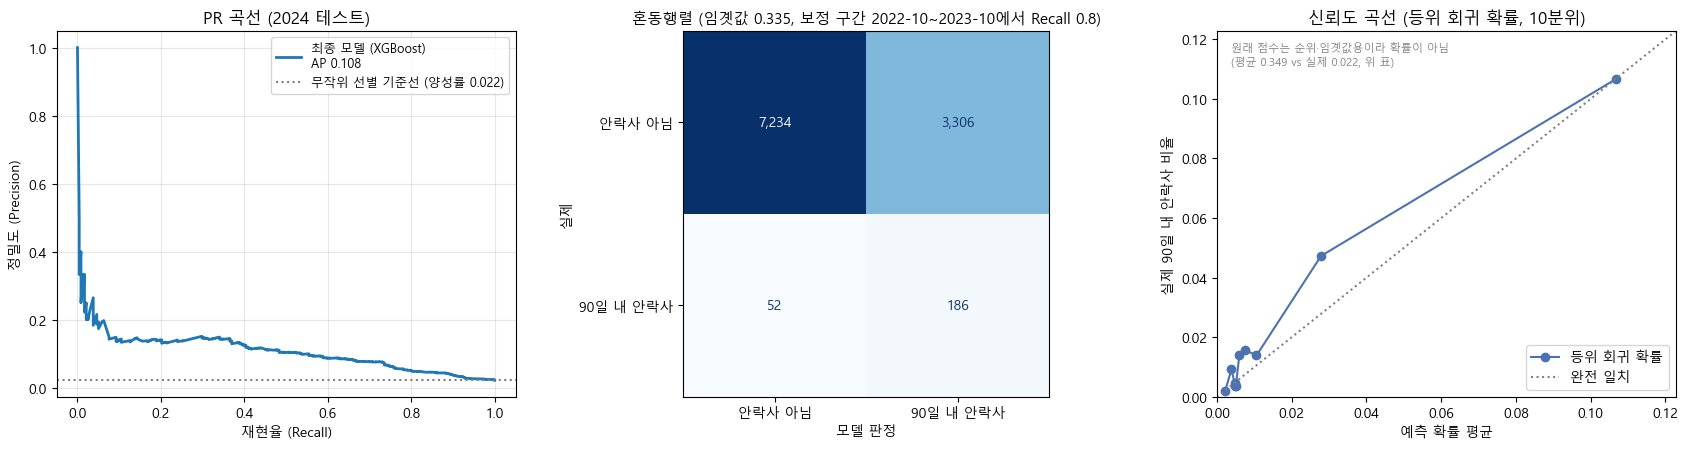

In [32]:
# 확률 보정 점검: 등위 회귀는 계단 함수라 동점을 만들어 순위 지표가 바뀔 수 있음
calib_check = pd.DataFrame([
    {"점수": "원래 점수", "고유값 수": len(np.unique(p_test)), "AP": average_precision_score(y_test, p_test),
     "ROC-AUC": roc_auc_score(y_test, p_test), "평균 예측": p_test.mean(), "Brier": brier_score_loss(y_test, np.clip(p_test, 0, 1))},
    {"점수": "등위 회귀 보정", "고유값 수": len(np.unique(p_test_cal)), "AP": average_precision_score(y_test, p_test_cal),
     "ROC-AUC": roc_auc_score(y_test, p_test_cal), "평균 예측": p_test_cal.mean(), "Brier": brier_score_loss(y_test, p_test_cal)},
])
print(f"실제 양성률 {base:.4f}")
display(calib_check.round(4))
save_table(calib_check, "calibration_check.csv")
print("-> 운영 순위·임곗값은 원래 점수로 정하고, 보정 확률은 '대략적인 위험 확률' 표시용으로만 사용합니다.")

CAL_TXT = f"{cal_df['t_in'].min():%Y-%m}~{cal_df['t_in'].max():%Y-%m}"   # 보정 구간(기간) 표시용
FAM_SHORT = FAMILY_LABEL[FINAL_FAMILY].split(" (")[0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[0].plot(rec, prec, lw=2, label=f"최종 모델 ({FAM_SHORT})\nAP {average_precision_score(y_test, p_test):.3f}")
axes[0].axhline(base, color="gray", ls=":", label=f"무작위 선별 기준선 (양성률 {base:.3f})")
axes[0].set_xlabel("재현율 (Recall)"); axes[0].set_ylabel("정밀도 (Precision)"); axes[0].legend(fontsize=9); axes[0].grid(alpha=.3)
axes[0].set_title("PR 곡선 (2024 테스트)")
ConfusionMatrixDisplay(confusion_matrix(y_test, flag.astype(int)), display_labels=["안락사 아님", "90일 내 안락사"]).plot(
    ax=axes[1], cmap="Blues", values_format=",d", colorbar=False)
axes[1].set_xlabel("모델 판정"); axes[1].set_ylabel("실제")
axes[1].set_title(f"혼동행렬 (임곗값 {THR80:.3f}, 보정 구간 {CAL_TXT}에서 Recall 0.8)", fontsize=11); axes[1].grid(False)
# 신뢰도 곡선은 확률로 읽는 등위 회귀 확률만 그림 (원래 점수는 순위·임곗값용이라 확률이 아님, 수치는 위 표)
bins = pd.qcut(pd.Series(p_test).rank(method="first"), 10, labels=False)
g = pd.DataFrame({"p": p_test_cal, "y": y_test, "b": bins}).groupby("b").mean()
axes[2].plot(g["p"], g["y"], marker="o", color="#4C72B0", label="등위 회귀 확률")
lim = float(max(0.05, g[["p", "y"]].to_numpy().max() * 1.15))
axes[2].plot([0, lim], [0, lim], ls=":", color="gray", label="완전 일치"); axes[2].set_xlim(0, lim); axes[2].set_ylim(0, lim)
axes[2].set_title("신뢰도 곡선 (등위 회귀 확률, 10분위)"); axes[2].set_xlabel("예측 확률 평균"); axes[2].set_ylabel("실제 90일 내 안락사 비율")
axes[2].legend(loc="lower right")
axes[2].text(0.03, 0.97, f"원래 점수는 순위·임곗값용이라 확률이 아님\n(평균 {p_test.mean():.3f} vs 실제 {base:.3f}, 위 표)",
             transform=axes[2].transAxes, va="top", fontsize=8, color="gray")
plt.tight_layout(); savefig("01_test_pr_confusion_calibration.png"); plt.show()

### 11-1. 여러 선별 규모에서의 운영 지표
검토 인력·예산이 주어지지 않았으므로 하나의 "최적" 기준을 정하지 않고, 선별 비율별 결과를 보여줍니다. 각 비율의 임곗값은 **보정 구간 점수 분포**에서 정하고 테스트에 그대로 적용합니다(그래서 테스트의 실제 선별 비율은 목표와 다를 수 있음).

In [33]:
months = test_df["t_in"].dt.to_period("M").nunique()
op_rows = []
for q in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    thr = np.quantile(p_cal, 1 - q)
    f = p_test >= thr
    tp_ = int((f & (y_test == 1)).sum())
    op_rows.append({"목표 선별 비율(보정 구간)": q, "테스트 실제 선별 비율": f.mean(), "선별 건수": int(f.sum()),
                    "월평균 검토 건수": f.sum() / months, "포착 양성": tp_, "놓친 양성": int(y_test.sum()) - tp_,
                    "Precision": tp_ / max(f.sum(), 1), "Recall": tp_ / y_test.sum(), "양성 1건당 검토 건수": f.sum() / max(tp_, 1)})
op_table = pd.DataFrame(op_rows)
display(op_table.round(3))
save_table(op_table, "operating_points.csv")

,목표 선별 비율(보정 구간),테스트 실제 선별 비율,선별 건수,월평균 검토 건수,포착 양성,놓친 양성,Precision,Recall,양성 1건당 검토 건수
0,0.05,0.060,643,53.583,88,150,0.137,0.370,7.307
1,0.10,0.119,1281,106.750,128,110,0.100,0.538,10.008
2,0.15,0.175,1887,157.250,156,82,0.083,0.655,12.096
3,0.20,0.223,2406,200.500,175,63,0.073,0.735,13.749
4,0.25,0.269,2897,241.417,180,58,0.062,0.756,16.094
5,0.30,0.315,3391,282.583,186,52,0.055,0.782,18.231


### 11-1b. 비용 관점의 운영점
검토 1건의 비용을 1로, **놓친 90일 이내 안락사 1건의 비용을 r**로 둡니다. r마다 **보정 구간**에서 기대 비용(검토 건수 + r × 놓친 양성)이 가장 작은 임곗값을 정하고 테스트에 그대로 적용합니다. r은 보호소가 정할 값이라 하나를 고르지 않습니다. 비교 기준은 "아무도 검토하지 않음"(비용 r × 양성 수)과 "전부 검토"(비용 = 입소 수)입니다. 검토가 안락사를 실제로 막는지는 이 데이터로 알 수 없으므로, 이 표는 의사결정 틀을 보여주는 것입니다.

In [34]:
# 11-1b. 비용 관점 운영점: "놓친 90일 이내 안락사 1건의 비용 = 검토 1건 비용의 r배"라고 둘 때,
# 보정 구간에서 기대 비용(검토 건수 + r × 놓친 양성)이 가장 작은 임곗값을 정하고 테스트에 그대로 적용합니다.
# r은 보호소가 정할 값이므로 하나를 고르지 않고 여러 값을 보여줍니다. 검토가 이득인 손익분기 Precision은 1/r입니다.
COST_RATIOS = [2, 5, 10, 20, 50, 100]


def min_cost_threshold(y, p, r):
    order = np.argsort(-p, kind="mergesort")
    ps, ys = p[order], y[order]
    n = len(p)
    cum_pos = np.r_[0, np.cumsum(ys)]
    k = np.arange(n + 1)
    cost = k + r * (ys.sum() - cum_pos)
    valid = np.ones(n + 1, dtype=bool)
    valid[1:n] = ps[:-1] != ps[1:]            # 같은 점수 사이에서는 자르지 않음
    kb = k[valid][np.argmin(cost[valid])]
    return np.inf if kb == 0 else ps[kb - 1]


n_te, P_te = len(y_test), int(y_test.sum())
cost_rows = []
for r in COST_RATIOS:
    thr = min_cost_threshold(y_cal, p_cal, r)
    f_cal, f = p_cal >= thr, p_test >= thr
    tp_ = int((f & (y_test == 1)).sum())
    cost_model = f.sum() + r * (P_te - tp_)
    cost_rows.append({"비용 비율 r (놓침/검토)": r, "손익분기 Precision (1/r)": 1 / r, "보정 구간 선별 비율": f_cal.mean(),
                      "테스트 선별 비율": f.mean(), "검토 건수": int(f.sum()), "포착 양성": tp_, "놓친 양성": P_te - tp_,
                      "Recall": tp_ / P_te, "Precision": tp_ / max(f.sum(), 1),
                      "100건당 비용 (모델)": 100 * cost_model / n_te, "100건당 비용 (검토 안 함)": 100 * r * P_te / n_te,
                      "100건당 비용 (전부 검토)": 100.0,
                      "가장 나은 단순 전략 대비 절감": 1 - cost_model / min(r * P_te, n_te)})
cost_table = pd.DataFrame(cost_rows)
display(cost_table.round(3))
save_table(cost_table, "cost_analysis.csv")
print("임곗값은 보정 구간에서만 정했고, 테스트 결과로 다시 고르지 않았습니다. 비용 단위는 '검토 1건'입니다.")

,비용 비율 r (놓침/검토),손익분기 Precision (1/r),보정 구간 선별 비율,테스트 선별 비율,검토 건수,포착 양성,놓친 양성,Recall,Precision,100건당 비용 (모델),100건당 비용 (검토 안 함),100건당 비용 (전부 검토),가장 나은 단순 전략 대비 절감
0,2,0.50,0.000,0.001,6,2,236,0.008,0.333,4.435,4.416,100.0,-0.004
1,5,0.20,0.000,0.001,6,2,236,0.008,0.333,11.004,11.041,100.0,0.003
2,10,0.10,0.033,0.036,387,51,187,0.214,0.132,20.941,22.082,100.0,0.052
3,20,0.05,0.075,0.091,976,108,130,0.454,0.111,33.179,44.164,100.0,0.249
4,50,0.02,0.187,0.211,2274,173,65,0.727,0.076,51.253,110.410,100.0,0.487
5,100,0.01,0.187,0.211,2274,173,65,0.727,0.076,81.407,220.820,100.0,0.186


임곗값은 보정 구간에서만 정했고, 테스트 결과로 다시 고르지 않았습니다. 비용 단위는 '검토 1건'입니다.


In [35]:
from scipy.stats import beta as _beta


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    ph = k / n
    d = 1 + z ** 2 / n
    c = (ph + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z ** 2 / (4 * n ** 2)) / d
    return (c - h, c + h)


mt = test_df.assign(p=p_test, f=p_test >= THR80, m=test_df["t_in"].dt.month)
mrows = []
for m_, g in mt.groupby("m"):
    k, n = int((g["f"] & (g["y_euth"] == 1)).sum()), int(g["y_euth"].sum())
    lo, hi = wilson(k, n)
    mrows.append({"월": m_, "입소": len(g), "검토 대상(선별)": int(g["f"].sum()), "양성": n, "포착": k,
                  "Recall": k / n if n else np.nan, "Recall 95% CI (Wilson)": f"[{lo:.2f}, {hi:.2f}]"})
monthly = pd.DataFrame(mrows)
display(monthly.round(3))
save_table(monthly, "monthly_test.csv")
print("월별 구간은 월별 양성 수가 적어 넓습니다. 동물 단위 군집은 반영하지 않은 근사입니다.")

,월,입소,검토 대상(선별),양성,포착,Recall,Recall 95% CI (Wilson)
0,1,684,212,13,11,0.846,"[0.58, 0.96]"
1,2,780,242,18,17,0.944,"[0.74, 0.99]"
2,3,792,267,13,10,0.769,"[0.50, 0.92]"
3,4,1113,300,10,6,0.600,"[0.31, 0.83]"
4,5,1358,438,34,23,0.676,"[0.51, 0.81]"
5,6,1022,357,19,14,0.737,"[0.51, 0.88]"
6,7,859,352,19,16,0.842,"[0.62, 0.94]"
7,8,819,294,17,14,0.824,"[0.59, 0.94]"
8,9,927,304,21,16,0.762,"[0.55, 0.89]"
9,10,972,310,26,19,0.731,"[0.54, 0.86]"


월별 구간은 월별 양성 수가 적어 넓습니다. 동물 단위 군집은 반영하지 않은 근사입니다.


### 11-2. 민감도 분석
모든 행은 같은 계열·전략·파라미터를 쓰고, 다른 학습이 필요한 행은 임곗값도 보정 구간에서 다시 정합니다(테스트로 정하지 않음). 결과는 **보고용**이며 주 결과를 바꾸는 데 쓰지 않습니다.

In [36]:
sens = []
def add_sens(label, d, note):
    yy, pp = d["y_euth"].values, score(d[FEATS])
    sens.append({"분석": label, "n": len(d), "양성": int(yy.sum()), "양성률": yy.mean(),
                 "AP": average_precision_score(yy, pp), "배수": average_precision_score(yy, pp) / yy.mean(),
                 "ROC-AUC": roc_auc_score(yy, pp), "Recall@임곗값": ((pp >= THR80) & (yy == 1)).sum() / yy.sum(), "비고": note})

add_sens("주 분석", test_df, "퇴소 기록 없는 입소 = 0, 재방문 제외")
add_sens("퇴소 기록 없는 입소 제외", test_df[~test_df["no_record"]], f"제외 {int(test_df['no_record'].sum())}건")
add_sens("재방문 동물 포함", block(*TEST, exclude_returners=False), "운영 현실에 더 가까움")
add_sens("2024년 1~10월 입소로 제한", test_df[test_df["t_in"].dt.month <= 10], "2024년 결과 연결 비율이 다른 해보다 낮음")
add_sens("보조: 2025-01~관찰 완료분", supp_df, "v3에서 다른 목표로 열람한 기간")
sens_table = pd.DataFrame(sens)
display(sens_table.round(4))
save_table(sens_table, "sensitivity.csv")


def eval_setting(label, cat, num, data, note):
    # 같은 계열·전략·파라미터로 특성 또는 대상만 바꿔 학습 → 보정 구간에서 임곗값 → 테스트 (직접모델 기준)
    trn, calb, tst = train_before(CAL[0], data), block(*CAL, data=data), block(*TEST, data=data)
    m = fit_with_strategy(FINAL_IMB, trn, cat, num, "y_euth", FINAL_PARAMS)
    pc, pt = m.predict_proba(calb[cat + num])[:, 1], m.predict_proba(tst[cat + num])[:, 1]
    thr = thr_for_recall(calb["y_euth"].values, pc, 0.8)
    yy = tst["y_euth"].values
    f = pt >= thr
    row = {"분석": label, "n": len(yy), "양성": int(yy.sum()), "양성률": yy.mean(), "AP": average_precision_score(yy, pt),
           "배수": average_precision_score(yy, pt) / yy.mean(), "ROC-AUC": roc_auc_score(yy, pt),
           "Recall@임곗값": (f & (yy == 1)).sum() / yy.sum(), "Precision@임곗값": (f & (yy == 1)).sum() / max(f.sum(), 1),
           "선별 비율": f.mean(), "비고": note}
    return row, pt, tst


r_name, p_name, t_name = eval_setting("이름 포함 (has_original_name 추가)", FINAL_CAT, FINAL_NUM + [NAME_VAR], lab, "v3 방식 특성")
assert (t_name.index == test_df.index).all()
bb = boot_metric(y_test, [p_name, p_test], g_test, average_precision_score)
NAME_DIFF = f"{(bb[:, 0] - bb[:, 1]).mean():+.4f} {ci_str(bb[:, 0] - bb[:, 1])}"
r_req, _, t_req = eval_setting("안락사 요청 입소 포함", FINAL_CAT, FINAL_NUM, lab_req, "v3 방식 대상")
r_edit, EDIT_DIFF = None, None
if edited_keys is not None:
    ek = lab.merge(edited_keys.assign(_e=1), on=["Animal ID", "t_in"], how="left")["_e"].notna().values
    r_edit, p_edit, t_edit = eval_setting("사후 수정된 입소 제외 (2021년판 대조)", FINAL_CAT, FINAL_NUM, lab[~ek], f"제외 {int(ek.sum())}건, 모두 2021-03 이전")
    assert (t_edit.index == test_df.index).all()
    be = boot_metric(y_test, [p_edit, p_test], g_test, average_precision_score)
    EDIT_DIFF = f"{(be[:, 0] - be[:, 1]).mean():+.4f} {ci_str(be[:, 0] - be[:, 1])}"
    print(f"주 분석 대상 중 사후 수정된 입소: {int(ek.sum())}건 (그중 안락사 {int(lab.loc[ek, 'y_euth'].sum())}건)")
    print("테스트 AP 차이 (수정 입소 제외 - 주 분석, 군집 부트스트랩):", EDIT_DIFF, "| 보고용, 선택에 쓰지 않음")
main_row = {"분석": "주 분석 (이름 제외, 요청 제외)", "n": len(y_test), "양성": int(y_test.sum()), "양성률": base,
            "AP": average_precision_score(y_test, p_test), "배수": average_precision_score(y_test, p_test) / base,
            "ROC-AUC": roc_auc_score(y_test, p_test), "Recall@임곗값": tp / y_test.sum(), "Precision@임곗값": tp / max(flag.sum(), 1),
            "선별 비율": flag.mean(), "비고": FINAL_NAME}
design_sens = pd.DataFrame([main_row, r_name, r_req] + ([r_edit] if r_edit is not None else []))
display(design_sens.round(4))
save_table(design_sens, "sensitivity_name_request.csv")
print("테스트 AP 차이 (이름 포함 - 제외, 군집 부트스트랩):", NAME_DIFF, "| 보고용, 선택에 쓰지 않음")
print(f"테스트 구간의 안락사 요청 입소: {int((t_req['Intake Type'] == 'Euthanasia Request').sum())}건")
if FINAL_STRUCT != "직접":
    print("주의: 위 민감도는 직접모델 기준으로 계산됨 (최종 구조는 2단계)")

ad_rows = []
for lab_, num_ in [("입양 모델 · 이름 제외", FINAL_NUM), ("입양 모델 · 이름 포함", FINAL_NUM + [NAME_VAR])]:
    am = make_model(FINAL_FAMILY, FINAL_CAT, num_, weighted=False, y=final_train["y_adopt"], **FINAL_PARAMS).fit(final_train[FINAL_CAT + num_], final_train["y_adopt"])
    ad_rows.append({"설정": lab_, "테스트 ROC-AUC (90일 이내 입양)": roc_auc_score(test_df["y_adopt"], am.predict_proba(test_df[FINAL_CAT + num_])[:, 1])})
adopt_name_sens = pd.DataFrame(ad_rows)
display(adopt_name_sens.round(4))
save_table(adopt_name_sens, "sensitivity_adoption_name.csv")

,분석,n,양성,양성률,AP,배수,ROC-AUC,Recall@임곗값,비고
0,주 분석,10778,238,0.0221,0.1077,4.8759,0.8109,0.7815,"퇴소 기록 없는 입소 = 0, 재방문 제외"
1,퇴소 기록 없는 입소 제외,10652,238,0.0223,0.1095,4.9028,0.8125,0.7815,제외 126건
2,재방문 동물 포함,11234,252,0.0224,0.1061,4.7316,0.8099,0.7857,운영 현실에 더 가까움
3,2024년 1~10월 입소로 제한,9326,190,0.0204,0.0973,4.7760,0.7998,0.7684,2024년 결과 연결 비율이 다른 해보다 낮음
4,보조: 2025-01~관찰 완료분,827,24,0.0290,0.1422,4.9002,0.8452,0.8333,v3에서 다른 목표로 열람한 기간


주 분석 대상 중 사후 수정된 입소: 591건 (그중 안락사 2건)
테스트 AP 차이 (수정 입소 제외 - 주 분석, 군집 부트스트랩): -0.0000 [-0.003, 0.005] | 보고용, 선택에 쓰지 않음


,분석,n,양성,양성률,AP,배수,ROC-AUC,Recall@임곗값,Precision@임곗값,선별 비율,비고
0,"주 분석 (이름 제외, 요청 제외)",10778,238,0.0221,0.1077,4.8759,0.8109,0.7815,0.0533,0.3240,XGBoost (부스팅) · 직접모델 · 가중치 · 이름 제외
1,이름 포함 (has_original_name 추가),10778,238,0.0221,0.1162,5.2610,0.8153,0.8025,0.0525,0.3375,v3 방식 특성
2,안락사 요청 입소 포함,10778,238,0.0221,0.1090,4.9353,0.8087,0.7773,0.0525,0.3271,v3 방식 대상
3,사후 수정된 입소 제외 (2021년판 대조),10778,238,0.0221,0.1075,4.8661,0.8093,0.7941,0.0520,0.3375,"제외 591건, 모두 2021-03 이전"


테스트 AP 차이 (이름 포함 - 제외, 군집 부트스트랩): +0.0091 [-0.009, 0.027] | 보고용, 선택에 쓰지 않음
테스트 구간의 안락사 요청 입소: 0건


,설정,테스트 ROC-AUC (90일 이내 입양)
0,입양 모델 · 이름 제외,0.7817
1,입양 모델 · 이름 포함,0.7827


### 11-2b. 성별·중성화 변수를 넣으면 (보고용)
6-4절 근거로 주 모델에서 뺀 성별·중성화 변수를 다시 넣은 결과(이전 주 모델의 특성 구성)를 같은 테스트 입소에서 비교합니다. (1) Unknown 입소를 학습·보정·테스트 모두에서 빼고 다시 학습, (2) 성별·중성화 변수를 빼고 다시 학습한 결과를 같은 테스트 입소에서 주 모델과 짝지어 비교합니다. **선택에 쓰지 않습니다.**

In [37]:
# 11-2b. 성별·중성화 변수를 넣으면 (보고용, 선택에 쓰지 않음)
# 6-4절 근거로 주 모델에서 뺀 두 변수를 다시 넣어, 이전 방식(Unknown 신호 포함)의 테스트 결과와 비교합니다.
SEX_VARS = ["sex", "sterilized_status"]
assert ((lab["sex"] == "Unknown") == (lab["sterilized_status"] == "Unknown")).all()
unk_desc = pd.DataFrame([{"구간": nm, "입소": len(d), "Unknown 건수": int((d["sex"] == "Unknown").sum()), "Unknown 비율": (d["sex"] == "Unknown").mean(),
                          "Unknown 중 90일 안락사율": d.loc[d["sex"] == "Unknown", "y_euth"].mean(),
                          "그 외 90일 안락사율": d.loc[d["sex"] != "Unknown", "y_euth"].mean()}
                         for nm, d in [("최종 학습 데이터", final_train), ("보정 구간", cal_df), ("2024 테스트", test_df)]])
display(unk_desc.round(4))
save_table(unk_desc, "unknown_describe.csv")

r_sx, p_sx, t_sx = eval_setting("성별·중성화 변수 포함 (Unknown 신호 포함)", FINAL_CAT + SEX_VARS, FINAL_NUM, lab, "이전 주 모델의 특성 구성")
assert (t_sx.index == test_df.index).all()
b_sx = boot_metric(y_test, [p_sx, p_test], g_test, average_precision_score)
SEX_DIFF = f"{(b_sx[:, 0] - b_sx[:, 1]).mean():+.4f} {ci_str(b_sx[:, 0] - b_sx[:, 1])}"
known_te = (test_df["sex"] != "Unknown").values
y_k, g_k = y_test[known_te], g_test[known_te]
b_k = boot_metric(y_k, [p_sx[known_te], p_test[known_te]], g_k, average_precision_score)
SEX_DIFF_KNOWN = f"{(b_k[:, 0] - b_k[:, 1]).mean():+.4f} {ci_str(b_k[:, 0] - b_k[:, 1])}"
unk_sens = pd.DataFrame([
    {"분석": "주 모델 (성별·중성화 제외) · 전체 테스트", "평가 n": len(y_test), "양성": int(y_test.sum()), "AP": average_precision_score(y_test, p_test),
     "ROC-AUC": roc_auc_score(y_test, p_test), "AP 차이 [95% CI]": "기준"},
    {"분석": "성별·중성화 포함 · 전체 테스트", "평가 n": len(y_test), "양성": int(y_test.sum()), "AP": average_precision_score(y_test, p_sx),
     "ROC-AUC": roc_auc_score(y_test, p_sx), "AP 차이 [95% CI]": SEX_DIFF},
    {"분석": "주 모델 · Unknown 아닌 테스트 입소만", "평가 n": int(known_te.sum()), "양성": int(y_k.sum()), "AP": average_precision_score(y_k, p_test[known_te]),
     "ROC-AUC": roc_auc_score(y_k, p_test[known_te]), "AP 차이 [95% CI]": "기준"},
    {"분석": "성별·중성화 포함 · Unknown 아닌 테스트 입소만", "평가 n": int(known_te.sum()), "양성": int(y_k.sum()), "AP": average_precision_score(y_k, p_sx[known_te]),
     "ROC-AUC": roc_auc_score(y_k, p_sx[known_te]), "AP 차이 [95% CI]": SEX_DIFF_KNOWN},
])
display(unk_sens.round(4))
save_table(unk_sens, "sensitivity_unknown.csv")
print("AP 차이 = 성별·중성화 포함 - 주 모델, 같은 테스트 입소에서 짝지은 동물 군집 부트스트랩. 보고용이며 선택에 쓰지 않습니다.")

,구간,입소,Unknown 건수,Unknown 비율,Unknown 중 90일 안락사율,그 외 90일 안락사율
0,최종 학습 데이터,132997,4630,0.0348,0.0851,0.0264
1,보정 구간,10197,322,0.0316,0.0621,0.0148
2,2024 테스트,10778,437,0.0405,0.0481,0.0210


,분석,평가 n,양성,AP,ROC-AUC,AP 차이 [95% CI]
0,주 모델 (성별·중성화 제외) · 전체 테스트,10778,238,0.1077,0.8109,기준
1,성별·중성화 포함 · 전체 테스트,10778,238,0.1271,0.8136,"+0.0187 [-0.000, 0.044]"
2,주 모델 · Unknown 아닌 테스트 입소만,10341,217,0.0958,0.8057,기준
3,성별·중성화 포함 · Unknown 아닌 테스트 입소만,10341,217,0.0968,0.8073,"+0.0012 [-0.008, 0.009]"


AP 차이 = 성별·중성화 포함 - 주 모델, 같은 테스트 입소에서 짝지은 동물 군집 부트스트랩. 보고용이며 선택에 쓰지 않습니다.


### 11-2c. 계열별 최고 조합의 2024 테스트 결과 (보고용)
계열 선택은 10-2절 검증 결과로 끝났습니다. 검증에서의 우위가 테스트에서도 보이는지 투명하게 보고하기 위한 표이며, **이 표로 다시 고르지 않습니다.**

In [38]:
# 11-2c. 같은 예산 튜닝 후 계열별 최고 조합의 2024 테스트 결과 (보고용)
# 계열 선택은 10-2절 검증 결과로 이미 끝났습니다. 이 표로 다시 고르지 않으며, 검증 우위가 테스트에서도 보이는지 투명하게 보고하기 위한 것입니다.
ref_rows = []
for _, r_ in fam_best.iterrows():
    fam, st_, prm = r_["kind"], r_["전략"], cand_by[r_["kind"]][int(r_["i"])]
    is_final = (fam == FINAL_FAMILY and st_ == FINAL_IMB and prm == FINAL_PARAMS and FINAL_STRUCT == "직접")
    if is_final:
        pt = p_test
    else:
        m_ = fit_with_strategy(st_, final_train, FINAL_CAT, FINAL_NUM, "y_euth", prm, family=fam, cache_key=("final",))
        pt = m_.predict_proba(test_df[FEATS])[:, 1]
    b_ = boot_metric(y_test, [pt, p_test], g_test, average_precision_score)
    ref_rows.append({"계열": r_["계열"], "전략": st_, "후보": r_["후보"], "검증 평균 AP": r_["평균 AP"],
                     "테스트 AP": average_precision_score(y_test, pt), "테스트 AP 95% CI (군집)": ci_str(b_[:, 0]),
                     "테스트 ROC-AUC": roc_auc_score(y_test, pt),
                     "최종 모델 대비 테스트 AP 차이 [95% CI]": "기준 (최종 모델)" if is_final else f"{(b_[:, 0] - b_[:, 1]).mean():+.4f} {ci_str(b_[:, 0] - b_[:, 1])}"})
family_test_ref = pd.DataFrame(ref_rows)
display(family_test_ref.round(4))
save_table(family_test_ref, "test_family_reference.csv")
print("보고용: 선택은 검증 폴드로만 했고, 이 테스트 비교로 결론을 바꾸지 않습니다.")

,계열,전략,후보,검증 평균 AP,테스트 AP,테스트 AP 95% CI (군집),테스트 ROC-AUC,최종 모델 대비 테스트 AP 차이 [95% CI]
0,XGBoost (부스팅),가중치,조합8,0.1772,0.1077,"[0.087, 0.143]",0.8109,기준 (최종 모델)
1,MLP 신경망,가중치 없음,조합5,0.1658,0.1001,"[0.082, 0.130]",0.8088,"-0.0083 [-0.021, 0.002]"
2,LightGBM (부스팅),가중치 없음,조합1,0.1649,0.1039,"[0.083, 0.132]",0.8121,"-0.0046 [-0.020, 0.007]"


보고용: 선택은 검증 폴드로만 했고, 이 테스트 비교로 결론을 바꾸지 않습니다.


## 12. 비교 가능한 범위의 수정 전후 비교
### 12-1. 무작위 분할 vs 시점 분할
같은 라벨(90일)과 같은 최종 설정으로, 관찰 완료된 2013-10 ~ 2024-12 개·고양이 입소를 **동물 ID 무작위 8:2**로 나눈 결과와 비교합니다. 두 결과의 차이에는 **분할 방식**뿐 아니라 **평가 시기, 표본 구성, 양성률, 학습 데이터 양과 시기**가 함께 섞여 있으므로, 차이를 분할 방식 하나의 효과로 단정하지 않습니다.

In [39]:
pool = lab[lab["t_in"] < TEST[1]]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
ri, rj = next(gss.split(pool, groups=pool["Animal ID"]))
r_tr, r_te = pool.iloc[ri], pool.iloc[rj]
if FINAL_STRUCT == "직접":
    rm = fit_with_strategy(FINAL_IMB, r_tr, FINAL_CAT, FINAL_NUM, "y_euth", FINAL_PARAMS)
    r_score = lambda X: rm.predict_proba(X)[:, 1]
else:
    rms = fit_two_stage(r_tr, FINAL_CAT, FINAL_NUM)
    r_score = lambda X: two_stage_score(rms, X)
pr_r = r_score(r_te[FEATS])
r24 = r_te["t_in"] >= T_DEPLOY
def lift_fn(y, p, sample_weight):
    # 재표본마다 AP와 양성률을 함께 다시 계산한 기준선 대비 배수
    return average_precision_score(y, p, sample_weight=sample_weight) / np.average(y, weights=sample_weight)


rows = []
for lab_, yy, pp, gg, n_tr in [("무작위 분할 · 전체 평가", r_te["y_euth"].values, pr_r, r_te["Animal ID"].values, len(r_tr)),
                               ("무작위 분할 · 평가 중 2024 입소만", r_te.loc[r24, "y_euth"].values, pr_r[r24.values], r_te.loc[r24, "Animal ID"].values, len(r_tr)),
                               ("시점 분할 (주 분석)", y_test, p_test, g_test, len(final_train))]:
    ap = average_precision_score(yy, pp)
    b_ap = boot_metric(yy, [pp], gg, average_precision_score)[:, 0]
    b_lf = boot_metric(yy, [pp], gg, lift_fn)[:, 0]
    rows.append({"설정": lab_, "학습 n": n_tr, "평가 n": len(yy), "양성 수": int(yy.sum()), "양성률": yy.mean(),
                 "AP": ap, "AP 95% CI (군집)": ci_str(b_ap), "기준선 대비 배수": ap / yy.mean(),
                 "배수 95% CI (군집)": f"[{np.percentile(b_lf, 2.5):.2f}, {np.percentile(b_lf, 97.5):.2f}]",
                 "ROC-AUC": roc_auc_score(yy, pp)})
split_cmp = pd.DataFrame(rows)
print("신뢰구간: 동물 ID 군집 부트스트랩 B =", B_BOOT, "| 행마다 따로 재표본 (서로 다른 모델·표본이라 짝지은 차이는 계산하지 않음)")
display(split_cmp.round(4))
a_r, a_t = split_cmp.iloc[0], split_cmp.iloc[2]
AP_RATIO = a_r["AP"] / a_t["AP"]
LIFT_RATIO = a_r["기준선 대비 배수"] / a_t["기준선 대비 배수"]
print(f"AP 원값 비율 (무작위/시점) = {a_r['AP']:.4f} / {a_t['AP']:.4f} = {AP_RATIO:.2f}")
print(f"기준선 대비 배수의 비율 (무작위/시점) = {a_r['기준선 대비 배수']:.2f} / {a_t['기준선 대비 배수']:.2f} = {LIFT_RATIO:.2f}")
print("-> 두 비율은 서로 다른 값입니다. 어느 쪽을 인용하는지 항상 함께 적습니다.")
save_table(split_cmp, "split_comparison.csv")

신뢰구간: 동물 ID 군집 부트스트랩 B = 500 | 행마다 따로 재표본 (서로 다른 모델·표본이라 짝지은 차이는 계산하지 않음)


,설정,학습 n,평가 n,양성 수,양성률,AP,AP 95% CI (군집),기준선 대비 배수,배수 95% CI (군집),ROC-AUC
0,무작위 분할 · 전체 평가,128074,32045,870,0.0271,0.2206,"[0.195, 0.249]",8.1251,"[7.26, 9.13]",0.8452
1,무작위 분할 · 평가 중 2024 입소만,128074,2250,46,0.0204,0.1195,"[0.067, 0.191]",5.8458,"[3.59, 9.55]",0.8365
2,시점 분할 (주 분석),132997,10778,238,0.0221,0.1077,"[0.087, 0.143]",4.8759,"[4.05, 6.31]",0.8109


AP 원값 비율 (무작위/시점) = 0.2206 / 0.1077 = 2.05
기준선 대비 배수의 비율 (무작위/시점) = 8.13 / 4.88 = 1.67
-> 두 비율은 서로 다른 값입니다. 어느 쪽을 인용하는지 항상 함께 적습니다.


### 12-2. v3 결과와의 관계
v3와 v4는 **예측 목표**(최종 결과 vs 90일 이내), **학습 데이터의 시점 조건**, **미연결 입소 처리**, **선택 절차**가 모두 달라 수치를 직접 비교할 수 없습니다. 차이가 어디서 오는지 보기 위해 v4 코드로 **v3 방식을 재현**한 결과를 함께 둡니다(기본 LightGBM, 가중치 있음).

In [40]:
v3_rows = []
v3_sum = os.path.join("figures_v3", "paper_summary.csv")
if os.path.exists(v3_sum):
    s3 = pd.read_csv(v3_sum)
    v3_rows.append({"설정": "v3 노트북 보고값 (파일에서 읽음)", "목표": "최종 결과 안락사",
                    "AP·배수·ROC": "; ".join(s3.loc[s3["항목"].str.contains("안락사 PR-AUC|안락사 ROC-AUC"), "결과"])})
v3d = dc_full[dc_full["link_status"] == "연결"].copy()
v3d["yr"] = v3d["t_in"].dt.year
tr3 = v3d[v3d["yr"] <= 2022]
te3 = v3d[v3d["yr"] == 2024]
te3 = te3[~te3["Animal ID"].isin(dc_full.loc[dc_full["t_in"] < T_DEPLOY, "Animal ID"])]
V3F = BASE_CAT + BASE_NUM + [NAME_VAR]
m3 = make_model("LGBM", BASE_CAT, BASE_NUM + [NAME_VAR], weighted=True).fit(tr3[V3F], tr3["y_final_euth"])
p3 = m3.predict_proba(te3[V3F])[:, 1]
ap3 = average_precision_score(te3["y_final_euth"], p3)
v3_rows.append({"설정": "v3 방식 재현 (v4 코드: 연결된 입소만, 입소 연도 분할, 최종 결과 라벨)", "목표": "최종 결과 안락사",
                "AP·배수·ROC": f"AP {ap3:.3f} · {ap3/te3['y_final_euth'].mean():.1f}배 · ROC {roc_auc_score(te3['y_final_euth'], p3):.3f} (n={len(te3)})"})
v3_rows.append({"설정": "최종본 주 분석", "목표": f"{W_DAYS}일 이내 안락사",
                "AP·배수·ROC": f"AP {main_result['AP'].iloc[0]:.3f} · {main_result['기준선 대비 배수'].iloc[0]:.1f}배 · ROC {main_result['ROC-AUC'].iloc[0]:.3f} (n={len(y_test)})"})
v3_compare = pd.DataFrame(v3_rows)
display(v3_compare)
save_table(v3_compare, "v3_final_relation.csv")

,설정,목표,AP·배수·ROC
0,v3 노트북 보고값 (파일에서 읽음),최종 결과 안락사,"0.137 [0.106, 0.179] · 기준선 0.023 · 5.9배; 0.832..."
1,"v3 방식 재현 (v4 코드: 연결된 입소만, 입소 연도 분할, 최종 결과 라벨)",최종 결과 안락사,AP 0.118 · 5.1배 · ROC 0.823 (n=10651)
2,최종본 주 분석,90일 이내 안락사,AP 0.108 · 4.9배 · ROC 0.811 (n=10778)


## 13. 운영 가설: 입양 가능성 × 안락사 위험 두 축
- **입양 축 기준값**: 보정 구간(2022-10 ~ 2023-10 입소)의 **실제 90일 이내 입양률**입니다. 보정된 입양 확률이 이 값보다 낮으면 "평균보다 입양 가능성이 낮은 동물"이 됩니다. 테스트를 보지 않고 정해지며, 0.3·0.7에서의 결과는 민감도로만 보여줍니다.
- 입양 모델도 입소 시점 운영 도구이므로 **이름 변수를 뺀 특성**을 씁니다.
- "운영 제안" 열은 **모델 결과가 아니라 제안**입니다. 위험군을 찾는 예측 성능과, 개입이 안락사를 줄이는 인과적 효과는 별개이며 후자는 이 데이터로 검증할 수 없습니다.

In [41]:
adopt_model = make_model(FINAL_FAMILY, FINAL_CAT, FINAL_NUM, weighted=False, y=final_train["y_adopt"], **FINAL_PARAMS)
adopt_model.fit(final_train[FEATS], final_train["y_adopt"])
iso_a = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(adopt_model.predict_proba(cal_df[FEATS])[:, 1], cal_df["y_adopt"])
pa_test = iso_a.predict(adopt_model.predict_proba(test_df[FEATS])[:, 1])
ADOPT_CUT = float(cal_df["y_adopt"].mean())
print(f"입양(90일) 모델 테스트 ROC-AUC {roc_auc_score(test_df['y_adopt'], pa_test):.3f} | 입양 축 기준값 = 보정 구간 실제 90일 입양률 {ADOPT_CUT:.4f}")
SUGGEST = {("낮음", "선별"): "제안: 의료·행동 평가와 이송 파트너 연계를 먼저 검토",
           ("높음", "선별"): "제안: 의료 스크리닝 후 입양 연계 검토",
           ("낮음", "비선별"): "제안: 입양 홍보·임시보호 검토",
           ("높음", "비선별"): "제안: 일반 관리"}
quad_main = pd.DataFrame({"입양 가능성": np.where(pa_test < ADOPT_CUT, "낮음", "높음"), "안락사 위험": np.where(flag, "선별", "비선별"),
                          "y": y_test}, index=test_df.index)


def two_axis_table(cut):
    q = pd.DataFrame({"입양 가능성": np.where(pa_test < cut, "낮음", "높음"), "안락사 위험": np.where(flag, "선별", "비선별"), "y": y_test})
    t = q.groupby(["입양 가능성", "안락사 위험"]).agg(동물수=("y", "size"), 양성=("y", "sum"))
    t["동물 비율"] = t["동물수"] / len(q)
    t["양성 중 차지 비율"] = t["양성"] / q["y"].sum()
    t["양성률"] = t["양성"] / t["동물수"]
    return t


two_axis_main = two_axis_table(ADOPT_CUT)
two_axis_main["운영 제안 (모델 결과 아님)"] = [SUGGEST[i] for i in two_axis_main.index]
display(two_axis_main.round(4))
save_table(two_axis_main.reset_index(), "two_axis_main.csv")
sens_cut = pd.concat({f"기준 {c}": two_axis_table(c).loc[("낮음", "선별"), ["동물 비율", "양성 중 차지 비율", "양성률"]] for c in [0.3, ADOPT_CUT, 0.7]}, axis=1).T
print("핵심 칸(입양 낮음 × 위험 선별)의 기준값 민감도:")
display(sens_cut.round(4))
save_table(sens_cut.reset_index().rename(columns={"index": "기준값"}), "two_axis_cutoff_sensitivity.csv")

입양(90일) 모델 테스트 ROC-AUC 0.782 | 입양 축 기준값 = 보정 구간 실제 90일 입양률 0.5594


동물수   양성   동물 비율  양성 중 차지 비율     양성률                운영 제안 (모델 결과 아님)
입양 가능성 안락사 위험                                                                       
낮음     비선별     2752   23  0.2553      0.0966  0.0084               제안: 입양 홍보·임시보호 검토
       선별      2891  160  0.2682      0.6723  0.0553  제안: 의료·행동 평가와 이송 파트너 연계를 먼저 검토
높음     비선별     4534   29  0.4207      0.1218  0.0064                       제안: 일반 관리
       선별       601   26  0.0558      0.1092  0.0433          제안: 의료 스크리닝 후 입양 연계 검토

핵심 칸(입양 낮음 × 위험 선별)의 기준값 민감도:


,동물 비율,양성 중 차지 비율,양성률
기준 0.3,0.1048,0.3655,0.0770
기준 0.5593802098656467,0.2682,0.6723,0.0553
기준 0.7,0.3170,0.7731,0.0538


## 14. 최종 모델 해석
선택된 최종 모델을 그대로 설명합니다. 트리 계열은 SHAP(TreeExplainer), 선형은 SHAP(LinearExplainer), 신경망은 보정 구간에서의 순열 중요도를 씁니다. 2단계가 선택되면 두 단계를 각각 설명합니다. **중요도와 SHAP 방향은 예측에 대한 연관성이며, 원인이나 개입 효과가 아닙니다.**

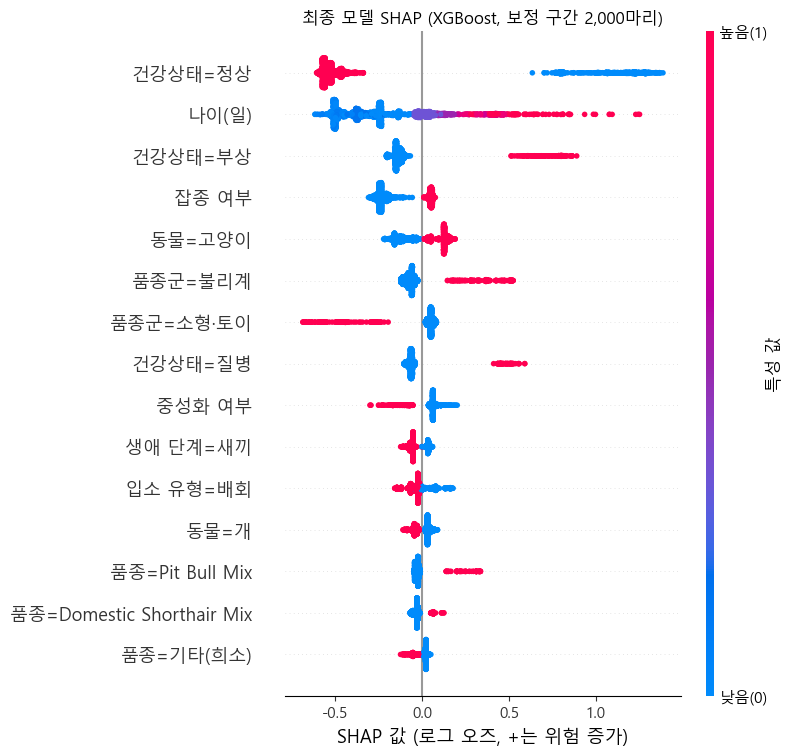

,특성,mean|SHAP|,값↑일 때 예측 방향
0,Intake Condition_Normal,0.6365,감소
1,age_days,0.3097,증가
2,Intake Condition_Injured,0.1815,증가
3,is_mixed_breed,0.1670,증가
4,animal_type_Cat,0.1184,증가
5,breed_group_불리계,0.1007,증가
6,breed_group_소형·토이,0.0828,감소
7,Intake Condition_Sick,0.0822,증가
8,is_sterilized,0.0714,감소
9,life_stage_새끼,0.0518,감소


In [42]:
# 그림 표시용 한글 이름 (표·저장값의 변수명은 원래 이름 그대로)
VAR_KO = {"Intake Condition": "건강상태", "Intake Type": "입소 유형", "animal_type": "동물", "breed_group": "품종군",
          "Breed": "품종", "Color": "털색", "life_stage": "생애 단계", "age_days": "나이(일)", "is_mixed_breed": "잡종 여부",
          "is_sterilized": "중성화 여부", "intake_month": "입소 월", "is_multicolor": "여러 색 여부",
          "intake_season": "입소 계절", "is_male": "수컷 여부"}
VAL_KO = {"Normal": "정상", "Injured": "부상", "Sick": "질병", "Nursing": "수유", "Neonatal": "신생", "Aged": "노령",
          "Stray": "배회", "Owner Surrender": "소유자 포기", "Public Assist": "공공 지원", "Abandoned": "유기",
          "Cat": "고양이", "Dog": "개", "infrequent_sklearn": "기타(희소)"}


def ko_col(c):
    f = max([v for v in VAR_KO if c == v or c.startswith(v + "_")], key=len, default=None)
    if f is None:
        return c
    return VAR_KO[f] if c == f else f"{VAR_KO[f]}={VAL_KO.get(c[len(f) + 1:], c[len(f) + 1:])}"


def ko_shap_texts():
    for t in plt.gcf().findobj(matplotlib.text.Text):
        s = t.get_text()
        s = {"Feature value": "특성 값", "High": "높음(1)", "Low": "낮음(0)"}.get(s, s)
        t.set_text(s.replace("SHAP value (impact on model output)", "SHAP 값 (로그 오즈, +는 위험 증가)").replace("−", "-"))
    for ax in plt.gcf().axes:   # 색 막대 눈금(Low/High)은 formatter가 다시 그리므로 직접 교체
        if [t.get_text() for t in ax.get_yticklabels()] == ["Low", "High"]:
            ax.set_yticklabels(["낮음(0)", "높음(1)"])


def explain(pipe, X_bg, X_ex, title, fname):
    prep, est = pipe.named_steps["prep"], pipe.named_steps["model"]
    if FINAL_FAMILY in TREE_FAMILIES or FINAL_FAMILY == "LR":
        Xb, Xe = prep.transform(X_bg), prep.transform(X_ex)
        expl = shap.TreeExplainer(est) if FINAL_FAMILY in TREE_FAMILIES else shap.LinearExplainer(est, Xb)
        sv = expl.shap_values(Xe)
        if isinstance(sv, list):
            sv = sv[1]
        sv = np.asarray(sv)
        if sv.ndim == 3:
            sv = sv[:, :, 1]
        shap.summary_plot(sv, Xe.rename(columns=ko_col), max_display=15, show=False)
        ko_shap_texts(); plt.title(title, fontsize=12); savefig(fname); plt.show()
        imp = pd.DataFrame({"특성": Xe.columns, "mean|SHAP|": np.abs(sv).mean(0)})
        with np.errstate(invalid="ignore", divide="ignore"):
            imp["값↑일 때 예측 방향"] = ["증가" if np.corrcoef(Xe[c].astype(float), sv[:, i])[0, 1] > 0 else "감소"
                                  if Xe[c].std() > 0 else "-" for i, c in enumerate(Xe.columns)]
        LAST_SHAP[fname] = (sv, Xe)
        return imp.sort_values("mean|SHAP|", ascending=False).head(10).reset_index(drop=True)
    r = permutation_importance(pipe, X_ex, cal_df.loc[X_ex.index, "y_euth"], scoring="average_precision", n_repeats=3, random_state=SEED)
    return pd.DataFrame({"특성": X_ex.columns, "AP 감소(순열)": r.importances_mean}).sort_values("AP 감소(순열)", ascending=False).head(10)


LAST_SHAP = {}
X_bg = final_train[FEATS].sample(1000, random_state=SEED)
X_ex = cal_df[FEATS].sample(min(2000, len(cal_df)), random_state=SEED)
if FINAL_STRUCT == "직접":
    imp_main = explain(final_model, X_bg, X_ex, f"최종 모델 SHAP ({FAMILY_LABEL[FINAL_FAMILY].split(' (')[0]}, 보정 구간 {len(X_ex):,}마리)", "02_final_model_explanation.png")
    display(imp_main.round(4))
else:
    imp_main = None
    display(explain(final_model[0], X_bg, X_ex, "1단계 (90일 이내 입양)", "02a_stage1_explanation.png").round(4))
    display(explain(final_model[1], X_bg, X_ex, "2단계 (안락사 | 비입양)", "02b_stage2_explanation.png").round(4))

In [43]:
if imp_main is not None and "값↑일 때 예측 방향" in imp_main.columns:
    up = [r_["특성"] for _, r_ in imp_main.iterrows() if r_["값↑일 때 예측 방향"] == "증가"]
    dn = [r_["특성"] for _, r_ in imp_main.iterrows() if r_["값↑일 때 예측 방향"] == "감소"]
    show_md([
        f"**결과 해석 (14, 자동 생성)**: 최종 모델({FINAL_NAME}) 자체를 설명했습니다. 평균 |SHAP| 상위 10개 원-핫 특성 중 "
        f"값이 1(또는 클수록)일 때 예측 위험을 높이는 것은 {', '.join(f'`{u}`' for u in up) or '없음'}, 낮추는 것은 {', '.join(f'`{d}`' for d in dn) or '없음'}입니다.",
        "원-핫 범주가 흩어져 있으므로 변수 단위 해석은 14-0절을 보세요. 이는 **예측에 대한 연관성**이며 원인이나 개입 효과가 아닙니다.",
    ])
else:
    show_md("최종 모델이 트리·선형 계열이 아니거나 2단계 구조라 SHAP 방향 요약을 생략했습니다(순열 중요도 표 참조).")

**결과 해석 (14, 자동 생성)**: 최종 모델(XGBoost (부스팅) · 직접모델 · 가중치 · 이름 제외) 자체를 설명했습니다. 평균 |SHAP| 상위 10개 원-핫 특성 중 값이 1(또는 클수록)일 때 예측 위험을 높이는 것은 `age_days`, `Intake Condition_Injured`, `is_mixed_breed`, `animal_type_Cat`, `breed_group_불리계`, `Intake Condition_Sick`, 낮추는 것은 `Intake Condition_Normal`, `breed_group_소형·토이`, `is_sterilized`, `life_stage_새끼`입니다.
원-핫 범주가 흩어져 있으므로 변수 단위 해석은 14-0절을 보세요. 이는 **예측에 대한 연관성**이며 원인이나 개입 효과가 아닙니다.

### 14-0. 원래 변수 단위로 합산한 SHAP
원-핫 인코딩 때문에 같은 변수(예: 건강상태)의 범주들이 위 그림에 흩어져 있습니다. SHAP 값은 더할 수 있으므로, **같은 원래 변수에서 나온 열의 SHAP을 개체마다 더해** 변수 단위 기여를 구합니다.
- **중요도**: 변수 단위 기여의 절댓값 평균.
- **방향**: 범주형은 범주별 평균 기여가 가장 높은 범주와 가장 낮은 범주(표본 30마리 이상인 범주만), 수치형은 값과 기여의 상관 부호.
- 설명 표본은 위와 같은 보정 구간 2,000마리입니다. 이 값도 **예측에 대한 연관성**이며 원인이나 개입 효과가 아닙니다.

,변수,원-핫 열 수,mean|SHAP| (합산),위험을 가장 높이는 범주 (평균 기여),위험을 가장 낮추는 범주 (평균 기여)
0,Intake Condition,17,0.8142,Injured (+1.945),Normal (-0.713)
1,age_days,1,0.3097,값이 클수록,값이 작을수록
2,is_mixed_breed,1,0.1670,값이 클수록,값이 작을수록
3,animal_type,2,0.1573,Cat (+0.154),Dog (-0.160)
4,breed_group,13,0.1087,불리계 (+0.416),소형·토이 (-0.541)
5,Breed,16,0.0726,Pit Bull Mix (+0.243),Chihuahua Shorthair (-0.051)
6,is_sterilized,1,0.0714,값이 작을수록,값이 클수록
7,Intake Type,5,0.0623,Public Assist (+0.114),Stray (-0.051)
8,life_stage,4,0.0616,노령 (+0.119),새끼 (-0.081)
9,intake_month,1,0.0121,값이 클수록,값이 작을수록


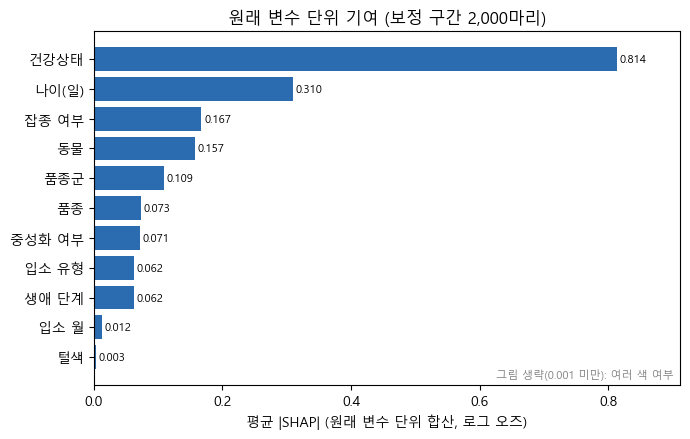

In [44]:
def shap_by_variable(sv, Xe, X_raw, feats, cat_feats, min_n=30):
    owner = {c: max([f for f in feats if c == f or c.startswith(f + "_")], key=len) for c in Xe.columns}
    agg = pd.DataFrame(sv, columns=Xe.columns, index=X_raw.index).T.groupby(pd.Series(owner)).sum().T
    rows = []
    for f in agg.columns:
        v = agg[f]
        row = {"변수": f, "원-핫 열 수": sum(1 for o in owner.values() if o == f), "mean|SHAP| (합산)": v.abs().mean()}
        if f in cat_feats:
            g = v.groupby(X_raw[f].astype(str)).agg(["mean", "size"])
            g = g[g["size"] >= min_n]
            row["위험을 가장 높이는 범주 (평균 기여)"] = f"{g['mean'].idxmax()} ({g['mean'].max():+.3f})" if len(g) else "-"
            row["위험을 가장 낮추는 범주 (평균 기여)"] = f"{g['mean'].idxmin()} ({g['mean'].min():+.3f})" if len(g) else "-"
        else:
            c_ = np.corrcoef(X_raw[f].astype(float), v)[0, 1] if X_raw[f].std() > 0 else np.nan
            row["위험을 가장 높이는 범주 (평균 기여)"] = "값이 클수록" if c_ > 0 else "값이 작을수록"
            row["위험을 가장 낮추는 범주 (평균 기여)"] = "값이 작을수록" if c_ > 0 else "값이 클수록"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("mean|SHAP| (합산)", ascending=False).reset_index(drop=True)


if FINAL_STRUCT == "직접" and "02_final_model_explanation.png" in LAST_SHAP:
    sv_, Xe_ = LAST_SHAP["02_final_model_explanation.png"]
    shap_var = shap_by_variable(sv_, Xe_, X_ex, FEATS, FINAL_CAT)
    display(shap_var.round(4))
    save_table(shap_var, "shap_by_variable.csv")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    tiny_ = shap_var["mean|SHAP| (합산)"] < 0.001          # 막대가 보이지 않는 변수는 그림에서만 생략 (표에는 있음)
    d_ = shap_var[~tiny_].iloc[::-1]
    bars_ = ax.barh(d_["변수"].map(lambda f: VAR_KO.get(f, f)), d_["mean|SHAP| (합산)"], color="#2b6cb0")
    ax.bar_label(bars_, fmt="%.3f", fontsize=8, padding=2)
    ax.set_xlim(0, d_["mean|SHAP| (합산)"].max() * 1.12)
    ax.set_xlabel("평균 |SHAP| (원래 변수 단위 합산, 로그 오즈)")
    ax.set_title(f"원래 변수 단위 기여 (보정 구간 {len(X_ex):,}마리)")
    if tiny_.any():
        ax.text(0.99, 0.02, "그림 생략(0.001 미만): " + ", ".join(VAR_KO.get(f, f) for f in shap_var.loc[tiny_, "변수"]),
                transform=ax.transAxes, ha="right", fontsize=8, color="gray")
    plt.tight_layout(); savefig("02b_shap_by_variable.png"); plt.show()
else:
    shap_var = None
    print("변수 단위 합산은 직접모델 + 트리·선형 계열에서만 계산합니다 (현재 설정에서는 생략).")

In [45]:
if shap_var is not None:
    sv_ = shap_var.reset_index(drop=True)
    top3 = sv_.head(6)
    low = sv_[sv_["mean|SHAP| (합산)"] < 0.1 * sv_["mean|SHAP| (합산)"].max()]["변수"].tolist()
    lead, second = sv_.iloc[0], sv_.iloc[1]
    cat_rows = sv_[sv_["변수"].isin(FINAL_CAT)]
    unk_up = [r_["변수"] for _, r_ in cat_rows.iterrows() if str(r_["위험을 가장 높이는 범주 (평균 기여)"]).startswith("Unknown")]
    lines = [
        "**결과 해석 (14-0, 자동 생성)**",
        f"- 변수 단위로 합치면 **{lead['변수']}의 기여가 {fx(lead['mean|SHAP| (합산)'])}**로 가장 크고"
        + (f"(2위 {second['변수']} {fx(second['mean|SHAP| (합산)'])}의 {lead['mean|SHAP| (합산)'] / second['mean|SHAP| (합산)']:.1f}배)" if second['mean|SHAP| (합산)'] > 0 else "")
        + ", 이어서 " + ", ".join(f"{r_['변수']}({fx(r_['mean|SHAP| (합산)'])})" for _, r_ in top3.iloc[1:].iterrows()) + " 순입니다."
        + (f" 최대값의 10% 미만인 변수: {', '.join(low)}." if low else ""),
        "- 범주형 변수에서 위험을 가장 높이는/낮추는 범주(평균 기여, 로그 오즈): "
        + "; ".join(f"{r_['변수']} — {r_['위험을 가장 높이는 범주 (평균 기여)']} / {r_['위험을 가장 낮추는 범주 (평균 기여)']}" for _, r_ in cat_rows.head(6).iterrows()) + ".",
    ]
    if unk_up:
        lines.append(f"- {', '.join(unk_up)}에서는 **'Unknown'이 위험을 가장 높이는 범주**입니다. 동물의 특성이라기보다 기록이 불완전한 입소를 반영한 신호일 수 있어 11-2b절에서 따로 점검했습니다.")
    lines.append("- 값은 개체별로 원-핫 열의 SHAP을 원래 변수로 먼저 더한 뒤 절댓값을 평균한 것입니다. 예측에 대한 연관성이며 원인이나 개입 효과가 아닙니다.")
    show_md(lines)

**결과 해석 (14-0, 자동 생성)**
- 변수 단위로 합치면 **Intake Condition의 기여가 0.814**로 가장 크고(2위 age_days 0.310의 2.6배), 이어서 age_days(0.310), is_mixed_breed(0.167), animal_type(0.157), breed_group(0.109), Breed(0.073) 순입니다. 최대값의 10% 미만인 변수: Breed, is_sterilized, Intake Type, life_stage, intake_month, Color, is_multicolor.
- 범주형 변수에서 위험을 가장 높이는/낮추는 범주(평균 기여, 로그 오즈): Intake Condition — Injured (+1.945) / Normal (-0.713); animal_type — Cat (+0.154) / Dog (-0.160); breed_group — 불리계 (+0.416) / 소형·토이 (-0.541); Breed — Pit Bull Mix (+0.243) / Chihuahua Shorthair (-0.051); Intake Type — Public Assist (+0.114) / Stray (-0.051); life_stage — 노령 (+0.119) / 새끼 (-0.081).
- 값은 개체별로 원-핫 열의 SHAP을 원래 변수로 먼저 더한 뒤 절댓값을 평균한 것입니다. 예측에 대한 연관성이며 원인이나 개입 효과가 아닙니다.

### 14-1. 개체 수준 사례 (선택 기준을 미리 고정)
사례를 골라 쓴 것처럼 보이지 않도록 선택 기준을 코드로 고정했습니다.
- **고위험 사례**: 2024 테스트 중 "입양 가능성 낮음 × 안락사 위험 선별" 칸에 속하면서 **실제로 90일 이내 안락사된** 개체들 가운데, **예측 점수가 그 집단의 중앙값에 가장 가까운** 1마리.
- **저위험 사례**: 2024 테스트 중 **선별되지 않은** 개체들 가운데, **예측 점수가 그 집단의 중앙값에 가장 가까운** 1마리 (실제 결과와 무관하게 선택).
- 워터폴의 값은 모델 출력(로그 오즈) 단위의 기여를 **원래 변수 단위로 합산**한 것이며(14-0절과 같은 방식), **원인이나 개입 효과가 아닙니다.**
- 제목의 모델 점수는 순위용이라 확률이 아니므로, 등위 회귀 보정 확률을 함께 적습니다.

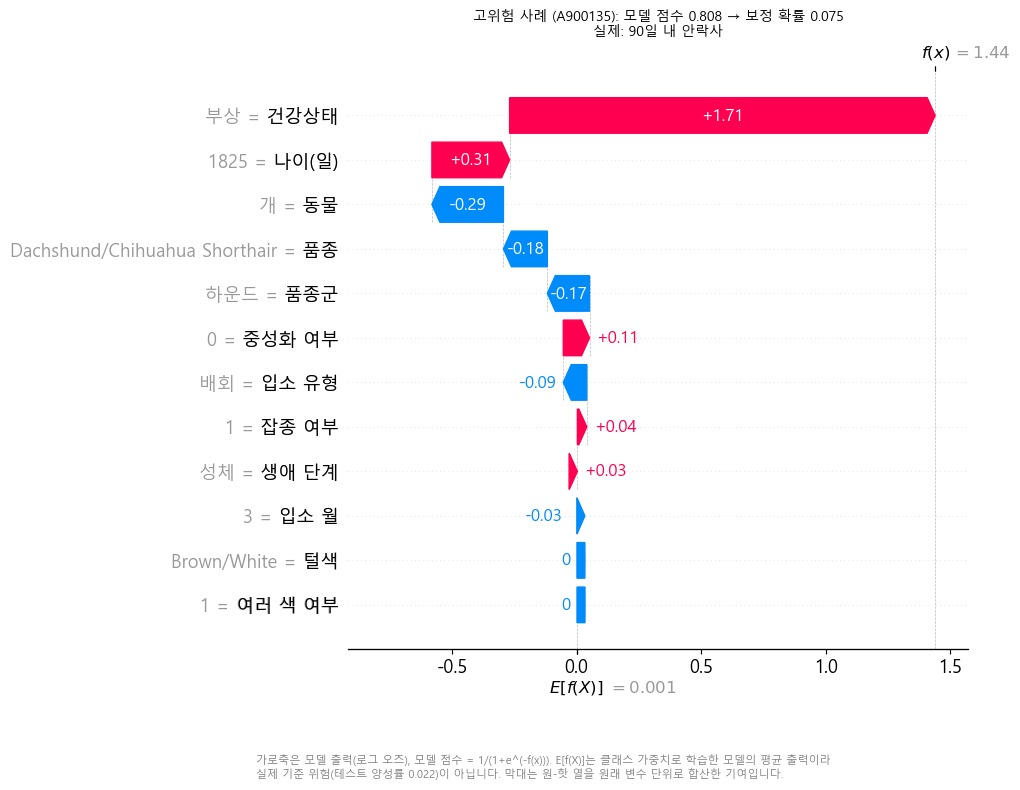

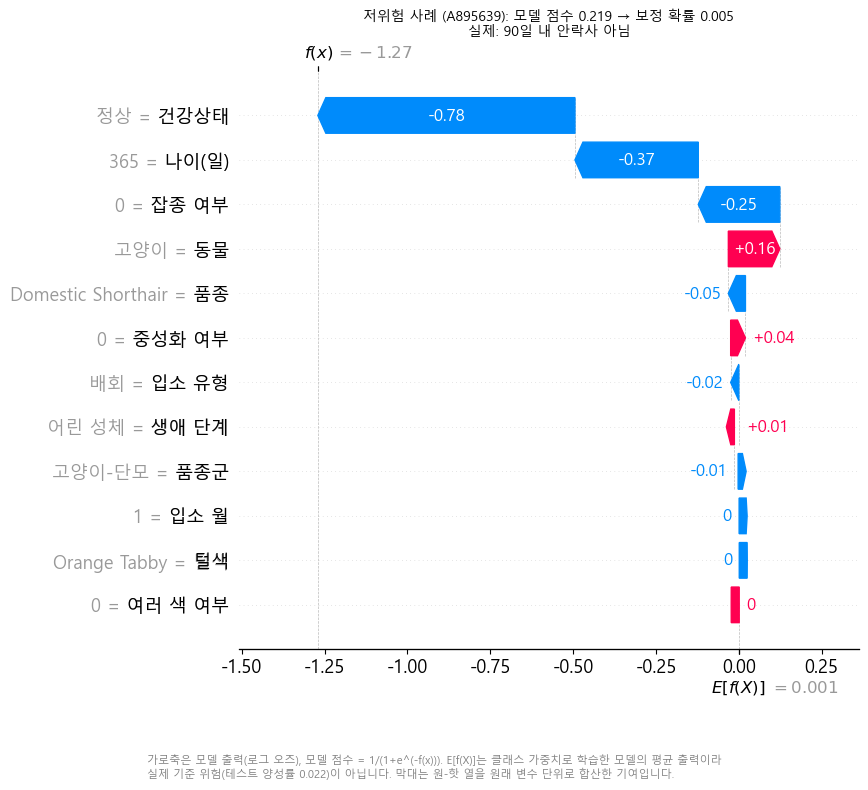

,사례,Animal ID,동물,입소 유형,건강상태,나이(일),점수,보정 입양 확률,90일 이내 안락사,최종 결과,선택 집단 크기
0,고위험_사례,A900135,Dog,Stray,Injured,1825,0.8084,0.3565,1,Euthanasia,160
1,저위험_사례,A895639,Cat,Stray,Normal,365,0.2192,0.4739,0,Adoption,7286


In [46]:
pt_s = pd.Series(p_test, index=test_df.index)


def pick_median(idx):
    s_ = pt_s.loc[idx]
    return (s_ - s_.median()).abs().idxmin()


hi_pool = quad_main.index[(quad_main["입양 가능성"] == "낮음") & (quad_main["안락사 위험"] == "선별") & (quad_main["y"] == 1)]
lo_pool = quad_main.index[quad_main["안락사 위험"] == "비선별"]
cases = {"고위험_사례": pick_median(hi_pool), "저위험_사례": pick_median(lo_pool)}
case_rows = []
if FINAL_STRUCT == "직접" and FINAL_FAMILY in TREE_FAMILIES:
    prep_f, est_f = final_model.named_steps["prep"], final_model.named_steps["model"]
    ex_f = shap.TreeExplainer(est_f)
    for tag, ridx in cases.items():
        Xi = prep_f.transform(test_df.loc[[ridx], FEATS])
        sv = ex_f.shap_values(Xi)
        sv = sv[1] if isinstance(sv, list) else sv
        sv = sv[:, :, 1] if np.ndim(sv) == 3 else sv
        ev = ex_f.expected_value
        ev = ev[1] if np.ndim(ev) > 0 else ev
        # 원-핫 열의 SHAP을 원래 변수로 합산 (합이 같으므로 f(x)는 그대로)
        own_ = pd.Series({c: max([f for f in FEATS if c == f or c.startswith(f + "_")], key=len) for c in Xi.columns})
        sv_var = pd.Series(sv[0], index=Xi.columns).groupby(own_).sum()
        raw_ = test_df.loc[ridx, list(sv_var.index)]
        data_ = np.array([VAL_KO.get(str(v), str(v)) if f in FINAL_CAT else v for f, v in raw_.items()], dtype=object)
        plt.figure()
        shap.plots.waterfall(shap.Explanation(values=sv_var.values, base_values=ev, data=data_,
                                              feature_names=[VAR_KO.get(f, f) for f in sv_var.index]),
                             max_display=len(sv_var) + 1, show=False)
        for t in plt.gcf().findobj(matplotlib.text.Text):   # 한글 폰트에 없는 유니코드 마이너스를 하이픈으로
            s = t.get_text().replace("−", "-")
            t.set_text("0" if s in ("-0", "+0") else s)
        cal_p = p_test_cal[test_df.index.get_loc(ridx)]
        y_ = int(test_df.loc[ridx, "y_euth"])
        plt.title(f"{tag.replace('_', ' ')} ({test_df.loc[ridx, 'Animal ID']}): 모델 점수 {pt_s[ridx]:.3f} → 보정 확률 {cal_p:.3f}\n"
                  f"실제: {'90일 내 안락사' if y_ else '90일 내 안락사 아님'}", fontsize=10)
        plt.gcf().text(0.01, -0.03, f"가로축은 모델 출력(로그 오즈), 모델 점수 = 1/(1+e^(-f(x))). E[f(X)]는 클래스 가중치로 학습한 모델의 평균 출력이라\n"
                       f"실제 기준 위험(테스트 양성률 {base:.3f})이 아닙니다. 막대는 원-핫 열을 원래 변수 단위로 합산한 기여입니다.",
                       fontsize=8, color="gray", va="top")
        savefig(f"03_{tag}_shap_waterfall.png")
        plt.show()
else:
    print("개체 워터폴은 직접모델 + 트리 계열에서만 생성합니다 (현재 설정에서는 생략).")
for tag, ridx in cases.items():
    r_ = test_df.loc[ridx]
    case_rows.append({"사례": tag, "Animal ID": r_["Animal ID"], "동물": r_["animal_type"], "입소 유형": r_["Intake Type"],
                      "건강상태": r_["Intake Condition"], "나이(일)": r_["age_days"], "점수": pt_s[ridx],
                      "보정 입양 확률": pa_test[test_df.index.get_loc(ridx)], "90일 이내 안락사": int(r_["y_euth"]),
                      "최종 결과": r_["Outcome Type"], "선택 집단 크기": len(hi_pool) if tag.startswith("고") else len(lo_pool)})
case_table = pd.DataFrame(case_rows)
display(case_table.round(4))
save_table(case_table, "shap_cases.csv")

In [47]:
ct = case_table.set_index("사례")
hi_, lo_ = ct.loc["고위험_사례"], ct.loc["저위험_사례"]
raw_mean = float(calib_check.iloc[0]["평균 예측"])
score_is_prob = abs(raw_mean - base) / base < 0.5      # 원래 점수 평균이 실제 비율과 가까울 때만 확률처럼 읽음


def age_txt(d):
    d = int(d)
    return f"약 {d / 365:.1f}세({d:,}일)" if d >= 365 else f"약 {d / 30.4:.0f}개월({d:,}일)"


show_md([
    "**결과 해석 (개체 사례, 자동 생성)**",
    f"- **고위험 사례 ({hi_['Animal ID']})**: 선택 집단 {int(hi_['선택 집단 크기']):,}마리(입양 가능성 낮음 × 위험 선별 × 실제 90일 이내 안락사) 중 점수 중앙값에 가장 가까운 개체입니다. "
    f"{age_txt(hi_['나이(일)'])}, 건강상태 {hi_['건강상태']}, 입소 유형 {hi_['입소 유형']}인 {hi_['동물']}이며, 모델 점수 {fx(hi_['점수'])}(임곗값 {fx(THR80)}), 보정 입양 확률 {fx(hi_['보정 입양 확률'])}, 최종 결과 {hi_['최종 결과']}입니다.",
    f"- **저위험 사례 ({lo_['Animal ID']})**: 선별되지 않은 {int(lo_['선택 집단 크기']):,}마리 중 점수 중앙값에 가장 가까운 개체입니다. "
    f"{age_txt(lo_['나이(일)'])}, 건강상태 {lo_['건강상태']}, 입소 유형 {lo_['입소 유형']}인 {lo_['동물']}이며, 점수 {fx(lo_['점수'])}, 최종 결과 {lo_['최종 결과']}입니다.",
    ("- 원래 점수의 평균이 실제 양성률과 가까워 대략적인 확률로 읽을 수 있지만, 확률 표시에는 11절의 보정 확률을 권합니다." if score_is_prob else
     f"- 최종 모델은 클래스 가중치 등으로 **점수가 확률이 아닙니다**(점수 평균 {fx(raw_mean)} vs 실제 비율 {fx(base)}). 순위와 임곗값에만 쓰고, 확률로 읽으려면 11절의 보정 확률을 봐야 합니다."),
    "- 두 사례는 미리 정한 기준으로 자동 선택한 것이며, 모델이 개체를 어떻게 설명하는지 보여주는 예시일 뿐 대표성을 주장하지 않습니다.",
])

**결과 해석 (개체 사례, 자동 생성)**
- **고위험 사례 (A900135)**: 선택 집단 160마리(입양 가능성 낮음 × 위험 선별 × 실제 90일 이내 안락사) 중 점수 중앙값에 가장 가까운 개체입니다. 약 5.0세(1,825일), 건강상태 Injured, 입소 유형 Stray인 Dog이며, 모델 점수 0.808(임곗값 0.335), 보정 입양 확률 0.356, 최종 결과 Euthanasia입니다.
- **저위험 사례 (A895639)**: 선별되지 않은 7,286마리 중 점수 중앙값에 가장 가까운 개체입니다. 약 1.0세(365일), 건강상태 Normal, 입소 유형 Stray인 Cat이며, 점수 0.219, 최종 결과 Adoption입니다.
- 최종 모델은 클래스 가중치 등으로 **점수가 확률이 아닙니다**(점수 평균 0.349 vs 실제 비율 0.022). 순위와 임곗값에만 쓰고, 확률로 읽으려면 11절의 보정 확률을 봐야 합니다.
- 두 사례는 미리 정한 기준으로 자동 선택한 것이며, 모델이 개체를 어떻게 설명하는지 보여주는 예시일 뿐 대표성을 주장하지 않습니다.

## 15. 자동 무결성 검사
핵심 위험(결과 확정 시점 위반, 분할 간 개체 중복, 병합 이상, 특성 누수)을 코드로 확인합니다. 하나라도 실패하면 노트북이 중단됩니다.

In [48]:
checks = []
def check(name, ok, detail=""):
    checks.append({"검사": name, "결과": "통과" if ok else "실패", "내용": detail})

for k, (s, e_) in enumerate(SEL_FOLDS, 1):
    tr = train_before(s)
    check(f"선택 폴드 {k}: 학습 라벨이 폴드 시작 전에 확정", bool((tr["t_in"] + W <= s).all()), f"최대 t_in+W {(tr['t_in'] + W).max().date()} ≤ {s.date()}")
    check(f"선택 폴드 {k}: 평가 라벨이 T_deploy 전에 확정", bool(e_ + W <= T_DEPLOY), f"{(e_ + W).date()} ≤ {T_DEPLOY.date()}")
    va = block(s, e_)
    check(f"선택 폴드 {k}: 학습·평가 동물 중복 없음", len(set(tr["Animal ID"]) & set(va["Animal ID"])) == 0)
check("보정 구간 라벨이 T_deploy 전에 확정", bool(CAL[1] + W <= T_DEPLOY))
check("최종 학습 라벨이 보정 구간 시작 전에 확정", bool((final_train["t_in"] + W <= CAL[0]).all()))
check("테스트 라벨 관찰 완료", bool((test_df["t_in"] + W <= DATA_END).all()))
check("테스트와 학습·보정 동물 중복 없음", len(set(test_df["Animal ID"]) & (set(final_train["Animal ID"]) | set(cal_df["Animal ID"]))) == 0)
check("보정과 학습 동물 중복 없음", len(set(cal_df["Animal ID"]) & set(final_train["Animal ID"])) == 0)
check("관찰 미완료 입소가 학습·평가에 없음", bool(lab["complete"].all()))
check("퇴소 1건이 여러 입소에 연결되지 않음", bool(lk["out_row"].is_unique))
check("연결 규칙 위반 없음 (t_in ≤ t_out < next_in)", bool(((lk["t_out"] >= lk["t_in"]) & (lk["next_in"].isna() | (lk["t_out"] < lk["next_in"]))).all()))
check("특성에 퇴소 정보 없음", not any(c in FEATS for c in ["Outcome Type", "Outcome Subtype", "t_out", "los_days", "link_status", "no_record"]))
check("주 분석에 안락사 요청 입소 없음", not (lab["Intake Type"] == "Euthanasia Request").any())
check("안락사 모델 특성에 이름 변수 없음", not any(c in FEATS for c in ["has_original_name", "has_name", "Name"]))
check("안락사 모델 특성에 성별·중성화 변수 없음", not any(c in FEATS for c in ["sex", "sterilized_status", "Sex upon Intake"]))
check("선택 과정에서 테스트 구간 미사용", all(e_ <= CAL[0] for _, e_ in SEL_FOLDS) and CAL[1] <= TEST[0])
check_table = pd.DataFrame(checks)
display(check_table)
save_table(check_table, "integrity_checks.csv")
assert (check_table["결과"] == "통과").all(), "무결성 검사 실패"

,검사,결과,내용
0,선택 폴드 1: 학습 라벨이 폴드 시작 전에 확정,통과,최대 t_in+W 2019-10-03 ≤ 2019-10-04
1,선택 폴드 1: 평가 라벨이 T_deploy 전에 확정,통과,2021-01-01 ≤ 2024-01-01
2,선택 폴드 1: 학습·평가 동물 중복 없음,통과,
3,선택 폴드 2: 학습 라벨이 폴드 시작 전에 확정,통과,최대 t_in+W 2020-10-02 ≤ 2020-10-03
4,선택 폴드 2: 평가 라벨이 T_deploy 전에 확정,통과,2022-01-01 ≤ 2024-01-01
5,선택 폴드 2: 학습·평가 동물 중복 없음,통과,
6,선택 폴드 3: 학습 라벨이 폴드 시작 전에 확정,통과,최대 t_in+W 2021-10-02 ≤ 2021-10-03
7,선택 폴드 3: 평가 라벨이 T_deploy 전에 확정,통과,2023-01-01 ≤ 2024-01-01
8,선택 폴드 3: 학습·평가 동물 중복 없음,통과,
9,보정 구간 라벨이 T_deploy 전에 확정,통과,


## 16. v3 → 최종본 주요 수치 비교
v3 값은 v3 노트북(2026-10-06 실행)의 출력입니다. **예측 목표·분석 대상·특성·선택 절차가 모두 달라 직접 비교할 수 없으며**, 차이를 한 가지 원인으로 돌리지 않습니다. 원인별 영향은 11-2절 민감도와 12-2절 재현 행을 보세요.

In [49]:
V3 = {"목표": "최종 결과 안락사", "테스트 n": 10643, "양성": 247, "기준선": 0.0232, "PR-AUC(AP)": 0.1370, "AP 95% CI": "[0.106, 0.179] (행 단위)",
      "기준선 대비 배수": 5.9036, "ROC-AUC": 0.8316, "Recall": 0.7692, "Precision": 0.0758, "표시 비율": 0.2356,
      "두 축 입양 기준값": "0.5", "두 축 핵심 칸 동물 비율": 0.1528, "두 축 핵심 칸 양성 중 차지": 0.5547, "두 축 핵심 칸 양성률": 0.0843}
r0 = main_result.iloc[0]
key = two_axis_main.loc[("낮음", "선별")]
FIN = {"목표": f"{W_DAYS}일 이내 안락사", "테스트 n": int(r0["테스트 n"]), "양성": int(r0["양성(90일 이내 안락사)"]), "기준선": r0["기준선(양성률)"],
       "PR-AUC(AP)": r0["AP"], "AP 95% CI": f"{r0['AP 95% CI (군집)']} (동물 군집)", "기준선 대비 배수": r0["기준선 대비 배수"],
       "ROC-AUC": r0["ROC-AUC"], "Recall": r0["Recall"], "Precision": r0["Precision"], "표시 비율": r0["선별 비율"],
       "두 축 입양 기준값": f"{ADOPT_CUT:.3f} (보정 구간 90일 입양률)", "두 축 핵심 칸 동물 비율": key["동물 비율"],
       "두 축 핵심 칸 양성 중 차지": key["양성 중 차지 비율"], "두 축 핵심 칸 양성률": key["양성률"]}
v3_vs_final = pd.DataFrame({"v3": pd.Series(V3), "최종본": pd.Series(FIN)})
display(v3_vs_final)
v3_vs_final.to_csv(os.path.join(OUT_DIR, "v3_vs_final.csv"), encoding="utf-8-sig")

,v3,최종본
목표,최종 결과 안락사,90일 이내 안락사
테스트 n,10643,10778
양성,247,238
기준선,0.0232,0.022082
PR-AUC(AP),0.137,0.107671
AP 95% CI,"[0.106, 0.179] (행 단위)","[0.087, 0.143] (동물 군집)"
기준선 대비 배수,5.9036,4.875938
ROC-AUC,0.8316,0.81091
Recall,0.7692,0.781513
Precision,0.0758,0.053265


## 17. 자동 요약 (실행 결과에서 생성)

In [50]:
r = main_result.iloc[0]
summary = {
    "실행 시각": time.strftime("%Y-%m-%d %H:%M:%S"),
    "예측 목표": f"입소 후 {W_DAYS}일 이내 안락사 (개·고양이)",
    "분석 대상": "개·고양이, 안락사 요청 입소 제외, 관찰 완료 입소",
    "선택된 설정": {"계열": FAMILY_LABEL[FINAL_FAMILY], "구조": FINAL_STRUCT, "불균형 전략": FINAL_IMB,
                "파라미터": {k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in FINAL_PARAMS.items()},
                "특성": FEATS},
    "테스트(2024)": {"n": int(r["테스트 n"]), "양성": int(r["양성(90일 이내 안락사)"]), "기준선": round(float(r["기준선(양성률)"]), 4),
                   "AP": round(float(r["AP"]), 4), "AP_CI": r["AP 95% CI (군집)"], "배수": round(float(r["기준선 대비 배수"]), 2),
                   "ROC_AUC": round(float(r["ROC-AUC"]), 4), "ROC_CI": r["ROC-AUC 95% CI (군집)"],
                   "임곗값": round(float(r["임곗값 (보정 구간 Recall 0.8)"]), 4), "선별비율": round(float(r["선별 비율"]), 4),
                   "Recall": round(float(r["Recall"]), 4), "Recall_CI": r["Recall 95% CI"],
                   "Precision": round(float(r["Precision"]), 4), "검토건수_per_양성": round(float(r["양성 1건당 검토 건수"]), 2)},
    "계열 튜닝 비교": {r_["계열"]: {"전략": r_["전략"], "평균 AP": round(float(r_["평균 AP"]), 4), "1위 대비": r_["1위 대비 차이 [95% CI]"]} for _, r_ in fam_best.iterrows()},
    "민감도": {"이름 포함 AP": round(float(r_name["AP"]), 4), "이름 포함-제외 차이": NAME_DIFF, "요청 포함 AP": round(float(r_req["AP"]), 4),
              "사후 수정 입소 제외 AP": (round(float(r_edit["AP"]), 4) if r_edit is not None else None), "사후 수정 제외-주 분석 차이": EDIT_DIFF},
    "변수 선택": {"평가 계열": FAMILY_LABEL[FINAL_FAMILY], "채택": (VAR_ADOPTED[0] if VAR_ADOPTED is not None else "없음"),
              "intake_season 차이": variant_table.set_index("후보").loc["(a) + intake_season", "평균 차이 [95% CI]"]},
    "성별·중성화 포함(보고용)": {"테스트 AP 차이": SEX_DIFF, "Unknown 아닌 입소 차이": SEX_DIFF_KNOWN},
    "계열별 테스트 참고값(보고용)": {r_["계열"]: round(float(r_["테스트 AP"]), 4) for _, r_ in family_test_ref.iterrows()},
    "비용 분석": {f"r={int(r_['비용 비율 r (놓침/검토)'])}": {"선별": round(float(r_["테스트 선별 비율"]), 4), "Recall": round(float(r_["Recall"]), 4),
                                                      "단순 전략 대비 절감": round(float(r_["가장 나은 단순 전략 대비 절감"]), 4)} for _, r_ in cost_table.iterrows()},
    "무작위 vs 시점": {"AP 원값 비율": round(float(AP_RATIO), 2), "배수 비율": round(float(LIFT_RATIO), 2)},
    "두 축": {"입양 기준값": round(ADOPT_CUT, 4), "핵심 칸 동물 비율": round(float(key["동물 비율"]), 4),
            "핵심 칸 양성 중 차지": round(float(key["양성 중 차지 비율"]), 4), "핵심 칸 양성률": round(float(key["양성률"]), 4)},
    "무결성 검사": f"{(check_table['결과'] == '통과').sum()}/{len(check_table)} 통과",
}
print(json.dumps(summary, ensure_ascii=False, indent=2))
with open(os.path.join(OUT_DIR, "summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

{
  "실행 시각": "2026-10-27 17:05:45",
  "예측 목표": "입소 후 90일 이내 안락사 (개·고양이)",
  "분석 대상": "개·고양이, 안락사 요청 입소 제외, 관찰 완료 입소",
  "선택된 설정": {
    "계열": "XGBoost (부스팅)",
    "구조": "직접",
    "불균형 전략": "가중치",
    "파라미터": {
      "subsample": 1.0,
      "n_estimators": 200,
      "min_child_weight": 10,
      "max_depth": 3,
      "learning_rate": 0.03,
      "colsample_bytree": 0.6
    },
    "특성": [
      "animal_type",
      "Intake Type",
      "Intake Condition",
      "breed_group",
      "life_stage",
      "Breed",
      "Color",
      "age_days",
      "intake_month",
      "is_mixed_breed",
      "is_multicolor",
      "is_sterilized"
    ]
  },
  "테스트(2024)": {
    "n": 10778,
    "양성": 238,
    "기준선": 0.0221,
    "AP": 0.1077,
    "AP_CI": "[0.087, 0.143]",
    "배수": 4.88,
    "ROC_AUC": 0.8109,
    "ROC_CI": "[0.779, 0.838]",
    "임곗값": 0.3345,
    "선별비율": 0.324,
    "Recall": 0.7815,
    "Recall_CI": "[0.723, 0.829]",
    "Precision": 0.0533,
    "검토건수_per_양성": 18.77
  },
  "계열 튜닝 비교":

In [51]:
# 18. 결과 해석과 한계 (자동 생성): 아래 문장의 수치는 모두 이 노트북의 실행 결과에서 읽습니다.
R = main_result.iloc[0]
top = fam_best.iloc[0]
vt = variant_table.set_index("후보")
st_tab = struct_table.iloc[0]
sens_t = sens_table.set_index("분석")
ds = design_sens.set_index("분석")
spl = split_cmp.set_index("설정")
sr, sr24, stime = spl.loc["무작위 분할 · 전체 평가"], spl.loc["무작위 분할 · 평가 중 2024 입소만"], spl.loc["시점 분할 (주 분석)"]
ops_ = op_table.set_index("목표 선별 비율(보정 구간)")
mon_lo, mon_hi = monthly.loc[monthly["Recall"].idxmin()], monthly.loc[monthly["Recall"].idxmax()]
cc0, cc1 = calib_check.iloc[0], calib_check.iloc[1]
key_ = two_axis_main.loc[("낮음", "선별")]
cut_rows = sens_cut.reset_index()
ftr = family_test_ref.set_index("계열")
us = unk_sens.set_index("분석")
ud = unk_desc.set_index("구간")
ctab = cost_table.set_index("비용 비율 r (놓침/검토)")


def L(x):  # 선택 결과 표 한 줄
    return x


lines = ["## 18. 결과 해석과 한계 (자동 생성)", "", "### 선택 과정 (3개 연도 순차 검증, 2024 테스트 미사용)",
         "| 결정 | 결과 | 근거 (폴드 평균 AP 차이 [군집 부트스트랩 95% CI]) |", "|---|---|---|"]
lines.append("| 1차 계열 비교 (기본값) | 상위 3개: " + ", ".join(FAMILY_LABEL[k] for k in TUNE_FAMILIES) + " | "
             + ", ".join(f"{r_['계열']} {fx(r_['평균 AP'])}" for _, r_ in family_table.iterrows()) + " |")
lines.append(f"| 같은 예산 튜닝 후 계열 | **{top['계열']}** ({top['전략']}, {top['후보']}) | 평균 AP {fx(top['평균 AP'])}; "
             + "; ".join(f"{r_['계열']} {r_['1위 대비 차이 [95% CI]']} ({judge(r_['1위 대비 차이 [95% CI]'])})" for _, r_ in fam_best.iloc[1:].iterrows()) + " |")
bb_ = best_by.set_index("전략")
lines.append(f"| 불균형 전략 | **{FINAL_IMB}** | " + "; ".join(f"{s_} {r_['선택 전략 대비 차이 [95% CI]']} ({judge(r_['선택 전략 대비 차이 [95% CI]'])})" for s_, r_ in bb_.iloc[1:].iterrows()) + " |")
va_ = vt.loc["(a) + intake_season"]
lines.append(f"| 변수 ({FAMILY_LABEL[FINAL_FAMILY]}로 평가) | `intake_season` {'추가' if va_['채택'] else '추가 안 함'} | {va_['평균 차이 [95% CI]']}, 폴드별 {va_['폴드별 차이']}. 월 정보(`intake_month`)는 항상 포함 |")
lines.append(f"| 이름 변수 (참고) | 주 모델에서 제외 (누수 근거) | `has_original_name` {vt.loc['[참고·채택 불가] + has_original_name', '평균 차이 [95% CI]']}, `has_name` {vt.loc['[참고·채택 불가] + has_name', '평균 차이 [95% CI]']} |")
vb_ = vt.loc["(b) + is_sterilized (중성화됨 여부, Unknown은 0)"]
vc_ = vt.loc["(c) + is_male (수컷 여부, Unknown은 무작위 배정)"]
lines.append(f"| 수컷 여부 (이진, Unknown은 무작위 배정) | {'추가' if vc_['채택'] else '추가 안 함'} | {vc_['평균 차이 [95% CI]']}, 폴드별 {vc_['폴드별 차이']} |")
lines.append(f"| 중성화됨 여부 (이진, Unknown은 0) | {'추가' if vb_['채택'] else '추가 안 함'} | {vb_['평균 차이 [95% CI]']}, 폴드별 {vb_['폴드별 차이']} |")
lines.append(f"| 성별·중성화 변수 (참고) | 주 모델에서 제외 (누수 근거, 6-4절) | 넣으면 검증 {vt.loc['[참고·채택 불가] + sex, sterilized_status', '평균 차이 [95% CI]']} |")
lines.append(f"| 구조 | **{FINAL_STRUCT}모델** | 2단계 - 직접 {st_tab['평균 차이 [95% CI]']}, 폴드별 {st_tab['폴드별 차이']} |")
lines += ["", "'유의차 없음'은 차이의 95% 구간이 0을 포함한다는 뜻이며, 두 값이 같다는 뜻은 아닙니다.", ""]

lines += ["### 2024 테스트 결과 (90일 이내 안락사, 개·고양이, 안락사 요청 제외)",
          f"- **AP {fx(R['AP'])}** (동물 군집 95% CI {R['AP 95% CI (군집)']}), 기준선 {fx(R['기준선(양성률)'])}의 **{R['기준선 대비 배수']:.1f}배**, **ROC-AUC {fx(R['ROC-AUC'])}** {R['ROC-AUC 95% CI (군집)']}",
          f"- 보정 구간에서 정한 임곗값(Recall 0.8 목표)을 적용하면 **입소의 {pc(R['선별 비율'])}를 선별**하고 Recall **{fx(R['Recall'])}** {R['Recall 95% CI']}, "
          f"Precision **{fx(R['Precision'])}** {R['Precision 95% CI']}입니다. 양성 1건을 포함하려면 약 {R['양성 1건당 검토 건수']:.0f}건을 검토해야 합니다.",
          "- **선별 규모별**: " + ", ".join(f"{int(q * 100)}% → Recall {fx(ops_.loc[q, 'Recall'], 2)}·Precision {fx(ops_.loc[q, 'Precision'])}" for q in [0.05, 0.1, 0.2, 0.3])
          + " (11-1절, 목표 비율은 보정 구간 기준이라 테스트 실제 선별 비율은 조금 다름).",
          f"- **월별 Recall**은 {fx(mon_lo['Recall'], 2)}({int(mon_lo['월'])}월) ~ {fx(mon_hi['Recall'], 2)}({int(mon_hi['월'])}월)이며, 월별 양성이 {int(monthly['양성'].min())}~{int(monthly['양성'].max())}건이라 신뢰구간이 넓습니다."]
prob_like = abs(float(cc0["평균 예측"]) - base) / base < 0.5
lines.append(f"- **확률 보정**: 원래 점수 평균 {fx(cc0['평균 예측'])} vs 실제 {fx(base)}, Brier {fx(cc0['Brier'])}. 등위 회귀 보정 후 평균 {fx(cc1['평균 예측'])}, Brier {fx(cc1['Brier'])}이며, "
             f"동점이 생겨(고유값 {int(cc0['고유값 수']):,} → {int(cc1['고유값 수'])}) AP는 {fx(cc0['AP'])} → {fx(cc1['AP'])}가 됩니다. "
             + ("원래 점수가 이미 확률에 가깝습니다. " if prob_like else "원래 점수는 확률이 아닙니다. ")
             + "**순위·임곗값에는 원래 점수, 확률 표시에는 보정 확률**을 씁니다.")
# 검증 우위의 테스트 재현 여부 (보고용 표)
fin_te = ftr.loc[top["계열"], "테스트 AP"]
others_te = ftr.drop(index=top["계열"])
beat = [k for k, r_ in others_te.iterrows() if r_["테스트 AP"] > fin_te]
lines.append("- **검증 우위와 테스트(보고용, 11-2c)**: " + "; ".join(f"{k} 테스트 AP {fx(r_['테스트 AP'])} (최종 대비 {r_['최종 모델 대비 테스트 AP 차이 [95% CI]']})" for k, r_ in others_te.iterrows())
             + f", 최종 {top['계열']} {fx(fin_te)}. "
             + (f"검증에서 낮았던 {', '.join(beat)}가 테스트에서는 점추정이 더 높습니다. 테스트는 선택에 쓰지 않았으므로 결론을 바꾸지 않지만, **검증 우위가 2024년에 그대로 이어진다는 근거는 없습니다**(선택 낙관 편향, 학습-테스트 시점 간격 가능성)."
                if beat else "검증에서의 순위가 테스트 점추정에서도 유지되었습니다(구간은 위 표 참조)."))
lines.append("")

lines += ["### 비용 관점 (11-1b)",
          "놓친 90일 이내 안락사 1건의 비용을 검토 1건의 r배로 두고, 보정 구간에서 기대 비용이 최소인 임곗값을 테스트에 적용했습니다. r은 보호소가 정할 값이라 하나를 고르지 않습니다.",
          "- " + "; ".join(f"r={int(r)}: 선별 {pc(row['테스트 선별 비율'])}, Recall {fx(row['Recall'], 2)}, 단순 전략 대비 절감 {pc(row['가장 나은 단순 전략 대비 절감'])}" for r, row in ctab.iterrows()) + ".",
          ("- 일부 r에서 보정 구간 최적 임곗값이 같습니다(" + ", ".join(sorted({f'r={int(a)}·{int(b)}' for a, b in zip(ctab.index[:-1], ctab.index[1:]) if ctab.loc[a, '보정 구간 선별 비율'] == ctab.loc[b, '보정 구간 선별 비율']})) + "). 보정 구간에서 그 임곗값 아래 점수대의 양성 비율이 손익분기(1/r)보다 낮아 더 넓히면 비용이 늘었기 때문입니다."
           if any(ctab['보정 구간 선별 비율'].duplicated()) else "- r마다 서로 다른 임곗값이 선택되었습니다."),
          f"- 기준선 양성률이 {pc(base)}이므로 r이 작으면(검토가 상대적으로 비쌈) 거의 아무도 선별하지 않는 것이 최적이고, r이 커질수록 선별 비율과 Recall이 커집니다. 절감이 음수인 r에서는 모델 기반 선별이 '검토 안 함'·'전부 검토'보다 낫지 않습니다.", ""]

lines += ["### 강건성"]
lines.append(f"- **미연결 입소 처리**: 퇴소 기록 없는 입소를 빼면 AP {fx(sens_t.loc['퇴소 기록 없는 입소 제외', 'AP'])}, 재방문 동물을 포함하면 {fx(sens_t.loc['재방문 동물 포함', 'AP'])}.")
lines.append(f"- **2024년 1~10월 제한**: AP {fx(sens_t.loc['2024년 1~10월 입소로 제한', 'AP'])}, 배수 {sens_t.loc['2024년 1~10월 입소로 제한', '배수']:.2f}.")
lines.append(f"- **이름 포함**: AP {fx(ds.loc['이름 포함 (has_original_name 추가)', 'AP'])} (차이 {NAME_DIFF} → {judge(NAME_DIFF)}). 입양 모델 ROC-AUC는 이름 제외 {fx(adopt_name_sens.iloc[0, 1])}, 포함 {fx(adopt_name_sens.iloc[1, 1])}.")
if EDIT_DIFF is not None:
    lines.append(f"- **사후 수정된 입소 제외**: AP {fx(ds.loc['사후 수정된 입소 제외 (2021년판 대조)', 'AP'])} (차이 {EDIT_DIFF} → {judge(EDIT_DIFF)}). 2021-03 이후 기록의 수정은 점검하지 못했습니다.")
lines.append(f"- **안락사 요청 포함**: AP {fx(ds.loc['안락사 요청 입소 포함', 'AP'])}. 테스트 구간의 요청 입소는 {int((t_req['Intake Type'] == 'Euthanasia Request').sum())}건입니다.")
lines.append(f"- **성별·중성화 변수 포함 (11-2b, 보고용)**: 6-4절 근거로 뺀 두 변수를 다시 넣으면 테스트 AP {fx(us.loc['성별·중성화 포함 · 전체 테스트', 'AP'])} (주 모델 대비 {SEX_DIFF} → {judge(SEX_DIFF)}), Unknown이 아닌 테스트 입소에서는 {SEX_DIFF_KNOWN} → {judge(SEX_DIFF_KNOWN)}입니다. "
             f"테스트에서 Unknown은 {pc(ud.loc['2024 테스트', 'Unknown 비율'])}, 그 90일 안락사율은 {pc(ud.loc['2024 테스트', 'Unknown 중 90일 안락사율'])}(그 외 {pc(ud.loc['2024 테스트', '그 외 90일 안락사율'])})입니다. "
             "두 변수를 넣었을 때의 성능 차이는 결과를 반영했을 수 있는 신호에서 오므로 운영 성능으로 해석하지 않습니다.")
near_t = abs(sr24["AP"] - stime["AP"]) < abs(sr24["AP"] - sr["AP"])   # 2024 입소만 본 무작위 평가가 어느 쪽에 가까운지
lines.append(f"- **무작위 vs 시점 분할**: 기준선 대비 배수로 약 **{LIFT_RATIO:.2f}배**({sr['기준선 대비 배수']:.2f}배 vs {stime['기준선 대비 배수']:.2f}배), AP 원값으로 **{AP_RATIO:.2f}배**({fx(sr['AP'])} vs {fx(stime['AP'])}). "
             f"무작위 분할 평가 중 2024년 입소만 보면 AP {fx(sr24['AP'])} {sr24['AP 95% CI (군집)']} (배수 {sr24['기준선 대비 배수']:.2f} {sr24['배수 95% CI (군집)']}, 양성 {int(sr24['양성 수'])}건). "
             + ("2024년 입소만 보면 무작위 분할 평가도 시점 분할 쪽에 가까우므로, 두 분할의 큰 차이는 **분할 방식보다 평가 대상(기간·구성)의 차이**에서 온 것으로 해석됩니다. "
                "같은 2024년 평가 대상에서 학습 방식만 바꾼 직접 비교는 비교 실험 E2에서 다룹니다."
                if near_t else "2024년 입소만 보아도 무작위 분할 평가가 시점 분할보다 높아, 차이를 평가 대상만으로 설명하기 어렵습니다(비교 실험 E2 참고)."))
v3r = v3_compare.set_index("설정")
lines.append("- **v3와의 관계**: " + "; ".join(f"{k}: {r_['AP·배수·ROC']}" for k, r_ in v3r.iterrows()) + ". 목표·대상·특성·선택 절차가 달라 직접 비교할 수 없습니다(16장).")
lines.append("")

c3 = cut_rows.iloc[0]
c7 = cut_rows.iloc[-1]
lines += ["### 운영 가설 (두 축)",
          f"입양 축 기준값 {ADOPT_CUT:.3f}(보정 구간 실제 90일 입양률)에서 \"입양 가능성 낮음 × 안락사 위험 선별\" 칸에 입소의 **{pc(key_['동물 비율'])}**가 속하고 90일 이내 안락사의 **{pc(key_['양성 중 차지 비율'])}**가 이 칸에 있습니다(양성률 {pc(key_['양성률'])}). "
          f"기준값을 0.3으로 낮추면 {pc(c3['동물 비율'])}·{pc(c3['양성 중 차지 비율'])}, 0.7로 올리면 {pc(c7['동물 비율'])}·{pc(c7['양성 중 차지 비율'])}입니다. 개입 제안은 모델 결과가 아니라 **제안**이며, 예측 성능은 개입 효과(인과)를 뜻하지 않습니다.", ""]

lines += ["### 한계",
          "- **선택 과정의 재사용**: 계열·전략·튜닝·변수·구조를 같은 3개 폴드로 고르고, 보정·임곗값·입양 기준값은 하나의 보정 구간으로 정했습니다. 폴드 안에서 고른 최댓값이라 낙관적으로 편향될 수 있습니다"
          + (" — 실제로 검증 우위가 테스트에서 확인되지 않았습니다." if beat else ".")
          + " 파라미터는 기준 특성으로 한 번 튜닝해 이후 변수·구조 비교에 그대로 썼습니다.",
          "- **테스트 사용 이력**: 2024 기간은 v3에서 (다른 목표로) 결과를 본 기간입니다.",
          "- **학습 시점 간격**: 최종 모델은 2022-07까지의 데이터로 학습해 2024년에 적용합니다(보정 구간 확보를 위한 약 18개월 간격).",
          "- **신뢰구간의 범위**: 동물 군집 부트스트랩 구간은 고정된 모델에 대한 평가 표본 변동만 반영하고, 학습·선택의 변동은 반영하지 않습니다. 여러 비교에 다중 비교 보정을 하지 않았습니다.",
          "- **데이터**: 공개 데이터의 사후 수정(이름, 중성화 상태 등; 2021-03 이후 기록은 점검 불가), 성별 Unknown이 체류 기간을 반영(6-4절, 두 변수 제외로 대응; 근거 표본이 작음), 품종군 키워드 규칙, 단일 보호소, 신규 시스템(2025-05 이후)과 ID 연결 불가, 미연결 입소의 실제 결과 미상.",
          "- **비용 분석의 가정**: 비용 비율 r은 가정이며, 검토의 효과(검토하면 안락사를 막을 수 있는지)는 이 데이터로 알 수 없습니다.",
          "- **인과**: 예측 성능과 SHAP은 연관성이며 개입 효과를 뜻하지 않습니다."]
show_md(lines)

## 18. 결과 해석과 한계 (자동 생성)

### 선택 과정 (3개 연도 순차 검증, 2024 테스트 미사용)
| 결정 | 결과 | 근거 (폴드 평균 AP 차이 [군집 부트스트랩 95% CI]) |
|---|---|---|
| 1차 계열 비교 (기본값) | 상위 3개: LightGBM (부스팅), MLP 신경망, XGBoost (부스팅) | LightGBM (부스팅) 0.164, MLP 신경망 0.156, XGBoost (부스팅) 0.151, Logistic Regression (선형) 0.144, Random Forest (배깅) 0.125 |
| 같은 예산 튜닝 후 계열 | **XGBoost (부스팅)** (가중치, 조합8) | 평균 AP 0.177; MLP 신경망 -0.0114 [-0.024, 0.001] (유의차 없음); LightGBM (부스팅) -0.0123 [-0.027, 0.004] (유의차 없음) |
| 불균형 전략 | **가중치** | 가중치 없음 -0.0001 [-0.007, 0.008] (유의차 없음); SMOTENC -0.0335 [-0.051, -0.017] (유의하게 낮음) |
| 변수 (XGBoost (부스팅)로 평가) | `intake_season` 추가 안 함 | +0.0006 [-0.003, 0.004], 폴드별 +0.0019, +0.0008, -0.0007. 월 정보(`intake_month`)는 항상 포함 |
| 이름 변수 (참고) | 주 모델에서 제외 (누수 근거) | `has_original_name` -0.0167 [-0.034, 0.001], `has_name` +0.0488 [0.028, 0.074] |
| 수컷 여부 (이진, Unknown은 무작위 배정) | 추가 안 함 | -0.0018 [-0.005, 0.001], 폴드별 +0.0004, -0.0024, -0.0034 |
| 중성화됨 여부 (이진, Unknown은 0) | 추가 | +0.0139 [0.003, 0.027], 폴드별 +0.0284, +0.0056, +0.0077 |
| 성별·중성화 변수 (참고) | 주 모델에서 제외 (누수 근거, 6-4절) | 넣으면 검증 +0.0563 [0.033, 0.081] |
| 구조 | **직접모델** | 2단계 - 직접 -0.0129 [-0.027, -0.001], 폴드별 -0.0239, -0.0110, -0.0038 |

'유의차 없음'은 차이의 95% 구간이 0을 포함한다는 뜻이며, 두 값이 같다는 뜻은 아닙니다.

### 2024 테스트 결과 (90일 이내 안락사, 개·고양이, 안락사 요청 제외)
- **AP 0.108** (동물 군집 95% CI [0.087, 0.143]), 기준선 0.022의 **4.9배**, **ROC-AUC 0.811** [0.779, 0.838]
- 보정 구간에서 정한 임곗값(Recall 0.8 목표)을 적용하면 **입소의 32.4%를 선별**하고 Recall **0.782** [0.723, 0.829], Precision **0.053** [0.046, 0.061]입니다. 양성 1건을 포함하려면 약 19건을 검토해야 합니다.
- **선별 규모별**: 5% → Recall 0.37·Precision 0.137, 10% → Recall 0.54·Precision 0.100, 20% → Recall 0.74·Precision 0.073, 30% → Recall 0.78·Precision 0.055 (11-1절, 목표 비율은 보정 구간 기준이라 테스트 실제 선별 비율은 조금 다름).
- **월별 Recall**은 0.60(4월) ~ 0.94(2월)이며, 월별 양성이 10~34건이라 신뢰구간이 넓습니다.
- **확률 보정**: 원래 점수 평균 0.349 vs 실제 0.022, Brier 0.162. 등위 회귀 보정 후 평균 0.018, Brier 0.021이며, 동점이 생겨(고유값 2,705 → 34) AP는 0.108 → 0.094가 됩니다. 원래 점수는 확률이 아닙니다. **순위·임곗값에는 원래 점수, 확률 표시에는 보정 확률**을 씁니다.
- **검증 우위와 테스트(보고용, 11-2c)**: MLP 신경망 테스트 AP 0.100 (최종 대비 -0.0083 [-0.021, 0.002]); LightGBM (부스팅) 테스트 AP 0.104 (최종 대비 -0.0046 [-0.020, 0.007]), 최종 XGBoost (부스팅) 0.108. 검증에서의 순위가 테스트 점추정에서도 유지되었습니다(구간은 위 표 참조).

### 비용 관점 (11-1b)
놓친 90일 이내 안락사 1건의 비용을 검토 1건의 r배로 두고, 보정 구간에서 기대 비용이 최소인 임곗값을 테스트에 적용했습니다. r은 보호소가 정할 값이라 하나를 고르지 않습니다.
- r=2: 선별 0.1%, Recall 0.01, 단순 전략 대비 절감 -0.4%; r=5: 선별 0.1%, Recall 0.01, 단순 전략 대비 절감 0.3%; r=10: 선별 3.6%, Recall 0.21, 단순 전략 대비 절감 5.2%; r=20: 선별 9.1%, Recall 0.45, 단순 전략 대비 절감 24.9%; r=50: 선별 21.1%, Recall 0.73, 단순 전략 대비 절감 48.7%; r=100: 선별 21.1%, Recall 0.73, 단순 전략 대비 절감 18.6%.
- 일부 r에서 보정 구간 최적 임곗값이 같습니다(r=2·5, r=50·100). 보정 구간에서 그 임곗값 아래 점수대의 양성 비율이 손익분기(1/r)보다 낮아 더 넓히면 비용이 늘었기 때문입니다.
- 기준선 양성률이 2.2%이므로 r이 작으면(검토가 상대적으로 비쌈) 거의 아무도 선별하지 않는 것이 최적이고, r이 커질수록 선별 비율과 Recall이 커집니다. 절감이 음수인 r에서는 모델 기반 선별이 '검토 안 함'·'전부 검토'보다 낫지 않습니다.

### 강건성
- **미연결 입소 처리**: 퇴소 기록 없는 입소를 빼면 AP 0.110, 재방문 동물을 포함하면 0.106.
- **2024년 1~10월 제한**: AP 0.097, 배수 4.78.
- **이름 포함**: AP 0.116 (차이 +0.0091 [-0.009, 0.027] → 유의차 없음). 입양 모델 ROC-AUC는 이름 제외 0.782, 포함 0.783.
- **사후 수정된 입소 제외**: AP 0.107 (차이 -0.0000 [-0.003, 0.005] → 유의차 없음). 2021-03 이후 기록의 수정은 점검하지 못했습니다.
- **안락사 요청 포함**: AP 0.109. 테스트 구간의 요청 입소는 0건입니다.
- **성별·중성화 변수 포함 (11-2b, 보고용)**: 6-4절 근거로 뺀 두 변수를 다시 넣으면 테스트 AP 0.127 (주 모델 대비 +0.0187 [-0.000, 0.044] → 유의차 없음), Unknown이 아닌 테스트 입소에서는 +0.0012 [-0.008, 0.009] → 유의차 없음입니다. 테스트에서 Unknown은 4.1%, 그 90일 안락사율은 4.8%(그 외 2.1%)입니다. 두 변수를 넣었을 때의 성능 차이는 결과를 반영했을 수 있는 신호에서 오므로 운영 성능으로 해석하지 않습니다.
- **무작위 vs 시점 분할**: 기준선 대비 배수로 약 **1.67배**(8.13배 vs 4.88배), AP 원값으로 **2.05배**(0.221 vs 0.108). 무작위 분할 평가 중 2024년 입소만 보면 AP 0.120 [0.067, 0.191] (배수 5.85 [3.59, 9.55], 양성 46건). 2024년 입소만 보면 무작위 분할 평가도 시점 분할 쪽에 가까우므로, 두 분할의 큰 차이는 **분할 방식보다 평가 대상(기간·구성)의 차이**에서 온 것으로 해석됩니다. 같은 2024년 평가 대상에서 학습 방식만 바꾼 직접 비교는 비교 실험 E2에서 다룹니다.
- **v3와의 관계**: v3 노트북 보고값 (파일에서 읽음): 0.137 [0.106, 0.179] · 기준선 0.023 · 5.9배; 0.832 [0.803, 0.858]; v3 방식 재현 (v4 코드: 연결된 입소만, 입소 연도 분할, 최종 결과 라벨): AP 0.118 · 5.1배 · ROC 0.823 (n=10651); 최종본 주 분석: AP 0.108 · 4.9배 · ROC 0.811 (n=10778). 목표·대상·특성·선택 절차가 달라 직접 비교할 수 없습니다(16장).

### 운영 가설 (두 축)
입양 축 기준값 0.559(보정 구간 실제 90일 입양률)에서 "입양 가능성 낮음 × 안락사 위험 선별" 칸에 입소의 **26.8%**가 속하고 90일 이내 안락사의 **67.2%**가 이 칸에 있습니다(양성률 5.5%). 기준값을 0.3으로 낮추면 10.5%·36.6%, 0.7로 올리면 31.7%·77.3%입니다. 개입 제안은 모델 결과가 아니라 **제안**이며, 예측 성능은 개입 효과(인과)를 뜻하지 않습니다.

### 한계
- **선택 과정의 재사용**: 계열·전략·튜닝·변수·구조를 같은 3개 폴드로 고르고, 보정·임곗값·입양 기준값은 하나의 보정 구간으로 정했습니다. 폴드 안에서 고른 최댓값이라 낙관적으로 편향될 수 있습니다. 파라미터는 기준 특성으로 한 번 튜닝해 이후 변수·구조 비교에 그대로 썼습니다.
- **테스트 사용 이력**: 2024 기간은 v3에서 (다른 목표로) 결과를 본 기간입니다.
- **학습 시점 간격**: 최종 모델은 2022-07까지의 데이터로 학습해 2024년에 적용합니다(보정 구간 확보를 위한 약 18개월 간격).
- **신뢰구간의 범위**: 동물 군집 부트스트랩 구간은 고정된 모델에 대한 평가 표본 변동만 반영하고, 학습·선택의 변동은 반영하지 않습니다. 여러 비교에 다중 비교 보정을 하지 않았습니다.
- **데이터**: 공개 데이터의 사후 수정(이름, 중성화 상태 등; 2021-03 이후 기록은 점검 불가), 성별 Unknown이 체류 기간을 반영(6-4절, 두 변수 제외로 대응; 근거 표본이 작음), 품종군 키워드 규칙, 단일 보호소, 신규 시스템(2025-05 이후)과 ID 연결 불가, 미연결 입소의 실제 결과 미상.
- **비용 분석의 가정**: 비용 비율 r은 가정이며, 검토의 효과(검토하면 안락사를 막을 수 있는지)는 이 데이터로 알 수 없습니다.
- **인과**: 예측 성능과 SHAP은 연관성이며 개입 효과를 뜻하지 않습니다.

In [52]:
# 19. 논문 배치 (자동 생성): 한 문장 처리용 수치도 실행 결과에서 읽습니다.
wc = rd("window_choice.csv").set_index("기간(일)")
ta = rd("v3_time_violation_audit.csv")
ta_v = ta[ta["구간 (v3)"].str.startswith("검증")].iloc[0]
dft = rd("date_format_table.csv")
n_dateonly = int(dft.loc[dft["형식"].str.contains("오프셋$|UTC 오프셋"), "건수"].sum())
ext = rd("external_kaggle_check.csv") if os.path.exists(os.path.join(OUT_DIR, "external_kaggle_check.csv")) else None
edge = rd("link_edge_cases.csv")
v3diff = edge.loc[edge["비교"].astype(str).str.startswith("v3 방식과"), "건수"]
nst = rd("name_request_stats.csv").iloc[0]
ne_ = rd("name_evidence.csv")
ck = rd("integrity_checks.csv")
ea_ = rd("retroactive_edit_audit.csv").set_index("열") if os.path.exists(os.path.join(OUT_DIR, "retroactive_edit_audit.csv")) else None
sxd = rd("retroactive_edit_sex_direction.csv") if ea_ is not None else None
top = fam_best.iloc[0]
lg = fam_best[fam_best["kind"] != FINAL_FAMILY]
key_ = two_axis_main.loc[("낮음", "선별")]
sr24 = split_cmp.set_index("설정").loc["무작위 분할 · 평가 중 2024 입소만"]
sj = sens_table.set_index("분석").loc["2024년 1~10월 입소로 제한"]
show_md([
    "## 19. 논문 배치 (2단 2~5쪽 기준, 자동 생성)", "",
    "### 논문 본문용 (표 2개, 그림 2개)",
    "| 구분 | 내용 | 출처 |", "|---|---|---|",
    "| **표 1** | 주 결과와 비교: 시점 분할 주 결과(AP·군집 CI·배수·ROC-AUC·Recall·Precision·선별 비율), 같은 예산 튜닝 후 계열 비교, 무작위 분할(전체 / 2024 입소만, 군집 CI), 이름·성별·요청·사후 수정 민감도 | 10-2, 11, 11-2, 12-1 |",
    "| **표 2** | 선별 규모별 운영 지표와 비용 비율별 운영점 | 11-1, 11-1b |",
    "| **그림 1** | PR 곡선 · 혼동행렬 · 신뢰도 곡선 (`figures_final/01_test_pr_confusion_calibration.png`) | 11 |",
    "| **그림 2** | 원래 변수 단위 SHAP 기여 (`figures_final/02b_shap_by_variable.png`) | 14-0 |", "",
    "### 부록 또는 한 문장 처리용",
    "| 내용 | 본문에 쓸 한 문장 | 출처 |", "|---|---|---|",
    f"| 예측 목표 근거 | 개·고양이 안락사의 {pc(wc.loc[90].iloc[0])}가 입소 후 90일 이내, 90일이면 2024년 전체 관찰 가능 | 6-1 |",
    f"| v3 시간 위반 규모 | v3 검증 구간 라벨의 {pc(ta_v['비율'], 2)}({int(ta_v['그 시점 이후 결과 확정'])}건)가 선택 시점 이후 확정 | 5 |",
    f"| 날짜 처리 | 퇴소 {n_dateonly:,}건은 날짜만 기록(-05:00 고정, 시각 00:00)"
    + (f", Kaggle 2021판과 대조해 현지 시각 해석 {pc(ext.iloc[0]['현지 해석과 Kaggle 시각 일치(±1분)'], 2)} 일치" if ext is not None else "") + " | 3 |",
    f"| 연결 규칙 | 다음 입소 이전의 첫 퇴소만 연결, 퇴소 중복 연결 0건, v3 방식과 다른 연결 {int(v3diff.iloc[0]) if len(v3diff) else '-'}건 | 4 |",
    f"| 이름 누수 근거 | 입소·퇴소 이름 {pc(nst['이름 일치 비율'], 2)} 일치, 24시간 이내 안락사의 {pc(ne_.iloc[0]['이름 없음 비율'])}가 이름 없음(초과 {pc(ne_.iloc[1]['이름 없음 비율'])}) | 6-3 |",
    f"| 안락사 요청 제외 | 개·고양이 입소의 {pc(nst['요청 입소 비율'], 2)}, 연결된 안락사의 {pc(nst['연결된 안락사 중 요청 비율'], 2)} | 8, 11-2 |",
    f"| 선택 과정 | 기본값 비교로 상위 3계열 → 같은 예산 튜닝에서 {top['계열']} 선택(" + "; ".join(f"{r_['계열']} {r_['1위 대비 차이 [95% CI]']}" for _, r_ in lg.iterrows()) + f"), {FINAL_IMB}·{FINAL_STRUCT}모델 | 10 |",
    f"| 두 축 분류 | 입소 {pc(key_['동물 비율'])}에 90일 이내 안락사 {pc(key_['양성 중 차지 비율'])} (기준값 {ADOPT_CUT:.3f}) | 13 |",
    "| 확률 보정 | 순위·임곗값에는 원래 점수, 확률 표시에는 등위 회귀 보정 확률(동점으로 AP 하락) | 11 |",
    (f"| 사후 수정 점검 | 2021년판 대비 특성 원천 열 변경 {pc(ea_.loc['특성 원천 열 중 하나라도', '변경 비율 (개·고양이)'], 2)}, 변경 입소 제외 시 AP 차이 {EDIT_DIFF} | 3-2, 11-2 |" if ea_ is not None else "| 사후 수정 점검 | 외부 파일 없음 | 3-2 |"),
    f"| 성별 Unknown 근거 | 2021판 당시 보호소에 있던 입소의 Unknown은 이후 채워지고 일찍 나간 입소만 Unknown으로 남음 → 성별·중성화 제외; 넣으면 테스트 AP 차이 {SEX_DIFF} | 6-4, 11-2b |",
    f"| 강건성 | 1~10월 제한 배수 {sj['배수']:.2f}, 무작위 분할 평가 중 2024 입소만 보면 AP {fx(sr24['AP'])} {sr24['AP 95% CI (군집)']} | 11-2, 12-1 |",
    "| 계열별 테스트 참고값 | 검증 우위의 테스트 재현 여부 (보고용, 선택에 미사용) | 11-2c |",
    "| 원-핫 SHAP 그림·개체 사례 | 범주별 SHAP 요약, 고위험·저위험 워터폴 (발표 자료용) | 14, 14-1 |",
    f"| 재현성 | 자동 무결성 검사 {(ck['결과'] == '통과').sum()}/{len(ck)} 통과, 버전 고정, 사용자 폴더 패키지 차단, 튜닝 체크포인트, 해석 문단 자동 생성 | 15 |",
])

## 19. 논문 배치 (2단 2~5쪽 기준, 자동 생성)

### 논문 본문용 (표 2개, 그림 2개)
| 구분 | 내용 | 출처 |
|---|---|---|
| **표 1** | 주 결과와 비교: 시점 분할 주 결과(AP·군집 CI·배수·ROC-AUC·Recall·Precision·선별 비율), 같은 예산 튜닝 후 계열 비교, 무작위 분할(전체 / 2024 입소만, 군집 CI), 이름·성별·요청·사후 수정 민감도 | 10-2, 11, 11-2, 12-1 |
| **표 2** | 선별 규모별 운영 지표와 비용 비율별 운영점 | 11-1, 11-1b |
| **그림 1** | PR 곡선 · 혼동행렬 · 신뢰도 곡선 (`figures_final/01_test_pr_confusion_calibration.png`) | 11 |
| **그림 2** | 원래 변수 단위 SHAP 기여 (`figures_final/02b_shap_by_variable.png`) | 14-0 |

### 부록 또는 한 문장 처리용
| 내용 | 본문에 쓸 한 문장 | 출처 |
|---|---|---|
| 예측 목표 근거 | 개·고양이 안락사의 97.5%가 입소 후 90일 이내, 90일이면 2024년 전체 관찰 가능 | 6-1 |
| v3 시간 위반 규모 | v3 검증 구간 라벨의 7.19%(766건)가 선택 시점 이후 확정 | 5 |
| 날짜 처리 | 퇴소 3,584건은 날짜만 기록(-05:00 고정, 시각 00:00), Kaggle 2021판과 대조해 현지 시각 해석 99.97% 일치 | 3 |
| 연결 규칙 | 다음 입소 이전의 첫 퇴소만 연결, 퇴소 중복 연결 0건, v3 방식과 다른 연결 6건 | 4 |
| 이름 누수 근거 | 입소·퇴소 이름 100.00% 일치, 24시간 이내 안락사의 70.8%가 이름 없음(초과 41.6%) | 6-3 |
| 안락사 요청 제외 | 개·고양이 입소의 0.15%, 연결된 안락사의 3.98% | 8, 11-2 |
| 선택 과정 | 기본값 비교로 상위 3계열 → 같은 예산 튜닝에서 XGBoost (부스팅) 선택(MLP 신경망 -0.0114 [-0.024, 0.001]; LightGBM (부스팅) -0.0123 [-0.027, 0.004]), 가중치·직접모델 | 10 |
| 두 축 분류 | 입소 26.8%에 90일 이내 안락사 67.2% (기준값 0.559) | 13 |
| 확률 보정 | 순위·임곗값에는 원래 점수, 확률 표시에는 등위 회귀 보정 확률(동점으로 AP 하락) | 11 |
| 사후 수정 점검 | 2021년판 대비 특성 원천 열 변경 0.51%, 변경 입소 제외 시 AP 차이 -0.0000 [-0.003, 0.005] | 3-2, 11-2 |
| 성별 Unknown 근거 | 2021판 당시 보호소에 있던 입소의 Unknown은 이후 채워지고 일찍 나간 입소만 Unknown으로 남음 → 성별·중성화 제외; 넣으면 테스트 AP 차이 +0.0187 [-0.000, 0.044] | 6-4, 11-2b |
| 강건성 | 1~10월 제한 배수 4.78, 무작위 분할 평가 중 2024 입소만 보면 AP 0.120 [0.067, 0.191] | 11-2, 12-1 |
| 계열별 테스트 참고값 | 검증 우위의 테스트 재현 여부 (보고용, 선택에 미사용) | 11-2c |
| 원-핫 SHAP 그림·개체 사례 | 범주별 SHAP 요약, 고위험·저위험 워터폴 (발표 자료용) | 14, 14-1 |
| 재현성 | 자동 무결성 검사 22/22 통과, 버전 고정, 사용자 폴더 패키지 차단, 튜닝 체크포인트, 해석 문단 자동 생성 | 15 |

### 19-1. 논문 수정본 근거 수치 (보고용, 자동 생성)
수정본 논문에 새로 넣은 문구의 수치를 이 노트북의 실행 결과에서 다시 계산해, 논문 문구와 나란히 둡니다. **보고용이며 어떤 선택에도 쓰지 않습니다.** 기존 표와 `summary.json`의 기존 키는 바꾸지 않고, `summary.json`에 `논문 수정본 근거` 키만 추가합니다. 기대값과 다르면 중단하지 않고 경고만 냅니다. 결과: `outputs_final/paper_revision_numbers.csv`

In [53]:
# 19-1. 논문 수정본 근거 수치 (보고용, 자동 생성): 새 문구의 수치를 실행 결과에서 다시 계산해 논문 문구와 대조합니다.
# 선택에 쓰지 않습니다. 기대값과 다르면 중단하지 않고 경고만 냅니다.
EXT_OK = edit_audit is not None
rev, rev_json = [], {}


def add_rev(item, shown, value, phrase, ok, basis):
    status = "생략 (외부 파일 없음)" if ok is None else ("일치" if ok else "불일치")
    rev.append({"항목": item, "값": shown, "논문 문구": phrase, "일치 여부": status, "계산 근거": basis})
    rev_json[item] = {"값": value, "표시": shown, "논문 문구": phrase, "일치 여부": status}


# (1) 연평균 입소 건수: 레거시 입소 전체(모든 동물, 완전 중복 제거) ÷ 첫·마지막 입소 사이 연수
span_years = (intakes["t_in"].max() - intakes["t_in"].min()).days / 365.25
per_year = len(intakes) / span_years
add_rev("연평균 입소 건수", f"{per_year:,.0f}건 ({len(intakes):,}건 ÷ {span_years:.2f}년)", round(per_year, 1),
        "연평균 약 1.5만 건", round(per_year / 1e4, 1) == 1.5,
        f"레거시 입소 전체(모든 동물, 완전 중복 제거), {intakes['t_in'].min().date()} ~ {intakes['t_in'].max().date()}")

# (2) 개·고양이 결과 중 안락사 비율: 연결된 개·고양이 입소, 안락사 요청 제외 (비교 노트북 E1의 클래스 분포와 같은 정의)
e1_pool = dc_full[(dc_full["Intake Type"] != "Euthanasia Request") & (dc_full["link_status"] == "연결")]
n_euth_all = int((e1_pool["Outcome Type"] == "Euthanasia").sum())
euth_share = n_euth_all / len(e1_pool)
add_rev("개·고양이 결과 중 안락사 비율", f"{pc(euth_share, 2)} ({n_euth_all:,}/{len(e1_pool):,}건)", round(euth_share, 4),
        "약 3%", round(euth_share * 100) == 3, "연결된 개·고양이 입소, 안락사 요청 제외, 최종 결과 기준")
add_rev("안락사 비율 = 비교 노트북 E1 클래스 분포", f"{euth_share:.3f}", round(euth_share, 3),
        "E1 클래스 분포 안락사 0.028 (2.8%)", round(euth_share, 3) == 0.028, "E1의 mc(연결된 개·고양이, 요청 제외)와 같은 정의")

# (3) 중성화 상태 사후 수정: 2021년판 Intact -> 현재 Spayed/Neutered (3-2절)
if EXT_OK:
    n_ctrl = int(anyc["대조 입소 (개·고양이)"])
    ster_rate = n_sterile / n_ctrl
    add_rev("중성화 상태 사후 수정 (Intact → Spayed/Neutered)", f"{n_sterile}건 ({pc(ster_rate, 2)}, 대조 개·고양이 입소 {n_ctrl:,}건)",
            {"건수": n_sterile, "대조 입소": n_ctrl, "비율": round(ster_rate, 6)},
            "94건(0.08%)", n_sterile == 94 and pc(ster_rate, 2) == "0.08%", "Kaggle 2021년판과 동물 ID + 입소 시각으로 맞춘 개·고양이 입소 (3-2절)")
else:
    add_rev("중성화 상태 사후 수정 (Intact → Spayed/Neutered)", "생략 (외부 파일 없음)", None, "94건(0.08%)", None,
            f"Kaggle 2021년판 파일 없음: {EXTERNAL_KAGGLE_ZIP}")

# (4) 변수 단위 SHAP 1·2위 (14-0절)
if shap_var is not None:
    s1_, s2_ = shap_var.iloc[0], shap_var.iloc[1]
    v1_, v2_ = float(s1_["mean|SHAP| (합산)"]), float(s2_["mean|SHAP| (합산)"])
    add_rev("변수 단위 SHAP 1·2위", f"{s1_['변수']} {v1_:.3f}, {s2_['변수']} {v2_:.3f}",
            {s1_["변수"]: round(v1_, 4), s2_["변수"]: round(v2_, 4)}, "두 변수(Intake Condition 0.814, age_days 0.310)가 1·2위",
            [s1_["변수"], s2_["변수"]] == ["Intake Condition", "age_days"] and round(v1_, 3) == 0.814 and round(v2_, 3) == 0.310,
            "보정 구간 표본의 mean|SHAP|를 원래 변수 단위로 합산 (14-0절)")
else:
    add_rev("변수 단위 SHAP 1·2위", "계산 안 됨 (현재 설정에서 생략)", None, "두 변수(Intake Condition 0.814, age_days 0.310)가 1·2위", False, "14-0절")

# (5) 무작위 분할 전체 평가 vs 시점 분할의 기준선 대비 배수 (12-1절)
spl_ = split_cmp.set_index("설정")
lift_r, lift_t = float(spl_.loc["무작위 분할 · 전체 평가", "기준선 대비 배수"]), float(spl_.loc["시점 분할 (주 분석)", "기준선 대비 배수"])
add_rev("기준선 대비 배수: 무작위 분할 전체 평가 대 시점 분할", f"{lift_r:.1f}배 대 {lift_t:.1f}배 ({lift_r:.2f} / {lift_t:.2f})",
        {"무작위 분할 전체 평가": round(lift_r, 2), "시점 분할": round(lift_t, 2)}, "8.1배 대 4.9배",
        round(lift_r, 1) == 8.1 and round(lift_t, 1) == 4.9, "12-1절 split_comparison.csv")

rev_table = pd.DataFrame(rev)
display(rev_table)
save_table(rev_table, "paper_revision_numbers.csv")
bad = rev_table[rev_table["일치 여부"] == "불일치"]
if len(bad):
    warnings.warn("논문 수정본 문구와 실행 결과가 다른 항목: " + ", ".join(bad["항목"]))

ext_note = ("수행됨 (" + EXTERNAL_KAGGLE_ZIP + ")" if EXT_OK else
            "생략됨: Kaggle 2021년판 파일 없음 (" + EXTERNAL_KAGGLE_ZIP + "). 3-1·3-2절과 6-4절 자연 실험을 건너뛰었고, "
            "summary.json의 민감도 '사후 수정 입소 제외 AP'와 '사후 수정 제외-주 분석 차이'는 None입니다.")
print("외부 대조:", ext_note)
with open(os.path.join(OUT_DIR, "summary.json"), encoding="utf-8") as f:
    summary_saved = json.load(f)
summary_saved["논문 수정본 근거"] = {"보고용": "선택에 쓰지 않음", "외부 대조": ext_note, **rev_json}
with open(os.path.join(OUT_DIR, "summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary_saved, f, ensure_ascii=False, indent=2)

lines = ["**논문 수정본 근거 (19-1, 보고용, 자동 생성)**"]
lines += [f"- {r_['항목']}: {r_['값']} → 논문 \"{r_['논문 문구']}\" **{r_['일치 여부']}**" for _, r_ in rev_table.iterrows()]
if EXT_OK:
    lines.append(f"- 외부 대조: 수행됨 (`{EXTERNAL_KAGGLE_ZIP}`)")
else:
    lines.append(f"- **외부 대조 생략됨**: Kaggle 2021년판 파일이 없습니다(`{EXTERNAL_KAGGLE_ZIP}`). 3-1·3-2절과 6-4절 자연 실험을 건너뛰었고, "
                 "`summary.json`의 `민감도` 중 `사후 수정 입소 제외 AP`, `사후 수정 제외-주 분석 차이`가 **None**입니다. 파일 위치는 README를 보세요.")
if len(bad):
    lines.append("- **경고**: 논문 문구와 다른 항목이 있습니다: " + ", ".join(bad["항목"]))
show_md(lines)

,항목,값,논문 문구,일치 여부,계산 근거
0,연평균 입소 건수,"14,994건 (173,776건 ÷ 11.59년)",연평균 약 1.5만 건,일치,"레거시 입소 전체(모든 동물, 완전 중복 제거), 2013-10-01 ~ 2025-..."
1,개·고양이 결과 중 안락사 비율,"2.79% (4,532/162,413건)",약 3%,일치,"연결된 개·고양이 입소, 안락사 요청 제외, 최종 결과 기준"
2,안락사 비율 = 비교 노트북 E1 클래스 분포,0.028,E1 클래스 분포 안락사 0.028 (2.8%),일치,"E1의 mc(연결된 개·고양이, 요청 제외)와 같은 정의"
3,중성화 상태 사후 수정 (Intact → Spayed/Neutered),"94건 (0.08%, 대조 개·고양이 입소 116,859건)",94건(0.08%),일치,Kaggle 2021년판과 동물 ID + 입소 시각으로 맞춘 개·고양이 입소 (3-2절)
4,변수 단위 SHAP 1·2위,"Intake Condition 0.814, age_days 0.310","두 변수(Intake Condition 0.814, age_days 0.310)가 ...",일치,보정 구간 표본의 mean|SHAP|를 원래 변수 단위로 합산 (14-0절)
5,기준선 대비 배수: 무작위 분할 전체 평가 대 시점 분할,8.1배 대 4.9배 (8.13 / 4.88),8.1배 대 4.9배,일치,12-1절 split_comparison.csv


외부 대조: 수행됨 (..\..\..\..\매트릭스\Animal Shelter 프로젝트\반려동물 데이터셋.zip)


**논문 수정본 근거 (19-1, 보고용, 자동 생성)**
- 연평균 입소 건수: 14,994건 (173,776건 ÷ 11.59년) → 논문 "연평균 약 1.5만 건" **일치**
- 개·고양이 결과 중 안락사 비율: 2.79% (4,532/162,413건) → 논문 "약 3%" **일치**
- 안락사 비율 = 비교 노트북 E1 클래스 분포: 0.028 → 논문 "E1 클래스 분포 안락사 0.028 (2.8%)" **일치**
- 중성화 상태 사후 수정 (Intact → Spayed/Neutered): 94건 (0.08%, 대조 개·고양이 입소 116,859건) → 논문 "94건(0.08%)" **일치**
- 변수 단위 SHAP 1·2위: Intake Condition 0.814, age_days 0.310 → 논문 "두 변수(Intake Condition 0.814, age_days 0.310)가 1·2위" **일치**
- 기준선 대비 배수: 무작위 분할 전체 평가 대 시점 분할: 8.1배 대 4.9배 (8.13 / 4.88) → 논문 "8.1배 대 4.9배" **일치**
- 외부 대조: 수행됨 (`..\..\..\..\매트릭스\Animal Shelter 프로젝트\반려동물 데이터셋.zip`)